# M25b · Variables latentes et ELBO — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m25b_variables_latentes/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M25b.1, 2, 3, 6, 9, 10, 12, 13, 14, 23 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M25b.20 | Les responsabilités d'un mélange de gaussiennes, calculées en log (le pas E) · `gmm_e_step` | 🔨 | ★★ | 30 |
|  | M25b.21 | Le pas M d'un mélange de gaussiennes : poids, moyennes et covariances pondérées, avec une régularisation · `gmm_m_step` | 🔨 | ★★ | 30 |
|  | M25b.22 | La log-vraisemblance d'un mélange de gaussiennes, et son ELBO pour des responsabilités quelconques · `gmm_log_likelihood`, `gmm_elbo` | 🔨 | ★★ | 25 |
|  | M25b.24 | `scipy.linalg.subspace_angles` et `np.linalg.eigh` : les angles principaux de M25b.10, et l'ACP probabiliste de mesures par leurs valeurs propres, contre la vraisemblance de `mvn_logpdf` | 📦 | ★ | 20 |
| B | M25b.25 | Prédire ce que devient la log-vraisemblance quand une composante centrée sur un point se resserre (σ_k = 10⁻¹, 10⁻³, 10⁻⁶), puis avec une régularisation, et mesurer | 🔮 | ★ | 15 |
|  | M25b.26 | L'EM sur des longueurs de poissons de trois cohortes : la log-vraisemblance et l'ELBO après chaque demi-pas, sans régularisation, plusieurs initialisations et des maxima locaux | 🔬 | ★★ | 25 |
|  | M25b.27 | Une gaussienne ajustée à un mélange bimodal par KL(p ‖ q) puis par KL(q ‖ p) : les deux courbes, et les deux minima de la KL inverse | 🎨 | ★ | 20 |
| C | M25b.28 | Chasse à l'erreur : des responsabilités sans log qui donnent 0/0, un pas M qui divise par n au lieu de N_k, et une ELBO sans l'entropie de q | 🐛 | ★ | 20 |
|  | M25b.29 | Un test de propriété : sur des mélanges tirés au hasard, ELBO ≤ log-vraisemblance, égalité après le pas E, et un EM sans régularisation (reg = 0) qui ne descend jamais (à une tolérance près) | 🛠️ | ★ | 15 |
| D | M25b.30 | Défi : retrouver trois populations de mesures en dimension 2 par l'EM, sous un seuil de log-vraisemblance moyenne sur des mesures de test | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : un modèle à variable latente et son posterior, les moments d'un mélange, une itération de l'EM en log, l'ELBO d'un latent à deux états, l'ACP probabiliste, des angles principaux, la dérivée d'une espérance par le chemin, les deux sens de la KL, un code stochastique et son information mutuelle, et un pont vers les tableaux en lignes.
- Écrire les quatre fonctions de `mymath/latent.py` (`gmm_e_step`, `gmm_m_step`, `gmm_log_likelihood`, `gmm_elbo`) et les tester.
- Vérifier des angles principaux et ajuster une ACP probabiliste avec SciPy, prédire et mesurer une vraisemblance qui n'est pas bornée, suivre l'EM demi-pas par demi-pas, dessiner les deux sens de la KL, corriger trois erreurs classiques, écrire un test de propriété, et relever un défi.

**Rappel express.** $p(\mathbf{x}) = \sum_k\pi_k\,\mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$ ; $a_{ik} = \ln\pi_k + \ln\mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$, $\ln p(\mathbf{x}_i) = \operatorname{LSE}_j\,a_{ij}$, $\ln r_{ik} = a_{ik} - \operatorname{LSE}_j\,a_{ij}$, avec $\operatorname{LSE}_j\,a_{ij} = m + \ln\sum_je^{a_{ij} - m}$, $m = \max_ja_{ij}$. Pas M : $N_k = \sum_ir_{ik}$, $\pi_k = N_k/n$, $\boldsymbol{\mu}_k = \frac{1}{N_k}\sum_ir_{ik}\mathbf{x}_i$, $\boldsymbol{\Sigma}_k = \frac{1}{N_k}\sum_ir_{ik}(\mathbf{x}_i - \boldsymbol{\mu}_k)(\mathbf{x}_i - \boldsymbol{\mu}_k)^\top$ (+ `reg`·I). $\operatorname{ELBO} = \sum_i\sum_kr_{ik}(a_{ik} - \ln r_{ik}) \le \ell$, égalité au posterior ; l'écart est $\sum_i\mathrm{KL}(q_i \,\|\, p(z \mid \mathbf{x}_i))$ ; sans régularisation, l'EM ne la fait jamais baisser. Moments d'un mélange : $\boldsymbol{\mu} = \sum_k\pi_k\boldsymbol{\mu}_k$, $\boldsymbol{\Sigma} = \sum_k\pi_k\boldsymbol{\Sigma}_k + \sum_k\pi_k(\boldsymbol{\mu}_k - \boldsymbol{\mu})(\boldsymbol{\mu}_k - \boldsymbol{\mu})^\top$. ACP probabiliste : $\mathbf{C} = \mathbf{W}\mathbf{W}^\top + \sigma^2\mathbf{I}$, $\mathbf{z} \mid \mathbf{x} \sim \mathcal{N}(\mathbf{M}^{-1}\mathbf{W}^\top(\mathbf{x} - \boldsymbol{\mu}), \sigma^2\mathbf{M}^{-1})$, $\hat\sigma^2$ = moyenne des valeurs propres écartées, $\lVert\hat{\mathbf{w}}\rVert^2 = \lambda_1 - \hat\sigma^2$ à $k = 1$. Angles principaux : $\cos\phi_i$ = valeurs singulières de $\mathbf{Q}_A^\top\mathbf{Q}_B$. $\mathrm{KL}(p \,\|\, q)$ apparie les moments, $\mathrm{KL}(q \,\|\, p)$ choisit un mode.

## Partie 0 · Vérifier tes exercices papier (✏️ M25b.1, M25b.2, M25b.3, M25b.6, M25b.9, M25b.10, M25b.12, M25b.13, M25b.14 ; 🔗 M25b.23)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md` (le 🔗 M25b.23 après le 🔨 M25b.22). Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une liste `[0.2, -1]` ; une matrice comme la liste de ses **lignes**, `[[1, 0], [-2, 3]]` ;
- une fraction irréductible entre guillemets, `"3/7"`, quand la question le dit ;
- une valeur exacte entre guillemets, écrite avec des entiers, des fractions, `sqrt`, `pi`, `ln` et `exp`, comme `"ln(5/2)"` ;
- une **forme** comme un tuple, `(7, 2)`, ou comme un texte, `"(7, 2)"` ;
- `True` ou `False` pour un vrai ou faux.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed from the statements (exact fractions for M25b.2 and M25b.14, NumPy for the rest)
import math
from fractions import Fraction

import numpy as np


def floats(values):
    """A vector or a matrix of exact values (fractions, floats) as nested lists of floats."""
    return np.asarray(values, dtype=float).tolist()


def shape_of(shape):
    """A shape (a tuple, or that of an array) written as NumPy prints it: "(3, 4)"."""
    shape = np.shape(shape) if hasattr(shape, "shape") else shape
    return str(tuple(int(n) for n in shape))


def normalized(values):
    """Values divided by their sum, as a list of floats."""
    values = np.asarray(values, dtype=float)
    return (values / values.sum()).tolist()


def normalized_rows(table):
    """Each row of a table divided by its sum."""
    table = np.asarray(table, dtype=float)
    return table / table.sum(axis=1, keepdims=True)


def log_normal(x, mean, var):
    """ln N(x | mean, var) in dimension 1, with the VARIANCE var (the formula of the fiche)."""
    return -0.5 * np.log(2 * np.pi * var) - (x - mean) ** 2 / (2 * var)


def lse(a):
    """The stable log-sum-exp of a vector (M05a): the maximum factored out."""
    a = np.asarray(a, dtype=float)
    m = a.max()
    return float(m + np.log(np.sum(np.exp(a - m))))


def row_lse(a):
    """The stable log-sum-exp of each row of an (n, K) table."""
    m = a.max(axis=1, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis=1, keepdims=True)))[:, 0]


PI_1, MU_1, SD_1 = np.array([0.5, 0.3, 0.2]), np.array([100.0, 102.0, 97.0]), np.array([1.0, 1.0, 2.0])   # M25b.1
X_1, U_1, EPS_1 = 98.2, 0.62, -1.3
MACHINE_1 = 1 + int(U_1 >= 0.5) + int(U_1 >= 0.8)            # 1 if u < 0.5, 2 if 0.5 <= u < 0.8, 3 otherwise
DENS_1 = np.exp(-(X_1 - MU_1) ** 2 / (2 * SD_1 ** 2)) / (SD_1 * math.sqrt(2 * math.pi))
JOINT_1 = PI_1 * DENS_1
P_1 = float(JOINT_1.sum())
POST_1 = JOINT_1 / P_1
EQUAL_1 = DENS_1 / DENS_1.sum()                               # equal proportions: the densities alone
P_2 = [Fraction(3, 5), Fraction(2, 5)]                        # M25b.2
M_2 = [[Fraction(10), Fraction(7)], [Fraction(12), Fraction(8)]]
S_2 = [[[Fraction(1), Fraction(0)], [Fraction(0), Fraction(2, 5)]],
       [[Fraction(3, 2), Fraction(0)], [Fraction(0), Fraction(3, 10)]]]
MEAN_2 = [sum(P_2[k] * M_2[k][i] for k in range(2)) for i in range(2)]
WITHIN_2 = [[sum(P_2[k] * S_2[k][i][j] for k in range(2)) for j in range(2)] for i in range(2)]


def between_2(weights):
    """Σ_k weights_k (μ_k − μ)(μ_k − μ)ᵀ, exact."""
    return [[sum(weights[k] * (M_2[k][i] - MEAN_2[i]) * (M_2[k][j] - MEAN_2[j]) for k in range(2)) for j in range(2)]
            for i in range(2)]


BETWEEN_2 = between_2(P_2)
TOTAL_2 = [[WITHIN_2[i][j] + BETWEEN_2[i][j] for j in range(2)] for i in range(2)]
SECOND_2 = [[sum(P_2[k] * (S_2[k][i][j] + M_2[k][i] * M_2[k][j]) for k in range(2)) for j in range(2)] for i in range(2)]
assert all(SECOND_2[i][j] - MEAN_2[i] * MEAN_2[j] == TOTAL_2[i][j] for i in range(2) for j in range(2))
X_3 = np.array([46.0, 48.0, 49.4, 52.1])                      # M25b.3
PI_3, MU_3, VAR_3 = np.array([0.45, 0.55]), np.array([47.0, 51.0]), np.array([1.0, 2.5])
A_3 = np.log(PI_3) + log_normal(X_3[:, None], MU_3, VAR_3)    # a_ik, an (4, 2) table
LSE_3 = row_lse(A_3)
R_3 = np.exp(A_3 - LSE_3[:, None])
NO_WEIGHTS_3 = np.exp(log_normal(X_3[:, None], MU_3, VAR_3) - row_lse(log_normal(X_3[:, None], MU_3, VAR_3))[:, None])
WITH_SD_3 = np.exp((np.log(PI_3) + log_normal(X_3[:, None], MU_3, np.sqrt(VAR_3)))
                   - row_lse(np.log(PI_3) + log_normal(X_3[:, None], MU_3, np.sqrt(VAR_3)))[:, None])
N_3 = R_3.sum(axis=0)
W1_3 = N_3 / len(X_3)
M1_3 = (R_3 * X_3[:, None]).sum(axis=0) / N_3


def weighted_ss_3(means):
    """Σ_i r_ik (x_i − m_k)² for each component."""
    return (R_3 * (X_3[:, None] - means) ** 2).sum(axis=0)


V1_3 = weighted_ss_3(M1_3) / N_3
LL0_3 = float(LSE_3.sum())
LL1_3 = float(row_lse(np.log(W1_3) + log_normal(X_3[:, None], M1_3, V1_3)).sum())
PRIOR_6, MU_6, VAR_6, X_6 = np.array([0.9, 0.1]), np.array([1.0, 3.0]), np.array([0.25, 1.0]), 2.0   # M25b.6
A_6 = np.log(PRIOR_6) + log_normal(X_6, MU_6, VAR_6)
LP_6 = lse(A_6)
POST_6 = np.exp(A_6 - LP_6)


def elbo_6(q):
    """Σ_z q(z) (ln p(x, z) − ln q(z))."""
    q = np.asarray(q, dtype=float)
    return float(np.sum(q * (A_6 - np.log(q))))


def kl_6(p, q):
    """KL(p ‖ q) of two laws on the two states, in nats."""
    p, q = np.asarray(p, dtype=float), np.asarray(q, dtype=float)
    return float(np.sum(p * np.log(p / q)))


W_9, S2_9, MU_9 = np.array([2.0, 1.0, 2.0]), 3.0, np.array([12.0, 11.0, 13.0])   # M25b.9
C_9 = np.outer(W_9, W_9) + S2_9 * np.eye(3)
M_9 = float(W_9 @ W_9 + S2_9)
XA_9 = np.array([15.0, 12.0, 15.0])
LAMBDA_9, KNOWN_9 = np.array([14.0, 4.5, 2.5]), 5.0
A1_10, A2_10 = np.array([1.0, 2.0, 0.0, 0.0]), np.array([2.0, 1.0, 0.0, 0.0])   # M25b.10
B1_10, B2_10 = np.array([12.0, 0.0, 5.0, 0.0]), np.array([12.0, 7.0, 5.0, 24.0])


def gram_schmidt_10(v1, v2):
    """The orthonormal basis (q1, q2) of Gram-Schmidt, as the two columns of a matrix."""
    q1 = v1 / np.linalg.norm(v1)
    u = v2 - (v2 @ q1) * q1
    return np.column_stack([q1, u / np.linalg.norm(u)])


QA_10, QB_10 = gram_schmidt_10(A1_10, A2_10), gram_schmidt_10(B1_10, B2_10)
NORMED_B_10 = np.column_stack([B1_10 / np.linalg.norm(B1_10), B2_10 / np.linalg.norm(B2_10)])
M_10 = QA_10.T @ QB_10
SV_10 = np.sort(np.sqrt(np.linalg.eigvalsh(M_10.T @ M_10)))[::-1]       # the singular values, by MᵀM
U_10, V_10 = np.array([1.0, 4.0, 8.0]), np.array([-4.0, -8.0, 1.0])
COS_LINES_10 = float(U_10 @ V_10 / (np.linalg.norm(U_10) * np.linalg.norm(V_10)))
MU_12, SD_12, C_12 = 240.0, 40.0, 252.0                      # M25b.12
Z_12 = (C_12 - MU_12) / SD_12
PHI_DENS_12 = math.exp(-Z_12 ** 2 / 2) / math.sqrt(2 * math.pi)
PHI_CDF_12 = 0.5 * (1 + math.erf(Z_12 / math.sqrt(2)))


def pathwise_12(eps):
    """The one-draw estimates of the derivatives in μ and in σ: 1{D > c} and 1{D > c} ε, with D = μ + σε."""
    above = float(MU_12 + SD_12 * eps > C_12)
    return [above, above * eps]


W_13, M_13, V_13 = np.array([0.7, 0.3]), np.array([22.0, 40.0]), np.array([4.0, 6.25])   # M25b.13
MEAN_13 = float(W_13 @ M_13)
VAR_13 = float(W_13 @ V_13 + W_13 @ (M_13 - MEAN_13) ** 2)
P_AT_13 = float(W_13 @ np.exp(log_normal(MEAN_13, M_13, V_13)))
Q_STAR_AT_13 = 1 / math.sqrt(2 * math.pi * VAR_13)


def expected_log_normal_13(m, s2):
    """E_p[ln N(X | m, s2)] = −½ ln(2π s2) − (V_p + (E_p X − m)²) / (2 s2)."""
    return -0.5 * math.log(2 * math.pi * s2) - (VAR_13 + (MEAN_13 - m) ** 2) / (2 * s2)


PX_14 = [Fraction(1, 2), Fraction(3, 10), Fraction(1, 5)]   # M25b.14
Q_14 = [[Fraction(17, 20), Fraction(3, 20)], [Fraction(7, 20), Fraction(13, 20)], [Fraction(3, 20), Fraction(17, 20)]]
PZ_14 = [Fraction(4, 5), Fraction(1, 5)]
QZ_14 = [sum(PX_14[i] * Q_14[i][k] for i in range(3)) for k in range(2)]


def kl_14(p, q):
    """KL(p ‖ q) of two laws on z, in nats."""
    return sum(float(p[k]) * math.log(p[k] / q[k]) for k in range(2))


KLS_14 = [kl_14(Q_14[i], PZ_14) for i in range(3)]
AVERAGE_14 = sum(float(PX_14[i]) * KLS_14[i] for i in range(3))
INFO_14 = sum(float(PX_14[i] * Q_14[i][k]) * math.log(Q_14[i][k] / QZ_14[k]) for i in range(3) for k in range(2))
PI_23, MU_23, VAR_23 = np.array([0.75, 0.25]), np.array([10.0, 14.0]), np.array([1.0, 2.25])   # M25b.23
X_23 = np.array([[9.2], [11.6], [13.4]])
R_23 = np.array([[0.85, 0.15], [0.5, 0.5], [0.3, 0.7]])
N_23 = len(X_23)
LOG_DENS_23 = log_normal(X_23, MU_23, VAR_23)                 # ln N(x_i | μ_k, σ_k²), one row per measurement
POST_23 = normalized_rows(PI_23 * np.exp(LOG_DENS_23))


def terms_23(R):
    """(reconstruction, KL to the prior), summed over the measurements: Σ r ln N and Σ_i KL(q_i ‖ π)."""
    return float(np.sum(R * LOG_DENS_23)), float(np.sum(R * np.log(R / PI_23)))

**Ex M25b.1 — Trois machines, des tiges de longueurs gaussiennes : tirage ancestral, vraisemblance marginale et posterior de la machine**

In [3]:
wbm.record("M25b.1a", [MACHINE_1, float(MU_1[MACHINE_1 - 1] + SD_1[MACHINE_1 - 1] * EPS_1)], decimals=1,
           mistakes={"la machine se lit sur les probabilités cumulées 0,5 ; 0,8 ; 1, dans l'ordre des machines":
                         [1, float(MU_1[0] + SD_1[0] * EPS_1)],
                     "une longueur tirée vaut μ_z + σ_z ε : ε est négatif ici":
                         [MACHINE_1, float(MU_1[MACHINE_1 - 1] - SD_1[MACHINE_1 - 1] * EPS_1)]})
wbm.record("M25b.1b", P_1, decimals=4,
           mistakes={"la vraisemblance marginale pondère chaque densité par la proportion de sa machine":
                         float(DENS_1.sum()),
                     "p(x) est la somme des trois termes π_k N(x | μ_k, σ_k²), pas le plus grand": float(JOINT_1.max()),
                     "la densité de N(μ, σ²) divise par σ√(2π), avec l'écart-type de chaque machine":
                         float(np.sum(PI_1 * np.exp(-(X_1 - MU_1) ** 2 / (2 * SD_1 ** 2)) / math.sqrt(2 * math.pi)))})
wbm.record("M25b.1c", POST_1.tolist(), decimals=3,
           mistakes={"le posterior multiplie chaque densité par la proportion de sa machine avant de normaliser":
                         EQUAL_1.tolist(),
                     "un posterior est une loi : ses trois probabilités ont pour somme 1": JOINT_1.tolist(),
                     "une densité gaussienne contient (x − μ)²/(2σ²), avec le carré de l'écart-type":
                         normalized(PI_1 * np.exp(-(X_1 - MU_1) ** 2 / (2 * SD_1)) / (SD_1 * math.sqrt(2 * math.pi)))})
wbm.record("M25b.1d", int(np.argmax(POST_1)) + 1, mistakes={"la machine la plus probable est celle de plus grande probabilité a posteriori, pas celle de la "
                     "moyenne la plus proche": int(np.argmin(np.abs(X_1 - MU_1))) + 1})
wbm.record("M25b.1e", bool(np.argmin(np.abs(X_1 - MU_1)) == np.argmax(POST_1)), mistakes={"compare les probabilités a posteriori, pas les distances aux moyennes": True})
wbm.record("M25b.1f", float(EQUAL_1[2]), decimals=4,
           mistakes={"avec des proportions égales, le posterior ne dépend plus que des densités": float(POST_1[2]),
                     "un posterior est une probabilité : les trois valeurs doivent avoir pour somme 1": float(DENS_1[2])})

WBM_ANSWER {"decimals": 1, "element_hashes": ["19a929990ca2c525b36d6cc56789728f48da0e9282110aa12530269ed0c87730", "bf489814012a8cd74a5847717582d2cf171efd79b2f92571d224d5f1c5596f1a"], "hash": "1b7fed10538352e7f95ce5cec3b7d03cebcf654c0f1e35a2fc1e22879b507b02", "id": "M25b.1a", "kind": "array", "mistakes": {"1c7f508f562f643af817503562631b35d99053a03a9f3cfbceff97bc5306bf08": "la machine se lit sur les probabilités cumulées 0,5 ; 0,8 ; 1, dans l'ordre des machines", "f9b5c00c9614f385fb1b051ab18b59be62a990c023f377c6ce3dbb1d67d9d185": "une longueur tirée vaut μ_z + σ_z ε : ε est négatif ici"}, "shape": [2]}
📝 Ex M25b.1a : réponse enregistrée (array, 1 décimale).
WBM_ANSWER {"coarse_any": {"1": ["db3deddd988df7defcbf452535e8e90116f02d9dad19c0707b0852d591ad8273"], "2": ["8f6ab48bd40b3906a24662d54fc2c997b4827cd6f63f94a201dc426d814e6b46"]}, "decimals": 4, "hash": "2949d0281f5a7fc8d40efb1c98ef8709380e619cddc683386149eb1b7321a76e", "hash_coarse": "ddede772a0b23ec2965a2bdfbb41b65f9d897f60b17af9c3f52

**Ex M25b.2 — Deux variétés de grains de café : moyenne et covariance du mélange, part entre variétés, corrélation du sac**

In [4]:
wbm.record("M25b.2a", floats(MEAN_2), decimals=4,
           mistakes={"la moyenne d'un mélange pondère chaque moyenne par la proportion de sa variété":
                         floats([(M_2[0][i] + M_2[1][i]) / 2 for i in range(2)])})
wbm.record("M25b.2b", floats(WITHIN_2), decimals=4,
           mistakes={"la covariance moyenne dans les variétés pondère chaque Σ_k par π_k":
                         floats([[(S_2[0][i][j] + S_2[1][i][j]) / 2 for j in range(2)] for i in range(2)])})
wbm.record("M25b.2c", floats(BETWEEN_2), decimals=4,
           mistakes={"chaque terme de la variance entre groupes est pondéré par π_k, pas par π_k²":
                         floats(between_2([p ** 2 for p in P_2])),
                     "la variance entre groupes mesure les écarts des moyennes à la moyenne du mélange, pondérés":
                         floats([[(M_2[0][i] - M_2[1][i]) * (M_2[0][j] - M_2[1][j]) for j in range(2)] for i in range(2)])})
wbm.record("M25b.2d", floats(TOTAL_2), decimals=4,
           mistakes={"la covariance d'un mélange ne se réduit pas à la moyenne des covariances des composantes (fiche §2)":
                         floats(WITHIN_2),
                     "Σ π_k(Σ_k + μ_k μ_kᵀ) est un moment d'ordre 2 autour de 0, pas une covariance": floats(SECOND_2)})
wbm.record("M25b.2e", str(BETWEEN_2[0][0] / TOTAL_2[0][0]), kind="fraction", simplified=True,
           mistakes={"la part se rapporte à la variance totale de la longueur": str(BETWEEN_2[0][0] / WITHIN_2[0][0]),
                     "la part demandée est celle de la variance entre les variétés": str(WITHIN_2[0][0] / TOTAL_2[0][0])})
wbm.record("M25b.2f", float(TOTAL_2[0][1]) / math.sqrt(float(TOTAL_2[0][0] * TOTAL_2[1][1])), decimals=4,
           mistakes={"une corrélation divise la covariance par le produit des deux écarts-types":
                         float(TOTAL_2[0][1] / (TOTAL_2[0][0] * TOTAL_2[1][1])),
                     "la corrélation du sac se lit sur la covariance du mélange, pas sur celles des variétés": 0.0})
wbm.record("M25b.2g", bool(S_2[0][0][1] == 0 and S_2[1][0][1] == 0 and TOTAL_2[0][1] != 0), mistakes={"compare les coefficients hors diagonale de Σ₁, de Σ₂ et de la covariance du mélange": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["e63beeaa759f05f08d8ecc0a2f90f1e033c4bb7613a30b18e8838e66d19df09d"], ["49b4178eb462b0088087f174aeaa95d09801c9c63673fc77bf18ba1d8d3338ce"]], "element_coarse_any": [["ce59469a7004d103eb1afc58f8a8288ea91a19f4b6ce8fabd45da18e502d36f5", "73767171e7dc047885e147d11643a87de5af36da3951a42f2ef57c4915342849", "7939145e491369010297c121b60ed5e6352da1721bd624b67f5f2b27b9b4747b"], ["eed426f544ad119da115b1802a16a14c68ba8d2b1666c18c006c52ce43c4c5f2", "c2ca71a0f42e4ddff2278749fabf61ef975b0006226a1768452422cd27712e60", "887065fa5b57cdc73bed58eacf788bd594eb58987d410474f88a87f9de44c727"]], "element_hashes": ["5b3b38e43644bba16155dc417b68507bdd7ddec0de193237ab1c62dd851c4699", "166a3b9a3eab5461b7c472d2ec0eb74e9dc53f22122d4ff106cae1709e5a13ef"], "hash": "013eaac83d1f7ad7e7244210885f41c46547004574466110da14f7f7844e8e49", "id": "M25b.2a", "kind": "array", "mistakes": {"cdcc02a187cafeeabeead06c3095284ab55405ddf48dda51e727bd965e1d3811": "la moyenne d'un mélange pondè

WBM_ANSWER {"hash": "346a862993598655f469bd30134f4cef121f9fcc8880b767ea56fcfb7a3eeff2", "id": "M25b.2e", "kind": "fraction", "mistakes": {"a1bb00ef6c0673c09abd1b71652a14575b24466c59f2e93bf5f85da4622a84f1": "la part se rapporte à la variance totale de la longueur", "df7d8d1e1e66e91105b09da6c4b31d0709918c3e50715c6f3d1bb7d702245bc9": "la part demandée est celle de la variance entre les variétés"}, "sign": 1, "simplified": true}
📝 Ex M25b.2e : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"1": ["2e58e015bb909e339285c918111cf6bdf2afcc1b321bbcc6ccfa77ede906cb7e"]}, "coarser": {"2": ["d33bcf756ea625602d819b3fab61a960529463455eef6c09ef9e23c5a9616758"]}, "decimals": 4, "hash": "d23e1874600aa019edd07be4bc24a31a21b06beabfcaaa3d340857ebdf0a78e1", "hash_coarse": "9b3c7fcf771f287af8f62f0159919191a58dbb76acfd31da215ee85b7a4dcf55", "id": "M25b.2f", "kind": "float", "magnitude": -1, "mistakes": {"0b1a763f2e5ef58fe6cdebd21f12098bda68d5022ea8c3e753a6a27e6e51b9c3": "la corrélation du sac se l

**Ex M25b.3 — Deux séries de résistances : une itération de l'EM en log, et la log-vraisemblance qui monte**

In [5]:
wbm.record("M25b.3a", R_3[:, 0].tolist(), decimals=4,
           mistakes={"a_ik contient ln π_k : la proportion compte dans la responsabilité": NO_WEIGHTS_3[:, 0].tolist(),
                     "N(x | μ, σ²) se calcule avec la variance σ² de chaque série, pas avec l'écart-type σ":
                         WITH_SD_3[:, 0].tolist(),
                     "donne la responsabilité de la série 1 (moyenne 47 Ω), pas celle de la série 2": R_3[:, 1].tolist()})
wbm.record("M25b.3b", W1_3.tolist(), decimals=4,
           mistakes={"un poids est une proportion : les deux poids ont pour somme 1": N_3.tolist()})
wbm.record("M25b.3c", M1_3.tolist(), decimals=3,
           mistakes={"la moyenne pondérée divise par N_k, pas par n": (R_3 * X_3[:, None]).sum(axis=0) / len(X_3)})
wbm.record("M25b.3d", V1_3.tolist(), decimals=3,
           mistakes={"la variance du pas M se calcule avec la nouvelle moyenne": weighted_ss_3(MU_3) / N_3,
                     "le pas M divise par N_k (maximum de vraisemblance), pas par N_k − 1": weighted_ss_3(M1_3) / (N_3 - 1),
                     "la variance pondérée divise par N_k, pas par n": weighted_ss_3(M1_3) / len(X_3)})
wbm.record("M25b.3e", LL0_3, decimals=4,
           mistakes={"le logarithme d'une somme n'est pas la somme des logarithmes": float(A_3.sum()),
                     "la log-vraisemblance garde toute la somme sur les composantes (log-sum-exp), pas le plus grand "
                     "terme": float(A_3.max(axis=1).sum())})
wbm.record("M25b.3f", LL1_3, decimals=4,
           mistakes={"après le pas M, tous les paramètres changent, y compris les poids":
                         float(row_lse(np.log(PI_3) + log_normal(X_3[:, None], M1_3, V1_3)).sum())})
wbm.record("M25b.3g", bool(LL1_3 > LL0_3), mistakes={"compare tes deux log-vraisemblances, e) et f)": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["8b581abce546ed1627cb6c5b6a7e91d54cb3a082736b605b1ae15953ea58145f"], ["94cd01a3d6ec1b9a7e0f8908f95d946d453aa850ad6b2649b2a775dd71510367"], ["2448af11b99c61e52ce0d8a4340832226322603bbb270477717714a3361b6b31"], ["29163b12509c91632179b195b6358e8bb25e982ddbb45f187539716d17b32018"]], "element_coarse_any": [["8862bcc33b809bdb70617a636504b17c806a6838d27a8ebaf2335911ae13b3e6", "a268c4fdebc39f48de35c3b683796f540d60c94b947acf42438fe6e1938e3b09", "3c44b233a04b05a48febab465d219b678ed9af85479f05a6a0f1dc42583cc60b"], ["deac693e9a744f3ce4865798b4255d9f637aa86e1ba0a2f348353a904ab00fb2", "983954f4ae987f98ccd77a66be1cb8a3f3d5d80525616af54a371a9bb7d21690", "4f9eb3c0066ee9bf9e061b86cadc3e619f377a1f50373897498199309de4ff67"], ["b071f4193114583399e7ab4fd52b43bc98200aded36aaaf737d5f04336a9562f", "c34602572be26ab61f6e5a9fddb929b61a768459076ae86d1f8f485555e2d6d5"], []], "element_hashes": ["68ba32d2ad49e5a73b7fb5e6e9af4c5d344bea9fb7396af596624571a15c2815", "f665400

**Ex M25b.6 — Une sonde de qualité de l'eau : ln p(x), l'ELBO pour trois lois q et l'écart égal à la KL**

In [6]:
wbm.record("M25b.6a", LP_6, decimals=4,
           mistakes={"p(x) somme les deux termes π_k N(x | μ_k, σ_k²), pas le plus grand": float(A_6.max()),
                     "p(x) pondère chaque densité par la probabilité a priori de l'état":
                         float(np.log(np.exp(log_normal(X_6, MU_6, VAR_6)).sum())),
                     "le second paramètre de N(1 ; 0,25) est la variance σ², pas l'écart-type σ":
                         float(lse(np.log(PRIOR_6) + log_normal(X_6, MU_6, np.sqrt(VAR_6))))})
wbm.record("M25b.6b", float(POST_6[1]), decimals=3,
           mistakes={"le posterior multiplie la densité par la probabilité a priori de l'état":
                         float(normalized(np.exp(log_normal(X_6, MU_6, VAR_6)))[1]),
                     "la question demande la probabilité de l'état pollué (z = 2)": float(POST_6[0])})
wbm.record("M25b.6c", elbo_6([0.5, 0.5]), decimals=4,
           mistakes={"l'ELBO retranche E_q[ln q] : n'oublie pas ce terme": float(np.sum(0.5 * A_6)),
                     "l'ELBO retranche E_q[ln q], elle ne l'ajoute pas": float(np.sum(0.5 * (A_6 + np.log(0.5))))})
wbm.record("M25b.6d", elbo_6([0.6, 0.4]), decimals=4,
           mistakes={"l'ELBO retranche E_q[ln q] : n'oublie pas ce terme": float(np.sum(np.array([0.6, 0.4]) * A_6)),
                     "q(z = 1) = 0,6 multiplie le terme de l'état conforme": elbo_6([0.4, 0.6])})
wbm.record("M25b.6e", elbo_6(POST_6), decimals=4,
           mistakes={"au posterior aussi, l'ELBO retranche E_q[ln q]": float(np.sum(POST_6 * A_6))})
wbm.record("M25b.6f", kl_6([0.5, 0.5], POST_6), decimals=4,
           mistakes={"l'écart est KL(q ‖ p(z | x)), q en premier": kl_6(POST_6, [0.5, 0.5]),
                     "l'écart compare q au posterior, pas au prior": kl_6([0.5, 0.5], PRIOR_6)})
wbm.record("M25b.6g", bool(abs(elbo_6([0.5, 0.5]) + kl_6([0.5, 0.5], POST_6) - LP_6) < 1e-12), mistakes={"vérifie avec tes valeurs non arrondies": False})

WBM_ANSWER {"coarse_any": {"0": ["ec51b7bdbe737d2a284a566ac3efd83759c6a20afdb1f8a84a48b8a69ab959ee"]}, "coarser": {"1": ["c37675dfb2543065d66f07e0eccca205d4f6ef7f9acd3db11d71398ad01baaf5"], "2": ["0128b782e04ff15aaa576ac79a5abb85a01beeca8f11bcb73d29293b4a6a6c48"]}, "decimals": 4, "hash": "4babe5ad8b802bb62f9641e57bbc926dfe55ffae66f4993cc314e50fe7b10a71", "hash_coarse": "fc2d0f07b5f96d63284e08d6c991aa113aabe4fb96a7e44eaddee860e992ab67", "id": "M25b.6a", "kind": "float", "magnitude": 0, "mistakes": {"636ef209c9c3da653252b8cac1872fb6c278e46d3689e535d7c4440d7b6e40bc": "p(x) somme les deux termes π_k N(x | μ_k, σ_k²), pas le plus grand", "65676c6ccdf16ed3b968db630384fa78da11b631934c78a2be0d5673bab253cb": "p(x) pondère chaque densité par la probabilité a priori de l'état", "d27579a2ead4ae5830ed85e48c6be68f011181be22ed8ca90b86c310b99a86f2": "le second paramètre de N(1 ; 0,25) est la variance σ², pas l'écart-type σ", "e9abf379b8d9a8d1e339cdfc643ba16ec6db1ca4b4f39335dce292b914dd2794": "p(x) som

**Ex M25b.9 — Trois épreuves d'un concours, une aptitude cachée : l'ACP probabiliste à un facteur**

In [7]:
wbm.record("M25b.9a", floats(C_9), decimals=4,
           mistakes={"le bruit ε ajoute sa covariance à celle de wz": floats(np.outer(W_9, W_9)),
                     "le bruit est indépendant d'une épreuve à l'autre : sa covariance est σ²I":
                         floats(np.outer(W_9, W_9) + S2_9)})
wbm.record("M25b.9b", float(M_9), decimals=4, mistakes={"M contient aussi le bruit σ²": float(W_9 @ W_9)})
wbm.record("M25b.9c", floats(W_9 / M_9), decimals=4,
           mistakes={"l'a priori tire z vers 0 : la règle n'est pas la projection orthogonale de M12d":
                         floats(W_9 / (W_9 @ W_9))})
wbm.record("M25b.9d", [float(W_9 @ (XA_9 - MU_9) / M_9), S2_9 / M_9], decimals=4,
           mistakes={"la règle affine s'applique à x − μ, pas aux notes brutes": [float(W_9 @ XA_9 / M_9), S2_9 / M_9],
                     "la variance a posteriori contient le bruit σ²": [float(W_9 @ (XA_9 - MU_9) / M_9), 1 / M_9],
                     "l'a priori tire z vers 0 : la moyenne a posteriori est plus petite que la coordonnée de la "
                     "projection orthogonale": [float(W_9 @ (XA_9 - MU_9) / (W_9 @ W_9)), S2_9 / M_9]})
wbm.record("M25b.9e", True, mistakes={"regarde de quoi dépend la covariance a posteriori": False})
wbm.record("M25b.9f", float(LAMBDA_9[1:].mean()), decimals=4,
           mistakes={"σ̂² est la moyenne des valeurs propres écartées seulement": float(LAMBDA_9.mean()),
                     "σ̂² est la moyenne des d − k valeurs propres écartées, pas la plus petite": float(LAMBDA_9[-1])})
wbm.record("M25b.9g", float(LAMBDA_9[0] - LAMBDA_9[1:].mean()), decimals=4,
           mistakes={"dans la direction gardée, une part de la variance revient au bruit": float(LAMBDA_9[0])})
wbm.record("M25b.9h", floats(np.maximum(LAMBDA_9[:2] - KNOWN_9, 0)), decimals=4,
           mistakes={"un carré de norme n'est jamais négatif": floats(LAMBDA_9[:2] - KNOWN_9),
                     "le bruit connu prend sa part de chaque valeur propre": floats(LAMBDA_9[:2])})
wbm.record("M25b.9i", bool(LAMBDA_9[1] <= KNOWN_9), mistakes={"compare λ₂ et le bruit connu σ²": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["581d414736a34595c827193d164b95f997a21f8ecb79b8d2c9e6c35bf6a9c5b1"], ["ef5bff162979288555b571514ac2d231d83e2e7db4779c113d55873a1db4ef5f"], ["5430911127867c2e23baa4b00ea41271667be08f203712bbfc6facb5281979aa"], ["6538165a74560da96c05522b9c1338dad2fa9beed7d09f38aa2faa5c4894d5bf"], ["a3e4cb66d4833c47ca2d385020f305932210ac80bace268e75ecf0d05d59511e"], ["690b159e9dd9138dade1f51cf45a891c1b1c059cda8fd258c1f0174558afda89"], ["a74aadc6530277deabab49760dcdec1daf92c4acc75e90c60830c9794f5db480"], ["c9359968b60bd029e16e6921dc42bd501332f6cd8d333641388d58e742e935a2"], ["4e44124d9b08bacc1957213612136764037bd3d4ecce7b424224dcf378705daf"]], "element_coarse_any": [["df273c969bc7fc3eed0156ed0bd08eec1374a5e096f28e9777896661705e9a5e", "3505ab2170364e5c6421ba2a63e6138ec982ab52dc6d21542cd5a4322e429b31", "c57be17ed19011f99cccceb4c2271fdb78577f41db026f1fa350b56644f31b31"], ["50a89922525f6af7c946b50aa3c8b59a7f83de87297a89418f89953add091b06", "2f74b6400f55cd95231459bb

**Ex M25b.10 — Les angles principaux entre deux plans de ℝ⁴ et entre deux droites de ℝ³**

In [8]:
wbm.record("M25b.10a", floats(QA_10), decimals=4,
           mistakes={"Gram-Schmidt retire de a₂ sa projection sur q₁ avant de normaliser":
                         floats(np.column_stack([A1_10 / np.linalg.norm(A1_10), A2_10 / np.linalg.norm(A2_10)]))})
wbm.record("M25b.10b", floats(QB_10), decimals=4,
           mistakes={"les colonnes de Q_B forment une base orthonormée : vérifie leur produit scalaire": floats(NORMED_B_10)})
wbm.record("M25b.10c", floats(M_10), decimals=4,
           mistakes={"l'ordre compte : la ligne i de Q_Aᵀ Q_B correspond à la colonne i de Q_A": floats(M_10.T)})
wbm.record("M25b.10d", floats(SV_10), decimals=4,
           mistakes={"les valeurs singulières de M sont des longueurs, pas leurs carrés": floats(SV_10 ** 2)})
wbm.record("M25b.10e", floats(np.degrees(np.arccos(SV_10))), decimals=2,
           mistakes={"la question demande des degrés": floats(np.arccos(SV_10)),
                     "les angles se rangent du plus petit au plus grand, φ₁ ≤ φ₂": floats(np.degrees(np.arccos(SV_10))[::-1])})
wbm.record("M25b.10f", math.degrees(math.acos(abs(COS_LINES_10))), decimals=2,
           mistakes={"un angle principal est dans [0°, 90°] : une droite n'a pas de sens de parcours":
                         math.degrees(math.acos(COS_LINES_10)),
                     "la question demande des degrés": math.acos(abs(COS_LINES_10))})
wbm.record("M25b.10g", bool(np.allclose(np.linalg.svd(QA_10.T @ NORMED_B_10, compute_uv=False), SV_10)), mistakes={"des vecteurs seulement normés ne forment une base orthonormée que s'ils sont orthogonaux": True})

WBM_ANSWER {"decimals": 4, "element_coarse": [["b950210a6ca3cd4d6d3b148a904bfc5d7487b4c28677c75e9a0e14b1e1a94b66"], ["e22b01e2ffe7dc4d8307acd9285d6db74994e597cc1e91152e94cdbf5755ce5f"], ["be8a6f0a5679f39d5bf81c91a4ebb7148db469ab9d48b3181a446f31d3b0ce67"], ["4bf72404b15a5cbea531e0cc905803fa8872096ac815803c2caacb725073a455"], ["74d2b3671fe8bd7a575b2ff540f8904bc35e7d2a6794682e3dc2143bf8292835"], ["56efd9bfaa8ccbc792db4e44c6a1e82a91d582314284c93b5e66a78b7524ae6e"], ["ce4928edf5d478cb2ce255a10fed4025961f72a5dce072cac30edaf507b44fae"], ["e1351bfe0e425d3747d6e20aaa16b91ad694d64518850384e314033d30212708"]], "element_coarse_any": [["01d4dd97250bfddd4a2e0f416b4ea998dc493e17edae88758efdc86a81850ceb", "c17283c6d7ee3c7d929c6bcdcdae708c8c033140ed3d2ca818edc557e7702fa7"], ["3f087e7a2e96a843a048d4ee465f79c2424ff9e22549a23cf0fc130cbff55157", "dd2d6fdf06f7ed8118a37c0651649ddadd26a82aac533e435f5a00c26b7fe266", "e413eebce1c1b1525ed43badd7912c928e67f4e65f2a6102ebc4d72c0d6bcf85"], ["2ffdfe78249e7ebe5460d406

**Ex M25b.12 — Le coût d'un stock face à une demande gaussienne : E[(D − c)⁺] et ses dérivées par le chemin**

In [9]:
wbm.record("M25b.12a", SD_12 * PHI_DENS_12 - (C_12 - MU_12) * (1 - PHI_CDF_12), decimals=2,
           mistakes={"sur {D > c}, D − c = σ(ε − z) : vérifie le signe du terme en z":
                         SD_12 * PHI_DENS_12 + (C_12 - MU_12) * (1 - PHI_CDF_12),
                     "(D − c)⁺ = max(D − c, 0) : la partie où D < c compte pour 0, pas pour D − c": MU_12 - C_12,
                     "le changement de variable d = μ + σε fait sortir l'écart-type σ, pas la variance":
                         SD_12 ** 2 * PHI_DENS_12 - (C_12 - MU_12) * (1 - PHI_CDF_12)})
wbm.record("M25b.12b", 1 - PHI_CDF_12, decimals=4,
           mistakes={"la demande non servie ne bouge avec μ que si la demande dépasse le stock : c'est la queue de "
                     "droite": PHI_CDF_12})
wbm.record("M25b.12c", PHI_DENS_12, decimals=4,
           mistakes={"en σ, le chemin μ + σε se dérive en ε : l'estimateur n'est pas celui de la dérivée en μ":
                         1 - PHI_CDF_12,
                     "N(c | μ, σ²) contient déjà le facteur 1/σ : vérifie ce que tu multiplies par σ": PHI_DENS_12 / SD_12})
wbm.record("M25b.12d", pathwise_12(1.2), decimals=1,
           mistakes={"compare la demande μ + σε au stock c pour ce tirage": [0.0, 0.0],
                     "l'estimateur de la dérivée en σ multiplie l'indicatrice par ε": [1.0, 1.0]})
wbm.record("M25b.12e", pathwise_12(0.1), decimals=1,
           mistakes={"compare la demande μ + σε au stock c pour ce tirage": [1.0, 0.1]})
wbm.record("M25b.12f", (1 - PHI_CDF_12) * PHI_CDF_12, decimals=4,
           mistakes={"une variance retranche le carré de l'espérance": 1 - PHI_CDF_12,
                     "(E[ĝ])² n'est qu'une partie de la variance : il manque E[ĝ²]": (1 - PHI_CDF_12) ** 2})
wbm.record("M25b.12g", -(1 - PHI_CDF_12), decimals=4,
           mistakes={"un stock plus grand fait baisser la demande non servie": 1 - PHI_CDF_12})

WBM_ANSWER {"coarse_any": {"0": ["3aeea4cfcecd9d3242a6005458bce244680e92b0f75753041c69d5010c1b0e74"]}, "decimals": 2, "hash": "2a8f648438b851d9f3d50e9eda959acff05956e0d50aeb1de672d7e60996a514", "hash_coarse": "f2740006606ba9b1673e8d7383722ef8dd559ac1a2a18ae01cf9c5976656e645", "id": "M25b.12a", "kind": "float", "magnitude": 1, "mistakes": {"04cc3421b0f183278eae9f53de24b756a46c6afac917af0362a6482c917c850f": "sur {D > c}, D − c = σ(ε − z) : vérifie le signe du terme en z", "4d2088b87497ecef162a90d995f918ee004fd4041a816614f39f44c3c7d9a028": "le changement de variable d = μ + σε fait sortir l'écart-type σ, pas la variance", "c867063370f5317d7aaac75a592eb14200f83e38e0040cd4c1f41a3bfad95d5c": "(D − c)⁺ = max(D − c, 0) : la partie où D < c compte pour 0, pas pour D − c"}, "sign": 1}
📝 Ex M25b.12a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"1": ["3ce300758c79a1c8590f1efbcce13dafd71f281494ac01b023825223e06b21ba"]}, "coarser": {"2": ["38443aed40ac21ede45c50580509b241fc

**Ex M25b.13 — Une seule gaussienne pour les temps de trajet par deux itinéraires : les deux sens de la KL**

In [10]:
wbm.record("M25b.13a", [MEAN_13, VAR_13], decimals=4,
           mistakes={"la variance d'un mélange ne se réduit pas à la moyenne des variances des composantes":
                         [MEAN_13, float(W_13 @ V_13)],
                     "la moyenne du mélange pondère par les proportions des itinéraires": [float(M_13.mean()), VAR_13]})
wbm.record("M25b.13b", Q_STAR_AT_13 / P_AT_13, decimals=2, mistakes={"le rapport demandé met q⋆ au numérateur": P_AT_13 / Q_STAR_AT_13})
wbm.record("M25b.13c", f"ln({1 / Fraction(7, 10)})", kind="exact",
           mistakes={"une KL est positive ou nulle": f"ln({Fraction(7, 10)})",
                     "q₁ est la gaussienne de la rocade, q₂ celle du centre-ville : vérifie l'itinéraire":
                         f"ln({1 / Fraction(3, 10)})"})
wbm.record("M25b.13d", f"ln({1 / Fraction(3, 10)})", kind="exact", mistakes={"une KL est positive ou nulle": f"ln({Fraction(3, 10)})"})
wbm.record("M25b.13e", 1 + int(np.argmin([math.log(1 / 0.7), math.log(1 / 0.3)])), mistakes={"le minimum global est le plus bas des minima locaux": 2})
wbm.record("M25b.13f", expected_log_normal_13(22.0, 4.0), decimals=4,
           mistakes={"E_p[(X − 22)²] = variance de p + (moyenne de p − 22)²": -0.5 * math.log(2 * math.pi * 4.0) - VAR_13 / 8,
                     "−ln q₁(x) contient ½ ln(2π · 4), avec la variance de q₁":
                         -0.5 * math.log(2 * math.pi * 2.0) - (VAR_13 + (MEAN_13 - 22.0) ** 2) / 8})
wbm.record("M25b.13g", expected_log_normal_13(MEAN_13, VAR_13), decimals=4,
           mistakes={"−ln q⋆(x) contient aussi (x − m)²/(2s²), dont l'espérance sous p n'est pas nulle":
                         -0.5 * math.log(2 * math.pi * VAR_13)})
wbm.record("M25b.13h", bool(expected_log_normal_13(MEAN_13, VAR_13) - expected_log_normal_13(22.0, 4.0) > 10), mistakes={"KL(p ‖ q) = −h(p) − E_p[ln q], et h(p) ne dépend pas de q": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["138b8c65d5f08ee3b4e610a6562fa982603a486a1f901ddeaba7aa33d3eaa3fd"], ["3ab76afcc0c58069cf68df30734dbc8fa8b79f4a58564bd01e014cbd1f2b25db"]], "element_coarse_any": [["64b9cd665d218be6691023ac4d6ab82b1157000b2829b83588855449ca3af818", "e23388ff962ba278ed6cc60666da7b2a0bcc268055d4357e49405382d8b377b4", "0fe9955d736a15be73c0f548dd6687be0156ffd320113937161dacd7a859f3a3"], ["812bab60be2ffd4864d9b927179ecea39c43c80204d512709ba01446d2f43f0e", "0c94792030a532ce0c9c25ad08582376cc17cef3dc5bac31fc05bd95553e51c2", "c1f43f138f4de4598eeda3add9801585ca2958293bfb86107dc43090cf1ce65f"]], "element_hashes": ["3bf6493ed88166abac93cffcd05ee01eaaeeec4cbc5767cf7bc9bc831812f452", "849871c95cc082472130df52d7663e16471bfd747c7c501bec74cf0be1491bfc"], "hash": "3f35d1381d8738a5b88b326601778b84067f7daca39bf444a4ca02210a5342db", "id": "M25b.13a", "kind": "array", "mistakes": {"36a3ac5dd51d4b6bad1fa3b25db31a9420f96bd2636cc471d1f77411da60fb7c": "la variance d'un mélange ne 

**Ex M25b.14 — Un code stochastique d'une source à trois symboles : posterior agrégé, information mutuelle, code effondré**

In [11]:
wbm.record("M25b.14a", floats(QZ_14), decimals=4,
           mistakes={"le posterior agrégé pondère chaque ligne q(z | x) par p(x)":
                         floats([sum(Q_14[i][k] for i in range(3)) / 3 for k in range(2)])})
wbm.record("M25b.14b", KLS_14, decimals=4,
           mistakes={"la KL au prior met q(· | x) en premier : KL(q(· | x) ‖ p(z))":
                         [kl_14(PZ_14, Q_14[i]) for i in range(3)]})
wbm.record("M25b.14c", AVERAGE_14, decimals=4, mistakes={"la moyenne sur les symboles est pondérée par p(x)": sum(KLS_14) / 3})
wbm.record("M25b.14d", INFO_14, decimals=4,
           mistakes={"l'information mutuelle compare q(z | x) à la marge q(z), pas au prior": AVERAGE_14,
                     "I(X ; Z) pondère chaque terme par la probabilité jointe p(x) q(z | x)":
                         sum(kl_14(Q_14[i], QZ_14) for i in range(3))})
wbm.record("M25b.14e", kl_14(QZ_14, PZ_14), decimals=4,
           mistakes={"la KL du posterior agrégé au prior met q(z) en premier": kl_14(PZ_14, QZ_14)})
wbm.record("M25b.14f", bool(abs(AVERAGE_14 - INFO_14 - kl_14(QZ_14, PZ_14)) < 1e-12), mistakes={"vérifie c) = d) + e) avec tes valeurs non arrondies": False})
wbm.record("M25b.14g", [0, 0], mistakes={"si q(z | x) ne dépend pas de x, le code ne transmet aucune information sur la source":
                         [0, INFO_14]})
wbm.record("M25b.14h", True, mistakes={"relis la propriété du posterior agrégé (fiche §8)": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["86403715c145fa177cbe1ffd1474656b4577443922ff2f0bc70e49f1d4e63ffa"], ["6982a7973128b0f36c0e98f21b8517163c268b1072d1b77f913d559efe2966c4"]], "element_coarse_any": [["d8f434a3a1c8e8645c321d769e453559dca162d8c070884c0397d9ba6b787a69", "fce801e348cc3f35375dca48eaef8842dbfb1841ca0dfb9dfa60632dfb1ce9f1", "da17715edcfbc00435a446e9781c1de9799a6013c31d734b76e5bb3fe221d9a0"], ["69b8e3351e7dfdab0622a3d066255fa93f2d445ef8a3a7814cbd8a09ee12cc6e", "cf76a7eb9d2a56f3a332dc86ed68b0d1d5daea0ec6e891d7d943a4cb15167aed"]], "element_hashes": ["fd366da8d64c70f4ca4a1e30939e5cc3a6194e3ad761f804d1695074ee69abc8", "48767c0fd80e7ce9cdc9d73647823c15111f5795cbe330351bf23f92906f7897"], "hash": "49056365bee845cfeffb85ed5e978508ae02314a189683903cf52bf5366fffdc", "id": "M25b.14a", "kind": "array", "mistakes": {"ca90d6e6b87b3e31ec79bbd3bb21626b8fadb88c19d76df2b3797e5da7dbf12d": "le posterior agrégé pondère chaque ligne q(z | x) par p(x)"}, "shape": [2]}
📝 Ex M25b.14a : répo

**Ex M25b.23 — Pont : l'ELBO de mesures rangées en lignes, « reconstruction moins KL au prior », en nats par mesure**

In [12]:
wbm.record("M25b.23a", shape_of(LOG_DENS_23), mistakes={"dans les bibliothèques, les mesures sont les lignes": shape_of(LOG_DENS_23.T)})
wbm.record("M25b.23b", terms_23(R_23)[0] / N_23, decimals=4,
           mistakes={"en nats par mesure : divise la somme par n": terms_23(R_23)[0],
                     "la reconstruction est une moyenne sous q_i (les lignes de R), pas sous le prior":
                         float(np.sum(PI_23 * LOG_DENS_23)) / N_23})
wbm.record("M25b.23c", terms_23(R_23)[1] / N_23, decimals=4,
           mistakes={"en nats par mesure : divise la somme par n": terms_23(R_23)[1],
                     "la KL au prior met q_i en premier : KL(q_i ‖ π)": float(np.sum(PI_23 * np.log(PI_23 / R_23))) / N_23})
wbm.record("M25b.23d", (terms_23(R_23)[0] - terms_23(R_23)[1]) / N_23, decimals=4,
           mistakes={"l'ELBO retranche la KL au prior": (terms_23(R_23)[0] + terms_23(R_23)[1]) / N_23,
                     "par mesure : divise par n (le nombre de lignes) seulement":
                         (terms_23(R_23)[0] - terms_23(R_23)[1]) / (2 * N_23)})
wbm.record("M25b.23e", POST_23[:, 0].tolist(), decimals=3,
           mistakes={"la responsabilité contient le poids π_k": normalized_rows(np.exp(LOG_DENS_23))[:, 0].tolist()})
wbm.record("M25b.23f", [terms_23(POST_23)[0] / N_23, terms_23(POST_23)[1] / N_23], decimals=4, mistakes={"en nats par mesure : divise par n": list(terms_23(POST_23))})
wbm.record("M25b.23g", (terms_23(POST_23)[0] - terms_23(POST_23)[1]) / N_23, decimals=4,
           mistakes={"en nats par mesure : divise par n": terms_23(POST_23)[0] - terms_23(POST_23)[1]})
wbm.record("M25b.23h", bool(terms_23(POST_23)[0] > terms_23(R_23)[0] and terms_23(POST_23)[1] > terms_23(R_23)[1]), mistakes={"compare f) à b) et à c), terme par terme": False})

WBM_ANSWER {"hash": "2852ce1b21b0f418c97796dc78e21bd6090c1b9b794808e9548b6b7e9a02baa9", "id": "M25b.23a", "kind": "str", "mistakes": {"465da516a3514104cca58d79c7f0b59acbe85718171e8ee7b5088cbd202a46c5": "dans les bibliothèques, les mesures sont les lignes"}}
📝 Ex M25b.23a : réponse enregistrée (str).
WBM_ANSWER {"coarse_any": {"0": ["bde0134da8d76f565efcf8e7aa6750dd0487ecb0b79719bdb21679a7d08c82d4"]}, "coarser": {"1": ["57b797eb4f26e4882d5575d260281d678f5241260322c18a876b03d50578eb32"], "2": ["c78d229c0587dc75074f85455142266b02846069b1fa85f9113e61408206f44c"]}, "decimals": 4, "hash": "39b325c653c7987b7ff70eaba32980b41f1d08e02dc79bfce276c9ae175ea8b9", "hash_coarse": "c28c440ab8f22a300e607274bd25e48049c2558a0627df6ddc698538961918b0", "id": "M25b.23b", "kind": "float", "magnitude": 0, "mistakes": {"92c8862d7d6ce331840ef806caf798906baf7d65b98bc1b42e6ef14890ebec05": "en nats par mesure : divise la somme par n", "bfdc272a6d8eab849042edb829828459e5d69ae26964b7458e3f287be67600dd": "la reconstru

## Partie A · Ta librairie : le pas E, le pas M, la log-vraisemblance et l'ELBO ; puis SciPy

Fiche §3 à §6. Les quatre fonctions de `mymath/latent.py`, leurs tests, et un usage de chacune ; puis `scipy.linalg.subspace_angles` et `np.linalg.eigh` pour les angles principaux et l'ACP probabiliste.

In [13]:
# Tools of the notebook (parts A to D)
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy import linalg, optimize, special, stats

from wbm.errors import MymathMissingError
from wbm.nbtools import StopCheck, checked, drawn, filled, fr, own_code, pair, run_pytest_group, same, verdict

TEST_M25B = "tests/test_m25b_latent.py"            # the tests of mymath/latent.py
REF = wbm.load_mymath("ref", alias="mymath_ref")   # the reference: the data cells and the checks never use your code
ref_gauss, ref_latent = REF.gaussian, REF.latent
REF_LATENT = {f"ref_latent.{name}": getattr(ref_latent, name)    # a check stops if your code calls one of them
              for name in ("gmm_e_step", "gmm_m_step", "gmm_log_likelihood", "gmm_elbo")}


def shown(value, digits=4):
    """A short text for a result of the learner's code (the check messages): numbers rounded, as lists."""
    if value is None:
        return "None"
    try:
        if isinstance(value, tuple):
            return "(" + ", ".join(str(np.round(np.asarray(v, dtype=float), digits).tolist()) for v in value) + ")"
        return str(np.round(np.asarray(value, dtype=float), digits).tolist())
    except (TypeError, ValueError):
        return repr(value)[:120]


def reporter(results, stop=True):
    """A function report(ok, success, failure) that prints one ✅ or ❌ line, keeps the verdict in results, and (stop)
    ends the check at the first ❌ (StopCheck, caught by checked)."""
    def report(ok, success, failure):
        results.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))
        if not ok and stop:
            raise StopCheck
    return report


def line_points(line):
    """The (x, y) points of a line of matplotlib, as two float arrays."""
    return np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float)


def through(ax, xs, ys, rtol=1e-9, atol=1e-12):
    """True when one line of ax passes by all the points (xs, ys), in this order or in the reverse order."""
    xs, ys = np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
    for line in ax.lines:
        x, y = line_points(line)
        for a, b in ((xs, ys), (xs[::-1], ys[::-1])):
            if (x.shape == a.shape and y.shape == b.shape and np.allclose(x, a, rtol=rtol, atol=atol)
                    and np.allclose(y, b, rtol=rtol, atol=atol)):
                return True
    return False


def has_points(ax, points):
    """True when every (x, y) of points is a point of a line (markers) or of a scatter of ax."""
    found = []
    for line in ax.lines:
        x, y = line_points(line)
        found.append(np.column_stack([x, y]))
    for collection in ax.collections:
        offsets = np.asarray(collection.get_offsets(), dtype=float)
        if offsets.ndim == 2 and offsets.shape[1] == 2:
            found.append(offsets)
    if not found:
        return False
    found = np.vstack(found)
    points = np.asarray(points, dtype=float)
    return all(bool(np.any(np.all(np.abs(found - p) < 1e-9, axis=1))) for p in points)


def matches(got, want, rtol=1e-9, atol=1e-12):
    """True when got is an array of numbers of the shape of want and equal to it up to rounding (no error for an odd
    got): to recognize a classic wrong result before the comparison by same."""
    try:
        arr = np.asarray(got, dtype=float)
    except (TypeError, ValueError):
        return False
    want = np.asarray(want, dtype=float)
    return arr.shape == want.shape and bool(np.allclose(arr, want, rtol=rtol, atol=atol))


def scipy_log_joint(X, weights, means, covs):
    """a[i, k] = ln π_k + ln N(x_i | μ_k, Σ_k) by scipy.stats.multivariate_normal: the oracle of the checks."""
    X = np.asarray(X, dtype=float)
    columns = [np.reshape(stats.multivariate_normal(means[k], covs[k]).logpdf(X), (len(X),)) for k in range(len(weights))]
    return np.column_stack(columns) + np.log(weights)


def scipy_log_likelihood(X, weights, means, covs):
    """Σ_i logsumexp_k a[i, k], by SciPy."""
    return float(np.sum(special.logsumexp(scipy_log_joint(X, weights, means, covs), axis=1)))


def ellipse_drawn(ax, mean, cov, level):
    """True when a closed curve of ax lies on the ellipse of N(mean, cov) that contains the mass level (Δ² = c²)."""
    mean, L = np.asarray(mean, dtype=float), np.linalg.cholesky(np.asarray(cov, dtype=float))
    c2 = -2 * math.log(1 - level)
    for line in ax.lines:
        x, y = line_points(line)
        if x.size < 20:
            continue
        white = np.linalg.solve(L, np.vstack([x - mean[0], y - mean[1]])).T
        if np.allclose(np.sum(white ** 2, axis=1), c2, rtol=1e-6, atol=1e-9):
            angles = np.sort(np.arctan2(white[:, 1], white[:, 0]))
            if np.diff(np.concatenate([angles, [angles[0] + 2 * np.pi]])).max() < 0.5:
                return True
    return False

### Ex M25b.20 — Les responsabilités d'un mélange de gaussiennes, calculées en log (le pas E) · `gmm_e_step` 🔨 ★★ ⏱️ 30 min
**Objectif :** programmer le pas E d'un mélange de gaussiennes en log, puis voir que loin de toutes les composantes il ne donne jamais 0/0.  
**Prérequis :** fiche §3 ; M05a, M25a ; Ex M25b.1 et M25b.3 · **mymath :** `latent.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M25a). Ouvre ta copie `mon_travail/mymath/latent.py`, lis la docstring du module puis celle de la fonction, remplace chaque `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Dans le notebook, appelle tes fonctions par `mymath.latent.<nom>` (par exemple `mymath.latent.gmm_e_step(X, weights, means, covs)`), et celles de M25a par `mymath.gaussian.<nom>` (`mymath.gaussian.mvn_logpdf`, `mymath.gaussian.sample_mvn`, `mymath.gaussian.condition_gaussian`), ou donne-leur un nom court (`gmm_e_step = mymath.latent.gmm_e_step`) dans une cellule exécutée après le rechargement. ⚠️ Le squelette n'importe rien : ajoute en tête du fichier `import numpy as np` et `from .gaussian import mvn_logpdf`, un import relatif de ta log-densité de M25a. **Si ton `gaussian.py` contient encore le stub de `mvn_logpdf`, les tests de `latent` échouent** (« ⏳ `mvn_logpdf()` n'est pas encore écrite ») : termine d'abord le 🔨 M25a.20 ; sans fichier `gaussian.py`, celui de la référence est utilisé (une ligne ℹ️ le dit). NumPy est permis, mais ni `np.cov` ni `np.average`, de `np.linalg` seulement `cholesky` et `solve` (et `np.linalg.LinAlgError`), aucune fonction de SciPy ni de scikit-learn : les tests comparent tes résultats aux leurs, et un test lit ton module. Le log-sum-exp de chaque ligne d'un tableau $(n, K)$ s'écrit en NumPy, en retirant le maximum de la ligne (celui d'`approx`, M05a, ne prend qu'une séquence). Les données sont les **lignes** d'un tableau $(n, d)$ (des mesures en dimension 1 forment une colonne $(n, 1)$) ; les poids ont la forme $(K,)$, les moyennes $(K, d)$, les covariances $(K, d, d)$ et les responsabilités $(n, K)$. Les nombres se rendent en `float` de Python, les tableaux en tableaux NumPy de flottants ; ne modifie jamais les tableaux reçus. Hors de `mymath`, le notebook peut se servir de tout NumPy et de SciPy.

Écris `gmm_e_step(X, weights, means, covs)` (fiche §3), en suivant sa docstring : le tableau $a_{ik} = \ln\pi_k + \ln\mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$ de forme $(n, K)$, une colonne de `mvn_logpdf(X, means[k], covs[k])` par composante, auquel on retire le log-sum-exp de chaque **ligne**, puis l'exponentielle. Un tableau $(n, K)$ dont chaque ligne a pour somme 1 ; `ValueError` pour les formes, les poids et les covariances que refuse la docstring.

**L'usage.** La cellule fournie donne les quatre résistances de M25b.3 (`X_RES_20`, de forme $(4, 1)$) avec les paramètres de départ (`WEIGHTS_RES_20`, `MEANS_RES_20`, `COVS_RES_20` de forme $(2, 1, 1)$), et la tige de 98,2 mm de M25b.1 (`X_ROD_20`) avec ses trois machines (`WEIGHTS_ROD_20`, `MEANS_ROD_20`, et les **écarts-types** `SDS_ROD_20`). Avec ta fonction :
- a) les responsabilités $r_{i1}$ de la série 1 pour les quatre résistances (une liste de 4 nombres), à comparer à ta réponse a) de M25b.3 ;
- b) on ajoute en cinquième ligne une résistance de 120 Ω égarée dans le bac : sa ligne de responsabilités, et vrai ou faux, le tableau $(5, 2)$ ne contient aucun `nan` (`np.isnan(...).any()`) (une liste : les deux nombres, puis le booléen) ;
- c) la ligne de la tige de 98,2 mm avec les trois machines (`covs` de forme $(3, 1, 1)$ : les variances), à comparer à ta réponse c) de M25b.1 (une liste de 3 nombres).

Ce qu'il faut observer : loin de toutes les composantes, c'est la plus large qui prend toute la responsabilité, et le calcul en log ne donne jamais $0/0$. Dans ta copie : pourquoi la responsabilité de la série 1 pour 52,1 Ω est-elle presque nulle ?

In [14]:
X_RES_20 = np.array([[46.0], [48.0], [49.4], [52.1]])    # the four resistors of M25b.3 (Ω): an array (4, 1)
WEIGHTS_RES_20 = np.array([0.45, 0.55])                    # the starting parameters of M25b.3
MEANS_RES_20 = np.array([[47.0], [51.0]])                  # (K, d) = (2, 1)
COVS_RES_20 = np.array([[[1.0]], [[2.5]]])                 # (K, d, d) = (2, 1, 1): the variances (Ω²)
X_ROD_20 = np.array([[98.2]])                              # the rod of M25b.1 (mm)
WEIGHTS_ROD_20 = np.array([0.5, 0.3, 0.2])                 # the three machines
MEANS_ROD_20 = np.array([[100.0], [102.0], [97.0]])
SDS_ROD_20 = np.array([1.0, 1.0, 2.0])                     # their STANDARD DEVIATIONS (covs takes the variances)

In [15]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [16]:
run_pytest_group(TEST_M25B, "test_gmm_e_step_ or test_module_uses_", impl="ref")

pytest: 45 réussi(s), 121 non sélectionné(s) en 1,00 s


**L'usage** : les résistances, une résistance égarée, et la tige de M25b.1.

In [17]:
gmm_e_step = mymath.latent.gmm_e_step
R_20 = gmm_e_step(X_RES_20, WEIGHTS_RES_20, MEANS_RES_20, COVS_RES_20)
answer_M25b_20a = R_20[:, 0].tolist()
R5_20 = gmm_e_step(np.vstack([X_RES_20, [[120.0]]]), WEIGHTS_RES_20, MEANS_RES_20, COVS_RES_20)
answer_M25b_20b = R5_20[-1].tolist() + [bool(not np.isnan(R5_20).any())]
covs_rod_20 = (SDS_ROD_20 ** 2).reshape(3, 1, 1)             # the variances 1, 1 and 4
answer_M25b_20c = gmm_e_step(X_ROD_20, WEIGHTS_ROD_20, MEANS_ROD_20, covs_rod_20)[0].tolist()
print("a)", np.round(answer_M25b_20a, 6).tolist(), " b)", answer_M25b_20b, " c)", np.round(answer_M25b_20c, 6).tolist())
a_120_20 = np.log(WEIGHTS_RES_20) + stats.norm(MEANS_RES_20.ravel(), np.sqrt(COVS_RES_20.ravel())).logpdf(120.0)
print("   pour 120 Ω : a_i1 ≈", round(float(a_120_20[0]), 1), ", a_i2 ≈", round(float(a_120_20[1]), 1),
      ": en densités, e^a vaut 0 en flottants pour les deux")

a) [0.991486, 0.825991, 0.108078, 4e-06]  b) [0.0, 1.0, True]  c) [0.541607, 0.001202, 0.457192]
   pour 120 Ω : a_i1 ≈ -2666.2 , a_i2 ≈ -954.2 : en densités, e^a vaut 0 en flottants pour les deux


In [18]:
def resp_20r(x, weights, means, variances):
    """The responsibilities in dimension 1 by scipy.stats.norm (with the standard deviations) and logsumexp."""
    a = np.log(weights) + stats.norm(means, np.sqrt(variances)).logpdf(np.reshape(x, (-1, 1)))
    return np.exp(a - special.logsumexp(a, axis=1, keepdims=True))


x_20r, w_20r = np.array([46.0, 48.0, 49.4, 52.1]), np.array([0.45, 0.55])
mu_20r, var_20r = np.array([47.0, 51.0]), np.array([1.0, 2.5])
R_20r = resp_20r(x_20r, w_20r, mu_20r, var_20r)
wbm.record("M25b.20a", R_20r[:, 0].tolist(), decimals=4,
           mistakes={"r_i1 est la colonne de la série 1 (moyenne 47 Ω), la première": R_20r[:, 1].tolist(),
                     "covs contient les variances : 2,5 Ω² pour la série 2, pas son écart-type":
                         resp_20r(x_20r, w_20r, mu_20r, np.sqrt(var_20r))[:, 0].tolist(),
                     "a_ik contient ln π_k : la proportion compte dans la responsabilité":
                         resp_20r(x_20r, np.ones(2), mu_20r, var_20r)[:, 0].tolist()})
row_20r = resp_20r([120.0], w_20r, mu_20r, var_20r)[0]
wbm.record("M25b.20b", row_20r.tolist() + [True], decimals=4,
           mistakes={"la ligne donne r_i1 puis r_i2, dans l'ordre des séries": row_20r[::-1].tolist() + [True],
                     "calculé en log, le tableau ne contient aucun 0/0 : np.isnan(R).any() le dit":
                         row_20r.tolist() + [False]})
w_rod_20r, mu_rod_20r, var_rod_20r = np.array([0.5, 0.3, 0.2]), np.array([100.0, 102.0, 97.0]), np.array([1.0, 1.0, 4.0])
wbm.record("M25b.20c", resp_20r([98.2], w_rod_20r, mu_rod_20r, var_rod_20r)[0].tolist(), decimals=4,
           mistakes={"covs contient les variances σ² des machines, pas leurs écarts-types":
                         resp_20r([98.2], w_rod_20r, mu_rod_20r, np.sqrt(var_rod_20r))[0].tolist(),
                     "a_ik contient ln π_k : la proportion de chaque machine compte":
                         resp_20r([98.2], np.ones(3), mu_rod_20r, var_rod_20r)[0].tolist()})

WBM_ANSWER {"decimals": 4, "element_coarse": [["33d3a7386b507c9fe9dcaaa94051c2e4fe70522fcc216a25ba97f6b08ec18d1a"], ["5d9040b230531c259428bcfb0d140162fe9a9c80bb43585d9d5083fbcf7ee4f4"], ["f4544b3a944851d3ce3fd8e0ef33c3104609dadcac68fc16753387501bb2dcbe"], ["a3477051e837d32adfeb5875f67ad7ee7dcf81e73b246b19fa6c461237b8ca1a"]], "element_coarse_any": [["b5b151071a954c4034897f2670e81d35cf7b5c5930b94ea0442f6e923c96d9b6", "4bf4efbbc9421f15478ec39f9880de2f87f6b9a58f523bd58e819417ec9aaf21", "fbd8dbf06020cd063a28751e919f2f23ac305d8e03fc3851564856fbd4064b90"], ["df0cad2855528c1a2bee01dbe85e51d1c67afcbc3355f1e32b8fd42016f0fce0", "8407f04c6d6a38d8e0535c58b3e6aa04de90c76325a9f221759cedda97ad6fdc", "093e3add8d3c055698df79874c907345fdf1cbb26e1c00f5684ba766946811ad"], ["a6bf46809d8b49400db09768905f63df1ef4cc245cde3edb483e1cd79a251eee", "bd08a592250b7055b44b905fe4a3c39f4411a9678f352b7116e1b37cf21cfa09"], []], "element_hashes": ["f7be5aed1134c4dd5e80045ab79e0ce6b0135bce0656a8645ee77236224811cf", "af6b5b5

💡 `a = np.log(weights) + np.column_stack([mvn_logpdf(X, means[k], covs[k]) for k in range(K)])`, `m = a.max(axis=1, keepdims=True)`, `lse = m + np.log(np.exp(a - m).sum(axis=1, keepdims=True))`, puis `np.exp(a - lse)`. a) $(0{,}9915 ;\ 0{,}8260 ;\ 0{,}1081 ;\ 0{,}0000)$, comme M25b.3 a). b) La ligne de 120 Ω vaut $(0, 1)$, sans aucun `nan` : en densités, les deux termes valaient $e^{-2664}$ et $e^{-952}$ à des facteurs près, deux zéros en flottants, d'où $0/0$ ; en log, $a_{i1} - a_{i2} \approx -1712$. c) $(0{,}542 ;\ 0{,}001 ;\ 0{,}457)$, comme M25b.1 c) : `covs` reçoit les variances 1, 1 et 4.

### Ex M25b.21 — Le pas M d'un mélange de gaussiennes : poids, moyennes et covariances pondérées, avec une régularisation · `gmm_m_step` 🔨 ★★ ⏱️ 30 min
**Objectif :** programmer le pas M d'un mélange de gaussiennes, le maximum de vraisemblance pondéré de M25a, puis voir une composante s'effondrer sur une seule donnée.  
**Prérequis :** fiche §4 ; M25a ; Ex M25b.3 et M25b.20 · **mymath :** `latent.py` · **Parcours :** C, E

> Même mode d'emploi qu'en M25b.20 : écris la fonction dans ta copie `mon_travail/mymath/latent.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `gmm_m_step(X, resp, reg=0.0)` (fiche §4), en suivant sa docstring : $N_k = \sum_i r_{ik}$, les poids $N_k/n$, les moyennes pondérées, puis les covariances pondérées autour des **nouvelles** moyennes, divisées par $N_k$, plus `reg` sur la diagonale. Le triplet `(weights, means, covs)` ; `ValueError` pour les formes, les responsabilités et les `reg` que refuse la docstring (une colonne nulle, une composante vide, est refusée).

**L'usage.** Avec les quatre résistances de M25b.20 (`X_RES_20`) et ta fonction :
- a) le pas M à partir de tes responsabilités de M25b.20 a) (le tableau $(4, 2)$ entier) : les poids, les moyennes, puis les variances (une liste de 6 nombres), à comparer à tes réponses b), c) et d) de M25b.3 ;
- b) des responsabilités dures, chaque résistance allant à la valeur nominale la plus proche (`HARD_21`) : les poids, les moyennes et les variances, et vrai ou faux, ce sont la proportion, `np.mean` et `np.var` de chaque groupe (une liste de 7 : les 6 nombres, puis le booléen) ;
- c) vrai ou faux : avec `reg=0.01`, les covariances dépassent celles de a) d'exactement 0,01 (à $10^{-12}$ près) ;
- d) avec `ALONE_21`, la composante 1 n'a qu'une résistance : sa variance rendue (sans régularisation), et vrai ou faux, `gmm_e_step` refuse ces paramètres par une `ValueError` (une liste : le nombre, puis le booléen ; attrape l'erreur par `try` / `except ValueError`).

Ce qu'il faut observer : on divise par $N_k$ ; une composante portée par une seule donnée a une variance nulle, la singularité de la fiche §3, et `reg` la garde définie positive.

In [19]:
HARD_21 = np.array([[1, 0], [1, 0], [0, 1], [0, 1]])       # b) each resistor to the nearest nominal value
ALONE_21 = np.array([[1, 0], [0, 1], [0, 1], [0, 1]])      # d) component 1 carried by one resistor only

In [20]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [21]:
run_pytest_group(TEST_M25B, "test_gmm_m_step_", impl="ref")

pytest: 45 réussi(s), 121 non sélectionné(s) en 1,10 s


**L'usage** : un pas M sur les résistances, des responsabilités dures, `reg`, et une composante seule.

In [22]:
gmm_e_step, gmm_m_step = mymath.latent.gmm_e_step, mymath.latent.gmm_m_step
R_21 = gmm_e_step(X_RES_20, WEIGHTS_RES_20, MEANS_RES_20, COVS_RES_20)     # the responsibilities of M25b.20 a)
w_21, m_21, C_21 = gmm_m_step(X_RES_20, R_21)
answer_M25b_21a = w_21.tolist() + m_21.ravel().tolist() + C_21.ravel().tolist()
wh_21, mh_21, Ch_21 = gmm_m_step(X_RES_20, HARD_21)
groups_21 = [X_RES_20[HARD_21[:, k] == 1, 0] for k in range(2)]
same_21 = (np.allclose(wh_21, [len(g) / 4 for g in groups_21]) and np.allclose(mh_21.ravel(), [g.mean() for g in groups_21])
           and np.allclose(Ch_21.ravel(), [g.var() for g in groups_21]))
answer_M25b_21b = wh_21.tolist() + mh_21.ravel().tolist() + Ch_21.ravel().tolist() + [bool(same_21)]
_, _, C_reg_21 = gmm_m_step(X_RES_20, R_21, reg=0.01)
answer_M25b_21c = bool(np.allclose(C_reg_21 - C_21, 0.01, rtol=0, atol=1e-12))
wa_21, ma_21, Ca_21 = gmm_m_step(X_RES_20, ALONE_21)
try:
    gmm_e_step(X_RES_20, wa_21, ma_21, Ca_21)
    refused_21 = False
except ValueError as exc:
    refused_21 = True
    print("gmm_e_step refuse :", str(exc)[:90])
answer_M25b_21d = [float(Ca_21[0, 0, 0]), refused_21]
print("a)", np.round(answer_M25b_21a, 6).tolist())
print("b)", np.round(answer_M25b_21b[:6], 6).tolist(), answer_M25b_21b[6], " c)", answer_M25b_21c, " d)", answer_M25b_21d)

gmm_e_step refuse : cov must be positive definite (its Cholesky decomposition fails)
a) [0.48139, 0.51861, 47.048771, 50.57016, 1.26484, 2.356766]
b) [0.5, 0.5, 47.0, 50.75, 1.0, 1.8225] True  c) True  d) [0.0, True]


In [23]:
def m_step_21r(x, R):
    """The M step in dimension 1 by np.average(weights=…) and np.cov(aweights=…, bias=True): (weights, means, variances)."""
    R = np.asarray(R, dtype=float)
    return (R.mean(axis=0), np.array([np.average(x, weights=R[:, k]) for k in range(R.shape[1])]),
            np.array([np.cov(x, aweights=R[:, k], bias=True) for k in range(R.shape[1])]))


x_21r = np.array([46.0, 48.0, 49.4, 52.1])
a_21r = np.log([0.45, 0.55]) + stats.norm([47.0, 51.0], np.sqrt([1.0, 2.5])).logpdf(x_21r[:, None])
R_21r = np.exp(a_21r - special.logsumexp(a_21r, axis=1, keepdims=True))
w_21r, m_21r, v_21r = m_step_21r(x_21r, R_21r)
N_21r = R_21r.sum(axis=0)
wbm.record("M25b.21a", np.concatenate([w_21r, m_21r, v_21r]).tolist(), decimals=4,
           mistakes={"en dimension 1, les covariances du pas M sont des variances, pas des écarts-types":
                         np.concatenate([w_21r, m_21r, np.sqrt(v_21r)]).tolist(),
                     "la covariance pondérée divise par N_k, pas par n": np.concatenate([w_21r, m_21r, v_21r * N_21r / 4]).tolist(),
                     "le pas M divise par N_k (maximum de vraisemblance), pas par N_k − 1":
                         np.concatenate([w_21r, m_21r, v_21r * N_21r / (N_21r - 1)]).tolist()})
hard_21r = np.array([[1, 0], [1, 0], [0, 1], [0, 1]])
wh_21r, mh_21r, vh_21r = m_step_21r(x_21r, hard_21r)
wbm.record("M25b.21b", np.concatenate([wh_21r, mh_21r, vh_21r]).tolist() + [True], decimals=4,
           mistakes={"np.var divise par n (ddof=0), comme le pas M par N_k ; np.cov et ddof=1 divisent par n − 1":
                         np.concatenate([wh_21r, mh_21r, vh_21r]).tolist() + [False],
                     "le pas M divise par N_k, pas par N_k − 1 : avec des responsabilités 0 ou 1, c'est la variance de "
                     "chaque groupe, divisée par son effectif": np.concatenate([wh_21r, mh_21r, vh_21r * 2]).tolist() + [False]})
wbm.record("M25b.21c", True,
           mistakes={"reg s'ajoute à la diagonale de chaque covariance et ne change rien d'autre": False})
wbm.record("M25b.21d", [0.0, True], decimals=4,
           mistakes={"une variance nulle n'est pas définie positive : sa factorisation de Cholesky échoue": [0.0, False],
                     "d) se fait sans régularisation (reg = 0)": [0.01, True]})

WBM_ANSWER {"decimals": 4, "element_coarse": [["0f75f8594bc71dc174541968f9adeccd9f994b9ad439a849f9ddb5362a61bf44"], ["1117d5472d663e2520b46c6199f2be2b297d2e1aa2298bddc0d311ad539145df"], ["1222a2be202215da02269dfd65bbc3d67e0ddcbf74acd99d0a4416119d626274"], ["8765a69e84968dab06113bc1d5e64b12a5e6a04bd90691fb5d3eb1dd6d80376e"], ["53a880ecda39448bd91511608bfaa3ffc4ded68c83cd8d37f56d77516b75746c"], ["378920953f8464ac389dcfdb72f609934d81ad03e887532a929be1add97858b8"]], "element_coarse_any": [["29150c1fdea2efe3059326d599cdccbfb0aec6ba488ac46992bc4df594a4aae2", "2dec1d57dab5596c706516e881982b7c0e11e7fcb1b3f65eb53f0efba42192e9"], ["7a95c9cc1eca83cbb07f5435416b6c4edba77a8dae6009256787ef4e04979cc1", "f404c587388f3716586e79b3f8d53810ae4661341ff6ff603bf98df0b52bfc81", "a0cafe9fd973243487c93e56f261e4c82e5daa6af9a84472bb8275c282e59e4d"], ["7a78469df2ce90fe70b5616a9b65f9ee56e702b0c82554b4d6e1fd48db08d916", "f4ff98a115e9b51be4338da5f36f2674bde644ab01c564e16bd83753be914806", "ebf2c5434869c9c53402288f604b

💡 `N = resp.sum(axis=0)`, `weights = N / n`, `means = (resp.T @ X) / N[:, None]`, puis pour chaque $k$, `D = X - means[k]` et `(resp[:, k, None] * D).T @ D / N[k] + reg * np.eye(d)`. a) $(0{,}4814 ;\ 0{,}5186)$, $(47{,}049 ;\ 50{,}570)$, $(1{,}265 ;\ 2{,}357)$, comme M25b.3 b), c) et d). b) Poids $(0{,}5 ;\ 0{,}5)$, moyennes $(47 ;\ 50{,}75)$, variances $(1 ;\ 1{,}8225)$ ; vrai : `np.var` divise par $n$, comme le pas M par $N_k$. c) Vrai. d) Variance 0 ; vrai, `gmm_e_step` refuse une covariance dont la factorisation de Cholesky échoue : la singularité de la fiche §3.

### Ex M25b.22 — La log-vraisemblance d'un mélange de gaussiennes, et son ELBO pour des responsabilités quelconques · `gmm_log_likelihood`, `gmm_elbo` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la log-vraisemblance d'un mélange et son ELBO pour des lois q quelconques, puis voir l'ELBO sous la log-vraisemblance, qu'elle touche au posterior.  
**Prérequis :** fiche §3 et §5 ; M06 ; Ex M25b.3, M25b.23 et M25b.21 · **mymath :** `latent.py` · **Parcours :** C, E

> Même mode d'emploi qu'en M25b.20 : écris la fonction dans ta copie `mon_travail/mymath/latent.py`, **enregistre**, puis exécute les cellules ci-dessous ; la première recharge ta librairie.

Écris `gmm_log_likelihood(X, weights, means, covs)` (fiche §3) : le même tableau $a$ qu'au pas E, le log-sum-exp de chaque ligne, puis la somme, un `float`. Écris ensuite `gmm_elbo(X, resp, weights, means, covs)` (fiche §5) : l'ELBO pour des lois $q_i$ quelconques (les lignes de `resp`), $\sum_i\sum_kr_{ik}(a_{ik} - \ln r_{ik})$, avec $0\ln 0 = 0$ (sans jamais calculer $\ln 0$), un `float`. `ValueError` pour ce que refusent les docstrings (pour `gmm_elbo`, une colonne nulle de `resp` est permise).

**L'usage.** La cellule fournie donne les trois pièces du 🔗 M25b.23 (`X_PIECES_22`, de forme $(3, 1)$, `WEIGHTS_PIECES_22`, `MEANS_PIECES_22`, `COVS_PIECES_22`) et le tableau $\mathbf{R}$ (`R_PIECES_22`). Avec tes fonctions :
- a) la log-vraisemblance des quatre résistances (`X_RES_20`) avant et après le pas M de M25b.21 a) (une liste de 2 nombres), à comparer à tes réponses e) et f) de M25b.3 ;
- b) pour les trois pièces : l'ELBO par mesure avec $\mathbf{R}$, puis avec les responsabilités de `gmm_e_step`, à comparer à tes réponses d) et g) de M25b.23, et vrai ou faux, la seconde égale `gmm_log_likelihood(X_PIECES_22, …) / 3` à $10^{-12}$ près (une liste : les deux nombres, puis le booléen) ;
- c) la log-vraisemblance des cinq résistances (avec celle de 120 Ω, paramètres de départ de M25b.3), et vrai ou faux, elle est finie (`np.isfinite`) (une liste : le nombre, puis le booléen) ;
- d) l'écart entre la log-vraisemblance des quatre résistances (paramètres de départ de M25b.3) et l'ELBO des responsabilités dures `HARD_21` de M25b.21 b), avec les mêmes paramètres : $\ell - \operatorname{ELBO}$ (un nombre).

Ce qu'il faut observer : l'ELBO reste sous la log-vraisemblance et la touche au posterior ; l'écart est une somme de KL. Dans ta copie : pourquoi l'écart de d) vaut-il la somme des $-\ln r_{ik}$ des composantes choisies ?

In [24]:
X_PIECES_22 = np.array([[9.2], [11.6], [13.4]])           # the three pieces of M25b.23 (g)
WEIGHTS_PIECES_22 = np.array([0.75, 0.25])                 # two machines: N(10, 1) and N(14, 2.25)
MEANS_PIECES_22 = np.array([[10.0], [14.0]])
COVS_PIECES_22 = np.array([[[1.0]], [[2.25]]])
R_PIECES_22 = np.array([[0.85, 0.15], [0.5, 0.5], [0.3, 0.7]])   # the laws q_i of M25b.23, one row per piece

In [25]:
mymath = wbm.load_mymath("ref")

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [26]:
run_pytest_group(TEST_M25B, "test_gmm_log_likelihood_ or test_gmm_elbo_", impl="ref")

pytest: 76 réussi(s), 90 non sélectionné(s) en 1,37 s


**L'usage** : la log-vraisemblance qui monte, l'ELBO des pièces, une mesure lointaine, et un écart.

In [27]:
gmm_e_step, gmm_m_step = mymath.latent.gmm_e_step, mymath.latent.gmm_m_step
gmm_log_likelihood, gmm_elbo = mymath.latent.gmm_log_likelihood, mymath.latent.gmm_elbo
start_22 = (WEIGHTS_RES_20, MEANS_RES_20, COVS_RES_20)
after_22 = gmm_m_step(X_RES_20, gmm_e_step(X_RES_20, *start_22))            # the M step of M25b.21 a)
answer_M25b_22a = [gmm_log_likelihood(X_RES_20, *start_22), gmm_log_likelihood(X_RES_20, *after_22)]
pieces_22 = (WEIGHTS_PIECES_22, MEANS_PIECES_22, COVS_PIECES_22)
post_22 = gmm_e_step(X_PIECES_22, *pieces_22)
elbo_post_22 = gmm_elbo(X_PIECES_22, post_22, *pieces_22) / 3
answer_M25b_22b = [gmm_elbo(X_PIECES_22, R_PIECES_22, *pieces_22) / 3, elbo_post_22,
                   bool(abs(elbo_post_22 - gmm_log_likelihood(X_PIECES_22, *pieces_22) / 3) < 1e-12)]
ll5_22 = gmm_log_likelihood(np.vstack([X_RES_20, [[120.0]]]), *start_22)
answer_M25b_22c = [ll5_22, bool(np.isfinite(ll5_22))]
answer_M25b_22d = answer_M25b_22a[0] - gmm_elbo(X_RES_20, HARD_21, *start_22)
print("a)", np.round(answer_M25b_22a, 6).tolist(), " b)", [round(v, 6) for v in answer_M25b_22b[:2]], answer_M25b_22b[2])
print("c)", [round(ll5_22, 4), answer_M25b_22c[1]], " d)", round(answer_M25b_22d, 6))

a) [-8.824632, -8.688793]  b) [-2.677882, -2.195499] True
c) [-962.9996, True]  d) 0.314103


In [28]:
def log_joint_22r(x, weights, means, variances):
    """a[i, k] in dimension 1 by scipy.stats.norm (with the standard deviations)."""
    return np.log(weights) + stats.norm(means, np.sqrt(variances)).logpdf(np.reshape(x, (-1, 1)))


def loglik_22r(x, *theta):
    return float(np.sum(special.logsumexp(log_joint_22r(x, *theta), axis=1)))


def elbo_22r(x, R, *theta):
    """Σ r a + Σ entr(r), with entr(0) = 0 (scipy.special.entr)."""
    R = np.asarray(R, dtype=float)
    return float(np.sum(np.where(R > 0, R * log_joint_22r(x, *theta), 0.0)) + np.sum(special.entr(R)))


x_22r = np.array([46.0, 48.0, 49.4, 52.1])
theta0_22r = (np.array([0.45, 0.55]), np.array([47.0, 51.0]), np.array([1.0, 2.5]))
a_22r = log_joint_22r(x_22r, *theta0_22r)
R_22r = np.exp(a_22r - special.logsumexp(a_22r, axis=1, keepdims=True))
N_22r = R_22r.sum(axis=0)
m_22r = np.array([np.average(x_22r, weights=R_22r[:, k]) for k in range(2)])
theta1_22r = (N_22r / 4, m_22r, np.array([np.cov(x_22r, aweights=R_22r[:, k], bias=True) for k in range(2)]))
ll_22r = [loglik_22r(x_22r, *theta0_22r), loglik_22r(x_22r, *theta1_22r)]
wbm.record("M25b.22a", ll_22r, decimals=4,
           mistakes={"on demande la log-vraisemblance totale, la somme sur les mesures (pas la moyenne)":
                         [v / 4 for v in ll_22r],
                     "après le pas M, tous les paramètres changent, y compris les poids":
                         [ll_22r[0], loglik_22r(x_22r, theta0_22r[0], *theta1_22r[1:])]})
x_pieces_22r = np.array([9.2, 11.6, 13.4])
theta_pieces_22r = (np.array([0.75, 0.25]), np.array([10.0, 14.0]), np.array([1.0, 2.25]))
R_pieces_22r = np.array([[0.85, 0.15], [0.5, 0.5], [0.3, 0.7]])
a_pieces_22r = log_joint_22r(x_pieces_22r, *theta_pieces_22r)
post_22r = np.exp(a_pieces_22r - special.logsumexp(a_pieces_22r, axis=1, keepdims=True))
elbos_22r = [elbo_22r(x_pieces_22r, R_pieces_22r, *theta_pieces_22r), elbo_22r(x_pieces_22r, post_22r, *theta_pieces_22r)]
wbm.record("M25b.22b", [elbos_22r[0] / 3, elbos_22r[1] / 3, True], decimals=4,
           mistakes={"par mesure : divise l'ELBO par n = 3": [elbos_22r[0], elbos_22r[1], True],
                     "au posterior, l'ELBO égale la log-vraisemblance (fiche §5) : compare à 1e-12 près":
                         [elbos_22r[0] / 3, elbos_22r[1] / 3, False]})
ll5_22r = loglik_22r(np.append(x_22r, 120.0), *theta0_22r)
wbm.record("M25b.22c", [ll5_22r, True], decimals=4,
           mistakes={"en log, une mesure lointaine donne une log-densité très négative, mais finie": [ll5_22r, False],
                     "on demande la log-vraisemblance totale, la somme sur les mesures (pas la moyenne)": [ll5_22r / 5, True]})
gap_22r = ll_22r[0] - elbo_22r(x_22r, np.array([[1, 0], [1, 0], [0, 1], [0, 1]]), *theta0_22r)
wbm.record("M25b.22d", gap_22r, decimals=4,
           mistakes={"l'écart demandé est ℓ − ELBO, positif ou nul": -gap_22r})

WBM_ANSWER {"decimals": 4, "element_coarse": [["57f5b30d1d175621998b2176093e0016a1543c9edd01fbe51c98626d8361727c"], ["bafb85217060b1ecbb6827bd94cc935d7a874633d86418db3150959b34043189"]], "element_coarse_any": [["408217262e59921aec1252abd01026ea111ab1055077d54982bb9dddf710ff2b", "001ffaa2f7c86533f2556cae7d76fa3ac656b9c6d63b1411521eb14305339d11", "2e4ce0125e5fdcb2563452103eb8aa9f0793c0e88ac51c9764cd604a1bd01d01"], ["a1aea72c437b344cfe8742c84c8d6cffb9159a5cd560fb54d312af77bac74bfd", "4b0a851775baff06259ed350016a29f6982b4620d350ba25ce14da279f3305e1", "f7a1c3d9f2617edc2376bd448ac54f74bf6714b2095eb8c63b3793a9ffcf5b13"]], "element_hashes": ["a2ff1027f5facbd2530edf3437a9794a16404746a3217b82877d7e1b42013b20", "cfb81ba3ba2e6c4b85b4c4817aabe6f1dc4bdcab74c3f6a932cba75c3acc4ff4"], "hash": "3390d668b1295c3c4558c36774a356ea08f382041882e19cc4061d05a90d326c", "id": "M25b.22a", "kind": "array", "mistakes": {"85b41653f7080b1d4a5bfd83b7b2438338193ef7afc4dbd5b69d5e3be5e2efe1": "on demande la log-vraisembla

💡 `gmm_log_likelihood` : la somme des log-sum-exp des lignes de $a$ ; `gmm_elbo` : `np.where(resp > 0, resp * (a - np.log(np.where(resp > 0, resp, 1))), 0).sum()`. a) $-8{,}8246$ puis $-8{,}6888$, comme M25b.3 e) et f). b) $-2{,}6779$ puis $-2{,}1955$, comme M25b.23 d) et g) ; vrai. c) $\approx -963{,}00$ ; vrai : une valeur ordinaire, alors que la densité de 120 Ω sort des flottants. d) $\approx 0{,}3141$, la somme des $-\ln r_{ik}$ des composantes choisies, $-\ln 0{,}9915 - \ln 0{,}8260 - \ln 0{,}8919 - \ln 1{,}0000$ : la somme des KL d'une loi certaine au posterior.

### Ex M25b.24 — `scipy.linalg.subspace_angles` et `np.linalg.eigh` : les angles principaux de M25b.10, et l'ACP probabiliste de mesures par leurs valeurs propres, contre la vraisemblance de `mvn_logpdf` 📦 ★ ⏱️ 20 min
**Objectif :** vérifier des angles principaux avec SciPy, puis ajuster une ACP probabiliste par les valeurs propres d'une covariance et comparer des vraisemblances.  
**Prérequis :** fiche §6 ; M12d, M25a ; Ex M25b.9 et M25b.10 · **Parcours :** C, E

La cellule fournie donne les deux plans de M25b.10 par leurs bases **non orthonormées** (`A_24` a pour colonnes $\mathbf{a}_1$ et $\mathbf{a}_2$, `B_24` a pour colonnes $\mathbf{b}_1$ et $\mathbf{b}_2$), les deux droites (`U_24`, `V_24`, des colonnes), et le modèle de M25b.9 (`W_24`, `MU_24`, `NOISE_24`, la covariance marginale `C_24`).
- a) Lis la documentation de `scipy.linalg.subspace_angles` (`help(linalg.subspace_angles)` ou la page en ligne) : dans quelle unité et dans quel ordre rend-elle les angles ? (A) radians, croissants ; (B) radians, décroissants ; (C) degrés, croissants ; (D) degrés, décroissants (une lettre).
- b) Applique-la aux deux plans (`angles_24`, le tableau rendu tel quel), puis aux deux droites : vrai ou faux, `np.cos` des angles rendus, rangés comme tes valeurs singulières de M25b.10 d), leur est égal à $10^{-12}$ près (et, pour les droites, au cosinus de ta réponse f) de M25b.10).
- c) On tire 500 candidats du modèle de M25b.9 : `X = sample_mvn(MU_24, C_24, 500, seed=6054)` (ta `mymath.gaussian.sample_mvn`). Avec la covariance du maximum de vraisemblance $\hat{\boldsymbol{\Sigma}}$ (`np.cov(X, rowvar=False, bias=True)`) et ses valeurs et vecteurs propres par `np.linalg.eigh` (rangés par ordre **croissant** : retourne-les), ajuste l'ACP probabiliste à $k = 1$ par Tipping et Bishop (fiche §6) : $\hat\sigma^2$ et $\lVert\hat{\mathbf{w}}\rVert^2$, puis la log-vraisemblance moyenne par candidat sous $\mathcal{N}(\bar{\mathbf{x}}, \hat{\mathbf{w}}\hat{\mathbf{w}}^\top + \hat\sigma^2\mathbf{I})$, par ta `mvn_logpdf` ; et trois vrai ou faux : elle est plus petite que sous $\mathcal{N}(\bar{\mathbf{x}}, \hat{\boldsymbol{\Sigma}})$ ; elle baisse si l'on remplace $\hat\sigma^2$ par $1{,}1\,\hat\sigma^2$ (même $\hat{\mathbf{w}}$) ; elle est plus grande que sous les vrais paramètres $\mathcal{N}(\boldsymbol{\mu}, \mathbf{C})$ (une liste de 6 : les trois nombres, puis les trois booléens ; 2, 2 et 4 décimales dans ta copie).
- d) Le posterior du candidat noté $(15, 12, 15)$ (`CANDIDATE_24`), dans le vrai modèle, comme loi conditionnelle de la loi jointe de $(z, \mathbf{x})$ en dimension 4, par ta `condition_gaussian` : moyenne $(0, \boldsymbol{\mu})$, covariance par blocs $\begin{pmatrix} 1 & \mathbf{w}^\top \\ \mathbf{w} & \mathbf{C} \end{pmatrix}$, indices `[1, 2, 3]` ; la moyenne et la variance a posteriori (une liste de 2 nombres ; 4 décimales dans ta copie), à comparer à ta réponse d) de M25b.9.

La vérification compare aussi `angles_24` au tableau que rend SciPy. Ce qu'il faut observer : la formule de Tipping et Bishop donne le maximum de vraisemblance parmi les modèles à un facteur ; le modèle complet a plus de paramètres et fait mieux sur ses propres données, comme l'estimation fait mieux que la vérité.

In [29]:
A_24 = np.array([[1.0, 2.0], [2.0, 1.0], [0.0, 0.0], [0.0, 0.0]])        # columns a1, a2: the plane A of M25b.10
B_24 = np.array([[12.0, 12.0], [0.0, 7.0], [5.0, 5.0], [0.0, 24.0]])     # columns b1, b2: the plane B
U_24, V_24 = np.array([[1.0], [4.0], [8.0]]), np.array([[-4.0], [-8.0], [1.0]])   # the two lines of R³ (columns)
W_24 = np.array([2.0, 1.0, 2.0])                           # the model of M25b.9: x = w z + μ + ε
MU_24 = np.array([12.0, 11.0, 13.0])
NOISE_24 = 3.0                                             # σ²
C_24 = np.outer(W_24, W_24) + NOISE_24 * np.eye(3)         # the marginal covariance w wᵀ + σ² I
CANDIDATE_24 = np.array([15.0, 12.0, 15.0])

In [30]:
sample_mvn, mvn_logpdf = mymath.gaussian.sample_mvn, mymath.gaussian.mvn_logpdf
condition_gaussian = mymath.gaussian.condition_gaussian
print(linalg.subspace_angles.__doc__.split("Returns")[1].split("See Also")[0].strip())   # a) the documentation says
answer_M25b_24a = "B"                                           # radians (its examples use np.rad2deg), descending
angles_24 = linalg.subspace_angles(A_24, B_24)
sv_24 = np.linalg.svd(np.linalg.qr(A_24)[0].T @ np.linalg.qr(B_24)[0], compute_uv=False)   # descending
cos_lines_24 = abs(float(U_24[:, 0] @ V_24[:, 0])) / (np.linalg.norm(U_24) * np.linalg.norm(V_24))
answer_M25b_24b = bool(np.allclose(np.cos(angles_24)[::-1], sv_24, rtol=0, atol=1e-12)
                       and np.allclose(np.cos(linalg.subspace_angles(U_24, V_24)), cos_lines_24, rtol=0, atol=1e-12))
X_24 = sample_mvn(MU_24, C_24, 500, seed=6054)
xbar_24 = X_24.mean(axis=0)
S_24 = np.cov(X_24, rowvar=False, bias=True)                   # the maximum likelihood: divided by n
lam_24, U_eig_24 = np.linalg.eigh(S_24)
lam_24, U_eig_24 = lam_24[::-1], U_eig_24[:, ::-1]              # decreasing
sigma2_24 = float(lam_24[1:].mean())                            # the mean of the d − k discarded eigenvalues
w_hat_24 = U_eig_24[:, 0] * math.sqrt(lam_24[0] - sigma2_24)    # R = 1 (or −1: the same law)


def mean_ll_24(mean, cov):
    return float(np.mean(mvn_logpdf(X_24, mean, cov)))


ll_ppca_24 = mean_ll_24(xbar_24, np.outer(w_hat_24, w_hat_24) + sigma2_24 * np.eye(3))
answer_M25b_24c = [sigma2_24, float(w_hat_24 @ w_hat_24), ll_ppca_24,
                   bool(ll_ppca_24 < mean_ll_24(xbar_24, S_24)),
                   bool(mean_ll_24(xbar_24, np.outer(w_hat_24, w_hat_24) + 1.1 * sigma2_24 * np.eye(3)) < ll_ppca_24),
                   bool(ll_ppca_24 > mean_ll_24(MU_24, C_24))]
joint_mean_24 = np.concatenate([[0.0], MU_24])
joint_cov_24 = np.block([[np.ones((1, 1)), W_24[None, :]], [W_24[:, None], C_24]])
post_mean_24, post_cov_24 = condition_gaussian(joint_mean_24, joint_cov_24, [1, 2, 3], CANDIDATE_24)
answer_M25b_24d = [float(post_mean_24[0]), float(post_cov_24[0, 0])]
print("b)", np.round(angles_24, 6).tolist(), "rad ; cosinus", np.round(np.cos(angles_24), 6).tolist(), "→", answer_M25b_24b)
print("c) valeurs propres", np.round(lam_24, 4).tolist(), "; σ̂² =", round(sigma2_24, 4), "; ‖ŵ‖² =",
      round(answer_M25b_24c[1], 4), "; par candidat :", round(ll_ppca_24, 6), "contre", round(mean_ll_24(xbar_24, S_24), 6),
      "(Σ̂) et", round(mean_ll_24(MU_24, C_24), 6), "(vrais paramètres)", answer_M25b_24c[3:])
print("d)", np.round(answer_M25b_24d, 6).tolist())

-------
angles : ndarray, shape (min(N, K),)
    The subspace angles between the column spaces of `A` and `B` in
    descending order.
b) [1.287002, 0.394791] rad ; cosinus [0.28, 0.923077] → True
c) valeurs propres [12.0397, 3.2445, 2.9287] ; σ̂² = 3.0866 ; ‖ŵ‖² = 8.9531 ; par candidat : -6.627984 contre -6.626674 (Σ̂) et -6.633153 (vrais paramètres) [True, True, True]
d) [0.916667, 0.25]


In [31]:
wbm.record("M25b.24a", "B",
           mistakes={"relis la phrase de la documentation sur l'ordre des angles rendus (Returns)": "A",
                     "regarde ce que font les exemples de la documentation avec les angles rendus": {"C", "D"}})
wbm.record("M25b.24b", True,
           mistakes={"les angles principaux ne dépendent pas des bases : range les cosinus du plus grand au plus petit "
                     "avant de comparer": False})
mu_24r, w_24r = np.array([12.0, 11.0, 13.0]), np.array([2.0, 1.0, 2.0])
cov_24r = np.outer(w_24r, w_24r) + 3.0 * np.eye(3)
X_24r = mu_24r + np.random.default_rng(6054).standard_normal((500, 3)) @ np.linalg.cholesky(cov_24r).T
xbar_24r = X_24r.mean(axis=0)


def ppca_24r(S, total=False, keep_noise=True):
    """[σ̂², ‖ŵ‖², log-likelihood, 3 booleans] for the covariance S (total: the sum, not the mean; keep_noise=False:
    ŵ = √λ₁ u₁, the noise forgotten in the kept direction)."""
    lam, U = np.linalg.eigh(S)
    lam, U = lam[::-1], U[:, ::-1]
    s2 = float(lam[1:].mean())
    w = U[:, 0] * math.sqrt(lam[0] - (s2 if keep_noise else 0.0))
    ll = lambda mean, cov: float(np.sum(stats.multivariate_normal(mean, cov).logpdf(X_24r)) / (1 if total else 500))
    model = ll(xbar_24r, np.outer(w, w) + s2 * np.eye(3))
    return [s2, float(w @ w), model, bool(model < ll(xbar_24r, S)),
            bool(ll(xbar_24r, np.outer(w, w) + 1.1 * s2 * np.eye(3)) < model), bool(model > ll(mu_24r, cov_24r))]


right_24r = ppca_24r(np.cov(X_24r, rowvar=False, bias=True))
wbm.record("M25b.24c", right_24r, decimals=4,
           mistakes={"le maximum de vraisemblance divise par n : np.cov(X, rowvar=False, bias=True) ; sans bias, np.cov "
                     "divise par n − 1": ppca_24r(np.cov(X_24r, rowvar=False)),
                     "par candidat : divise la somme des log-densités par 500":
                         ppca_24r(np.cov(X_24r, rowvar=False, bias=True), total=True),
                     "dans la direction gardée, le bruit σ̂² prend aussi sa part de la variance λ₁":
                         ppca_24r(np.cov(X_24r, rowvar=False, bias=True), keep_noise=False),
                     "le modèle complet N(x̄, Σ̂) a plus de paramètres : sur ses propres données, il fait au moins aussi "
                     "bien": right_24r[:3] + [not right_24r[3]] + right_24r[4:],
                     "σ̂² est le maximum de vraisemblance du bruit : le changer fait baisser la log-vraisemblance":
                         right_24r[:4] + [not right_24r[4]] + right_24r[5:],
                     "sur leurs propres données, les paramètres estimés font mieux que les vrais":
                         right_24r[:5] + [not right_24r[5]]})
gain_24r = w_24r @ np.linalg.inv(cov_24r)
wbm.record("M25b.24d", [float(gain_24r @ (np.array([15.0, 12.0, 15.0]) - mu_24r)), float(1 - gain_24r @ w_24r)], decimals=4,
           mistakes={"la moyenne de la loi jointe est (0, μ) : les notes ont la moyenne μ":
                         [float(gain_24r @ np.array([15.0, 12.0, 15.0])), float(1 - gain_24r @ w_24r)],
                     "on demande la variance a posteriori, pas l'écart-type":
                         [float(gain_24r @ (np.array([15.0, 12.0, 15.0]) - mu_24r)), math.sqrt(float(1 - gain_24r @ w_24r))]})

WBM_ANSWER {"hash": "194565508c998095c91782170b8e8d00ceaeaf7e67b014b90344a726e95583a2", "id": "M25b.24a", "kind": "str", "mistakes": {"479452ce621f2576ed87682d7ed30251ee49e72ab2614881e9dfa0dd9c6650ed": "regarde ce que font les exemples de la documentation avec les angles rendus", "77feec48cef4878b84ad3b8f041eec73b9f7f64c39f28bc357504075b51d17af": "regarde ce que font les exemples de la documentation avec les angles rendus", "ef9514d7736a7b1f13b51defbcf5a93c15b18918048ce95440a85290fb52bc23": "relis la phrase de la documentation sur l'ordre des angles rendus (Returns)"}}
📝 Ex M25b.24a : réponse enregistrée (str).
WBM_ANSWER {"hash": "876ac9d22a487c7d762229e137c9c9bfb0551c3551f7b624805746f54f4b1e9e", "id": "M25b.24b", "kind": "bool", "mistakes": {"783b77b261b8979ce19d839283704094998363101c49f7668988dd85caaac412": "les angles principaux ne dépendent pas des bases : range les cosinus du plus grand au plus petit avant de comparer"}}
📝 Ex M25b.24b : réponse enregistrée (bool).
WBM_ANSWER {"de

💡 a) (B) : la documentation dit *in descending order*, et ses exemples convertissent en degrés par `np.rad2deg`. b) Vrai, pour les plans et pour les droites ($\cos = \frac{28}{81}$) : la fonction orthonormalise elle-même les bases, et ne dépend pas de leur choix. c) $\hat\sigma^2 \approx 3{,}09$ et $\lVert\hat{\mathbf{w}}\rVert^2 \approx 8{,}95$ (le modèle avait 3 et 9), log-vraisemblance moyenne $\approx -6{,}6280$ ; vrai ($-6{,}6267$ sous $\hat{\boldsymbol{\Sigma}}$), vrai ($-6{,}6325$), vrai ($-6{,}6332$ sous les vrais paramètres). d) $(0{,}9167 ;\ 0{,}25)$, comme M25b.9 d).

## Partie B · Prédire, mesurer, dessiner

Fiche §3, §4, §5 et §7. Une vraisemblance qui n'est pas bornée, prédite puis mesurée ; l'EM suivi demi-pas par demi-pas depuis plusieurs initialisations ; les deux sens de la KL, dessinés.

### Ex M25b.25 — Prédire ce que devient la log-vraisemblance quand une composante centrée sur un point se resserre (σ_k = 10⁻¹, 10⁻³, 10⁻⁶), puis avec une régularisation, et mesurer 🔮 ★ ⏱️ 15 min
**Objectif :** prévoir, puis mesurer, la croissance sans limite de la log-vraisemblance d'un mélange quand une composante s'effondre sur une donnée, et l'effet d'une régularisation.  
**Prérequis :** fiche §3 et §4 ; Ex M25b.3 et M25b.22 · **Parcours :** C

On reprend les quatre résistances de M25b.3 (`X_RES_25`) et le mélange de poids $(0{,}48 ;\ 0{,}52)$ (`WEIGHTS_25`) dont la composante 2 a pour moyenne 50,57 Ω et pour variance 2,36 Ω² (`MEAN2_25`, `VAR2_25`), et dont la composante 1 est **centrée sur la première mesure**, 46,0 Ω (`CENTRE1_25`), avec l'écart-type $\sigma_1$ (sa variance est $\sigma_1^2$). **Avant d'exécuter quoi que ce soit**, prédis :
- a) quand $\sigma_1$ passe de $10^{-1}$ à $10^{-3}$, la log-vraisemblance : (A) augmente d'environ 46 ; (B) ne change presque pas ; (C) augmente d'environ 4,6 ; (D) baisse (une lettre) ;
- b) quand $\sigma_1$ passe de $10^{-3}$ à $10^{-6}$, elle : (A) augmente d'environ 6,9 ; (B) augmente d'environ 4,6 ; (C) devient `inf` (une lettre) ;
- c) si l'on ajoute `reg = 0.01` à la variance de la composante 1, elle : (A) augmente des mêmes quantités ; (B) baisse à chaque fois ; (C) ne bouge presque plus dès $\sigma_1 = 10^{-3}$ (une lettre).

Puis, une fois tes prédictions écrites et vérifiées, mesure avec ta `gmm_log_likelihood`, pour $\sigma_1$ = $10^{-1}$, $10^{-3}$ et $10^{-6}$ (`SIGMAS_25`), sans puis avec `reg` (`REG_25`, ajouté à la variance de la seule composante 1), et relève :
- d) la log-vraisemblance pour $\sigma_1 = 10^{-6}$ sans régularisation (2 décimales dans ta copie) ;
- e) les trois valeurs avec régularisation (une liste de 3 nombres ; 3 décimales dans ta copie).

La vérification de l'expérience ne s'exécute qu'une fois tes trois prédictions écrites : elle compare tes trois log-vraisemblances sans régularisation (`lls_25`) à celles que calcule SciPy et affiche leurs incréments. Ce qu'il faut observer : chaque facteur 100 sur $\sigma_1$ ajoute environ $\ln 100$ nats, sans limite (une seule donnée expliquée par une aiguille) ; `reg` met un plancher sous la variance et borne la log-vraisemblance.

In [32]:
X_RES_25 = np.array([[46.0], [48.0], [49.4], [52.1]])    # the four resistors of M25b.3 (Ω)
WEIGHTS_25 = np.array([0.48, 0.52])                        # the weights of the mixture
CENTRE1_25 = 46.0                                          # component 1: centred on the first measure, σ₁ varies
MEAN2_25, VAR2_25 = 50.57, 2.36                            # component 2: its mean (Ω) and its variance (Ω²)
SIGMAS_25 = [1e-1, 1e-3, 1e-6]                             # the standard deviations σ₁ of component 1
REG_25 = 0.01                                              # the regularization of c) and e)

In [33]:
def ll_25r(sigma, reg=0.0, variance_of=lambda s: s ** 2, reg_both=False):
    """The log-likelihood of the four resistors by scipy.stats.norm, component 1 centred on 46.0 Ω."""
    x = np.array([46.0, 48.0, 49.4, 52.1])[:, None]
    variances = np.array([variance_of(sigma) + reg, 2.36 + (reg if reg_both else 0.0)])
    a = np.log([0.48, 0.52]) + stats.norm([46.0, 50.57], np.sqrt(variances)).logpdf(x)
    return float(np.sum(special.logsumexp(a, axis=1)))


sigmas_25r = [1e-1, 1e-3, 1e-6]
lls_25r = [ll_25r(s) for s in sigmas_25r]
reg_25r = [ll_25r(s, 0.01) for s in sigmas_25r]
steps_25r, reg_steps_25r = np.diff(lls_25r), np.diff(reg_25r)
wbm.record("M25b.25a", "C" if abs(steps_25r[0] - math.log(100)) < 0.5 else ("B" if abs(steps_25r[0]) < 0.5 else "A"),
           prediction=True,
           mistakes={"au centre de la composante 1, la densité π₁ / (σ₁√(2π)) grandit quand σ₁ diminue : regarde de "
                     "combien son logarithme change quand σ₁ est divisé par 100": {"B", "D"},
                     "une log-densité au centre vaut −ln σ₁ à une constante près : diviser σ₁ par 100 ajoute un "
                     "logarithme, pas un facteur": "A"})
wbm.record("M25b.25b", "A" if abs(steps_25r[1] - math.log(1000)) < 0.5 else "B", prediction=True,
           mistakes={"de 10⁻³ à 10⁻⁶, σ₁ est divisé par 1000, pas par 100": "B",
                     "en log, une densité énorme reste un nombre ordinaire : −ln σ₁ est fini pour σ₁ > 0": "C"})
wbm.record("M25b.25c", "C" if abs(reg_steps_25r[1]) < 0.01 else "A", prediction=True,
           mistakes={"avec reg, la variance de la composante 1 vaut σ₁² + reg : elle ne descend jamais sous reg": "A",
                     "σ₁² + reg diminue quand σ₁ diminue : la densité au centre ne peut pas baisser": "B"})

WBM_ANSWER {"hash": "1fdcd7590dd80c4c27db3fe9b61e6327b5c058bc4750c0f5bac23cd7c93a9a01", "id": "M25b.25a", "kind": "str", "mistakes": {"02ee02054bf9096fdaea929bef73953c9928d535e0830910ea8913f0242615a7": "au centre de la composante 1, la densité π₁ / (σ₁√(2π)) grandit quand σ₁ diminue : regarde de combien son logarithme change quand σ₁ est divisé par 100", "639d01893cb1948a948601535bd87a4ea0507b9112ebc3dd5a5dd6758d2c7b2b": "au centre de la composante 1, la densité π₁ / (σ₁√(2π)) grandit quand σ₁ diminue : regarde de combien son logarithme change quand σ₁ est divisé par 100", "cde618b51fb4861c6d3c0b437df51bd9f7cf00367444c8d33437a87ee5c5fb68": "une log-densité au centre vaut −ln σ₁ à une constante près : diviser σ₁ par 100 ajoute un logarithme, pas un facteur"}, "prediction": true}
📝 Ex M25b.25a : réponse enregistrée (str).
WBM_ANSWER {"hash": "78300f9dbcaf87a65b082fa3026900e05ed09b6607f7648e0f4fec49aa8d41ac", "id": "M25b.25b", "kind": "str", "mistakes": {"8e49e78edc66b3ce40f9d582e60fb4d98

**L'expérience.** Écris-la une fois tes trois prédictions vérifiées ; sa vérification ne s'exécute qu'à cette condition.

In [34]:
gmm_log_likelihood = mymath.latent.gmm_log_likelihood


def mixture_25(sigma1, reg=0.0):
    """(weights, means, covs): component 1 centred on 46.0 Ω, of variance σ₁² + reg; component 2 unchanged."""
    return WEIGHTS_25, np.array([[CENTRE1_25], [MEAN2_25]]), np.array([[[sigma1 ** 2 + reg]], [[VAR2_25]]])


lls_25 = [gmm_log_likelihood(X_RES_25, *mixture_25(s)) for s in SIGMAS_25]
answer_M25b_25d = lls_25[-1]
answer_M25b_25e = [gmm_log_likelihood(X_RES_25, *mixture_25(s, REG_25)) for s in SIGMAS_25]
print("sans reg :", np.round(lls_25, 4).tolist(), "; incréments", np.round(np.diff(lls_25), 4).tolist())
print("avec reg :", np.round(answer_M25b_25e, 4).tolist(), "; incréments", np.round(np.diff(answer_M25b_25e), 6).tolist())
print("plafond du terme de 46,0 Ω avec reg : ln(0,48 / √(2π · 0,01)) ≈",
      round(math.log(0.48 / math.sqrt(2 * math.pi * 0.01)), 4))

with checked("M25b.25"):
    if not filled(lls_25):
        print("⏳ Ex M25b.25 : la vérification attend tes trois log-vraisemblances lls_25.")
        raise StopCheck

    def lls_c25(variance_of):
        """The three log-likelihoods by SciPy, the variance of component 1 given by variance_of(σ₁)."""
        return [scipy_log_likelihood(X_RES_25, WEIGHTS_25, np.array([[CENTRE1_25], [MEAN2_25]]),
                                     np.array([[[variance_of(s)]], [[VAR2_25]]])) for s in SIGMAS_25]

    want_c25 = lls_c25(lambda s: s ** 2)
    if matches(lls_25, lls_c25(lambda s: s), rtol=1e-9, atol=1e-9):
        print("❌ Ex M25b.25 : lls_25 met σ₁ à la place de la variance : covs contient σ₁².")
        raise StopCheck
    if same("M25b.25", "lls_25, les trois log-vraisemblances sans régularisation", lls_25, want_c25, rtol=1e-9, atol=1e-9):
        print(f"   incréments : {fr(want_c25[1] - want_c25[0])} et {fr(want_c25[2] - want_c25[1])} nats ; "
              f"ln 100 ≈ {fr(math.log(100))}, ln 1000 ≈ {fr(math.log(1000))}")

sans reg : [-7.5414, -2.937, 3.9707] ; incréments [4.6043, 6.9077]
avec reg : [-7.8876, -7.5414, -7.5414] ; incréments [0.346174, 5e-05]
plafond du terme de 46,0 Ω avec reg : ln(0,48 / √(2π · 0,01)) ≈ 0.6497
✅ Ex M25b.25 : lls_25, les trois log-vraisemblances sans régularisation : [-7.54138359, -2.93704921, 3.97069763], comme attendu.
   incréments : 4,604 et 6,908 nats ; ln 100 ≈ 4,605, ln 1000 ≈ 6,908


In [35]:
wbm.record("M25b.25d", lls_25r[-1], decimals=4,
           mistakes={"covs contient la variance σ₁², pas l'écart-type σ₁": ll_25r(1e-6, variance_of=lambda s: s)})
wbm.record("M25b.25e", reg_25r, decimals=4,
           mistakes={"reg s'ajoute à la variance σ₁², pas à l'écart-type σ₁":
                         [ll_25r(s, variance_of=lambda t: (t + 0.01) ** 2) for s in sigmas_25r],
                     "l'énoncé ajoute reg à la variance de la seule composante 1":
                         [ll_25r(s, 0.01, reg_both=True) for s in sigmas_25r],
                     "covs contient la variance : σ₁² + reg, pas σ₁ + reg":
                         [ll_25r(s, 0.01, variance_of=lambda t: t) for s in sigmas_25r]})

WBM_ANSWER {"coarse_any": {"0": ["bca67f066754744b597f7c5dcb1543dbb99d075839320900bba8dce43aab8a4d"]}, "coarser": {"1": ["3ec82bed841001cc71650f2cd9eae909e952db2cd6f089e15c06cf1d1d26396a"], "2": ["34c64c1b3ba9194ea12517f38a858ce6d0c033896fb6f3c25f5b118a9996adea"]}, "decimals": 4, "hash": "bff4dbd8dc5fe6ce0c4a07915ab27848abe9bc9ba32d8054a33a4d885b58ccd4", "hash_coarse": "92150ef4490835ce7dec94c02307909bf163989f62f14f5a183109e5be6a531d", "id": "M25b.25d", "kind": "float", "magnitude": 0, "mistakes": {"25a274df79af3aed5bac4f4fa4603c3bc9c23be20026c23df15bd56ab859a422": "covs contient la variance σ₁², pas l'écart-type σ₁", "7f4297faaa2f6e8e50d560602a2a0485359fffb193b6890fe999fb25ea94346d": "covs contient la variance σ₁², pas l'écart-type σ₁"}, "sign": 1}
📝 Ex M25b.25d : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"decimals": 4, "element_coarse": [["69e10e9c5ed7f606ca1ae55cf8fddc18bec04e53520debdcf37222491daec1cc"], ["6ae09d6a8f1e9317ebcaf1b293795eb61e6bc52475ef0a0bdd3e0c858efa00e7

**Après l'expérience**, dans ta copie : pourquoi chaque facteur 100 sur $\sigma_1$ ajoute-t-il presque exactement $\ln 100$ ? Quelle est la plus grande valeur possible du terme de 46,0 Ω avec `reg` ? Pourquoi une composante d'épaisseur nulle n'explique-t-elle rien, malgré sa vraisemblance infinie ?

💡 Prédictions attendues : a) (C) ; b) (A) ; c) (C). Mesures sans régularisation : $-7{,}541$, $-2{,}937$, puis d) $3{,}97$ : des incréments de $4{,}604$ et $6{,}908$, presque $\ln 100 \approx 4{,}605$ et $\ln 1000 \approx 6{,}908$ (pour $\sigma_1 = 10^{-1}$, l'autre composante pèse encore un peu dans le terme de 46,0 Ω). e) Avec `reg = 0.01` : $-7{,}888$, $-7{,}541$, $-7{,}541$ : la variance de la composante 1 ne descend plus sous 0,01, et le terme de 46,0 Ω est borné par $\ln\frac{0{,}48}{\sqrt{2\pi \times 0{,}01}}$.

### Ex M25b.26 — L'EM sur des longueurs de poissons de trois cohortes : la log-vraisemblance et l'ELBO après chaque demi-pas, sans régularisation, plusieurs initialisations et des maxima locaux 🔬 ★★ ⏱️ 25 min
**Objectif :** suivre l'EM demi-pas par demi-pas, voir l'ELBO monter et toucher la log-vraisemblance, et comparer plusieurs initialisations.  
**Prérequis :** fiche §4 et §5 ; Ex M25b.20 à M25b.22 · **Parcours :** C, E

Les longueurs (en cm) de poissons d'un étang viennent de trois cohortes, d'un, deux et trois ans : proportions $(0{,}5 ;\ 0{,}3 ;\ 0{,}2)$, moyennes 12, 20 et 28 cm, écarts-types 1,5 ; 2 et 2,5 cm. La cellule de données les tire par un tirage ancestral : `rng = np.random.default_rng(6056)`, `z = rng.choice(3, size=300, p=(0.5, 0.3, 0.2))`, puis, pour chaque cohorte $k = 0, 1, 2$, les longueurs des lignes où `z == k` par `sample_mvn([mu_k], [[var_k]], n_k, seed=6057 + k)` (celui de la référence) ; `X_FISH_26` est de forme $(300, 1)$.

Écris `em_trace_26(X, weights, means, covs, n_iter)`, qui fait `n_iter` itérations de l'EM sans régularisation avec tes fonctions `mymath.latent`, et rend deux tableaux `ll` et `elbo` de longueur `2 * n_iter + 1` : la log-vraisemblance et l'ELBO après le premier pas E (le posterior des paramètres de départ), puis après chaque pas M (les nouveaux paramètres, les mêmes responsabilités) et chaque pas E (les nouvelles responsabilités). Écris aussi `draw_trace_26(ax, ll, elbo, title)`, qui trace dans l'axe reçu `ll` et `elbo` contre le demi-pas $0, 1, \ldots$ (deux courbes), avec un titre et une légende.

Lance `em_trace_26` depuis dix initialisations : `rng = np.random.default_rng(6060)` puis, pour chacune, `idx = rng.choice(300, 3, replace=False)`, les moyennes `X[idx]`, trois variances égales à `X.var()`, des poids égaux, et `n_iter = 100` (`N_ITER_26`) ; `runs_26` est la liste des dix couples `(ll, elbo)`, dans l'ordre. Relève :
- a) vrai ou faux : dans les dix essais, aucun demi-pas ne fait baisser l'ELBO de plus de $10^{-9}(1 + \lvert\operatorname{ELBO}\rvert)$ ;
- b) vrai ou faux : après chaque pas E, l'ELBO et la log-vraisemblance diffèrent de moins de $10^{-9}(1 + \lvert\ell\rvert)$ ;
- c) la meilleure log-vraisemblance finale par poisson (4 décimales dans ta copie) ;
- d) le nombre d'essais dont la valeur finale par poisson est à moins de $10^{-3}$ de c) (un entier) ;
- e) la valeur finale par poisson des autres essais (elles sont égales à 2 décimales près ; donne l'une d'elles ; 2 décimales dans ta copie) ;
- f) les trois moyennes du meilleur essai, dans l'ordre croissant (une liste de 3 nombres ; 1 décimale dans ta copie).

La vérification essaie `em_trace_26` sur 3 itérations, compare tes dix essais à ceux de l'EM attendu, puis appelle `draw_trace_26` pour le meilleur essai et un des autres. Ce qu'il faut conclure : la log-vraisemblance monte en escalier et l'ELBO la touche après chaque pas E ; certaines initialisations restent longtemps près d'un moins bon point, où deux composantes se partagent les cohortes du haut : on relance depuis plusieurs initialisations.

In [36]:
WEIGHTS_FISH_26 = (0.5, 0.3, 0.2)                           # three cohorts: one, two and three years old
MEANS_FISH_26 = (12.0, 20.0, 28.0)                         # their mean lengths (cm)
SDS_FISH_26 = (1.5, 2.0, 2.5)                              # their standard deviations (cm)
rng_fish_26 = np.random.default_rng(6056)                  # ancestral sampling: a cohort, then a length
Z_FISH_26 = rng_fish_26.choice(3, size=300, p=WEIGHTS_FISH_26)
X_FISH_26 = np.empty((300, 1))
for k_26 in range(3):
    rows_26 = np.flatnonzero(Z_FISH_26 == k_26)
    X_FISH_26[rows_26] = ref_gauss.sample_mvn([MEANS_FISH_26[k_26]], [[SDS_FISH_26[k_26] ** 2]], len(rows_26),
                                              seed=6057 + k_26)    # the reference sample_mvn: data never depend on your code
N_ITER_26 = 100

valeurs finales par poisson : [-2.99602, -2.99602, -3.05672, -3.05671, -3.05669, -2.99602, -2.99602, -2.99602, -2.99602, -2.99602]
a) True  b) True  c) -2.996016  d) 7  e) -3.0567  f) [11.8859, 20.0097, 27.9426]
moyennes d'un des autres essais : [11.75, 22.56, 22.88]
✅ em_trace_26 : 3 itérations depuis le premier départ, comme attendu


✅ les dix essais de runs_26 suivent l'EM attendu
✅ le meilleur essai : draw_trace_26 dessine dans l'axe reçu
✅ le meilleur essai : ll et elbo sont tracées contre le demi-pas
✅ un autre essai : draw_trace_26 dessine dans l'axe reçu
✅ un autre essai : ll et elbo sont tracées contre le demi-pas


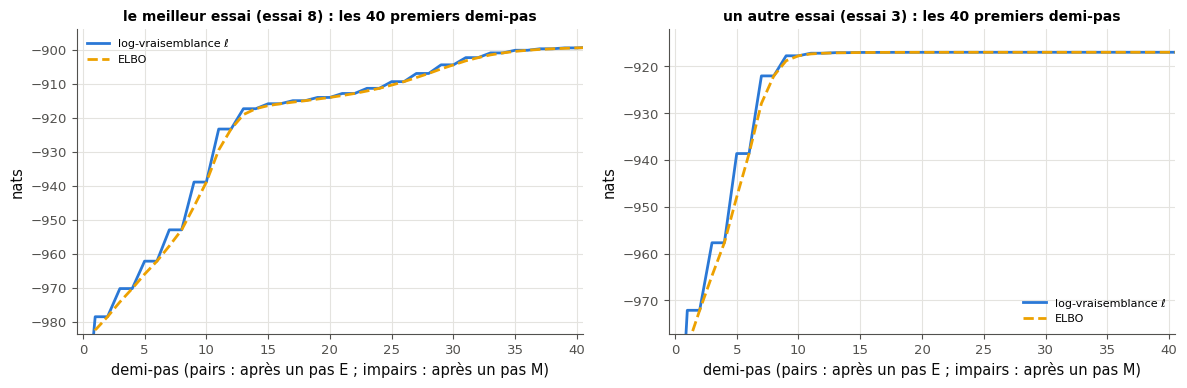

✅ Ex M25b.26 : tes dix essais sont justes, et dessinés.


In [37]:
gmm_e_step, gmm_m_step = mymath.latent.gmm_e_step, mymath.latent.gmm_m_step
gmm_log_likelihood, gmm_elbo = mymath.latent.gmm_log_likelihood, mymath.latent.gmm_elbo


def em_trace_26(X, weights, means, covs, n_iter):
    """n_iter iterations of EM without regularization (your mymath.latent); returns two arrays ll and elbo of length
    2 * n_iter + 1: the log-likelihood and the ELBO after the first E step (the posterior of the starting parameters),
    then after each M step and each E step."""
    resp = gmm_e_step(X, weights, means, covs)
    ll, elbo = [gmm_log_likelihood(X, weights, means, covs)], [gmm_elbo(X, resp, weights, means, covs)]
    for _ in range(n_iter):
        weights, means, covs = gmm_m_step(X, resp)                  # the M step: θ moves, q stays
        ll.append(gmm_log_likelihood(X, weights, means, covs))
        elbo.append(gmm_elbo(X, resp, weights, means, covs))
        resp = gmm_e_step(X, weights, means, covs)                  # the E step: q moves, θ stays
        ll.append(ll[-1])
        elbo.append(gmm_elbo(X, resp, weights, means, covs))
    return np.array(ll), np.array(elbo)


def draw_trace_26(ax, ll, elbo, title):
    """In ax: ll and elbo against the half step 0, 1, ..., len(ll) - 1 (two curves), the title, labels and a legend.
    No other axes."""
    steps = np.arange(len(ll))
    ax.plot(steps, ll, color="C0", label="log-vraisemblance ℓ")
    ax.plot(steps, elbo, color="C3", linestyle="--", label="ELBO")
    ax.set_xlim(-0.5, 40.5)                                         # the first 40 half steps: the staircase
    ax.set_ylim(min(ll[2], elbo[2]) - 5, ll[-1] + 5)
    ax.set_xlabel("demi-pas (pairs : après un pas E ; impairs : après un pas M)")
    ax.set_ylabel("nats")
    ax.set_title(title + " : les 40 premiers demi-pas", fontsize=10)
    ax.legend(fontsize=8)


rng_26 = np.random.default_rng(6060)
runs_26, finals_26, means_26 = [], [], []
for _ in range(10):
    idx_26 = rng_26.choice(len(X_FISH_26), 3, replace=False)
    start_26 = (np.full(3, 1 / 3), X_FISH_26[idx_26], np.full((3, 1, 1), X_FISH_26.var()))
    runs_26.append(em_trace_26(X_FISH_26, *start_26, N_ITER_26))
    params_26 = start_26                                            # the final means, by the same EM
    for _ in range(N_ITER_26):
        params_26 = gmm_m_step(X_FISH_26, gmm_e_step(X_FISH_26, *params_26))
    means_26.append(np.sort(params_26[1].ravel()))
    finals_26.append(runs_26[-1][0][-1] / len(X_FISH_26))
finals_26 = np.array(finals_26)
answer_M25b_26a = all(bool(np.all(elbo[1:] >= elbo[:-1] - 1e-9 * (1 + np.abs(elbo[:-1])))) for _, elbo in runs_26)
answer_M25b_26b = all(bool(np.all(np.abs(elbo[0::2] - ll[0::2]) < 1e-9 * (1 + np.abs(ll[0::2])))) for ll, elbo in runs_26)
best_26 = int(np.argmax(finals_26))
answer_M25b_26c = float(finals_26[best_26])
near_26 = np.abs(finals_26 - answer_M25b_26c) < 1e-3
answer_M25b_26d = int(near_26.sum())
answer_M25b_26e = float(np.mean(finals_26[~near_26]))
answer_M25b_26f = means_26[best_26].tolist()
print("valeurs finales par poisson :", np.round(finals_26, 5).tolist())
print("a)", answer_M25b_26a, " b)", answer_M25b_26b, " c)", round(answer_M25b_26c, 6), " d)", answer_M25b_26d,
      " e)", round(answer_M25b_26e, 5), " f)", np.round(answer_M25b_26f, 4).tolist())
print("moyennes d'un des autres essais :", np.round(means_26[int(np.argmin(finals_26))], 2).tolist())

with checked("M25b.26"):
    results_26 = []
    report_26 = reporter(results_26)
    if not filled(runs_26):
        print("⏳ Ex M25b.26 : la vérification attend tes dix essais runs_26.")
        raise StopCheck

    def trace_c26(X, weights, means, covs, n_iter):
        """The expected (ll, elbo) of EM without regularization, by the reference (the check never uses your code)."""
        resp = ref_latent.gmm_e_step(X, weights, means, covs)
        ll, elbo = [ref_latent.gmm_log_likelihood(X, weights, means, covs)], [ref_latent.gmm_elbo(X, resp, weights, means, covs)]
        for _ in range(n_iter):
            weights, means, covs = ref_latent.gmm_m_step(X, resp)
            ll.append(ref_latent.gmm_log_likelihood(X, weights, means, covs))
            elbo.append(ref_latent.gmm_elbo(X, resp, weights, means, covs))
            resp = ref_latent.gmm_e_step(X, weights, means, covs)
            ll.append(ll[-1])
            elbo.append(ref_latent.gmm_elbo(X, resp, weights, means, covs))
        return np.array(ll), np.array(elbo)

    def starts_c26(ddof=0):
        rng = np.random.default_rng(6060)
        return [(np.full(3, 1 / 3), X_FISH_26[rng.choice(300, 3, replace=False)],
                 np.full((3, 1, 1), X_FISH_26.var(ddof=ddof))) for _ in range(10)]

    first_c26 = starts_c26()[0]
    with own_code("M25b.26", "em_trace_26", REF_LATENT):
        short_c26 = em_trace_26(X_FISH_26.copy(), *(np.copy(v) for v in first_c26), 3)
    short_want_c26 = trace_c26(X_FISH_26, *first_c26, 3)
    got_c26 = pair("M25b.26", "em_trace_26", short_c26, names=("ll", "elbo"))
    if not (matches(got_c26[0], short_want_c26[0], rtol=1e-8) and matches(got_c26[1], short_want_c26[1], rtol=1e-8)):
        swapped_c26 = matches(got_c26[0], short_want_c26[1], rtol=1e-8) and matches(got_c26[1], short_want_c26[0], rtol=1e-8)
        report_26(False, "", "em_trace_26, 3 itérations depuis le premier départ : attendu ll = "
                  f"{shown(short_want_c26[0])} et elbo = {shown(short_want_c26[1])}, reçu {shown(got_c26[0])} et "
                  f"{shown(got_c26[1])}" + (" (ll et elbo échangés)" if swapped_c26 else " : 2 n_iter + 1 valeurs, "
                  "après le premier pas E, puis après chaque pas M et chaque pas E (et tes fonctions passent-elles "
                  "leurs tests ?)"))
    report_26(True, "em_trace_26 : 3 itérations depuis le premier départ, comme attendu", "")
    if not isinstance(runs_26, (list, tuple)) or len(runs_26) != 10:
        report_26(False, "", "runs_26 doit être une liste de 10 couples (ll, elbo), un par initialisation")
    want_c26 = [trace_c26(X_FISH_26, *start, N_ITER_26) for start in starts_c26()]
    try:
        ddof_c26 = trace_c26(X_FISH_26, *starts_c26(ddof=1)[0], N_ITER_26)
        if matches(runs_26[0][0], ddof_c26[0], rtol=1e-7):
            report_26(False, "", "tes variances de départ divisent par n − 1 : X.var() (np.var) divise par n ; ddof=1 "
                      "divise par n − 1")
    except (TypeError, IndexError, ValueError):
        pass
    for j_c26, (want_ll_c26, want_elbo_c26) in enumerate(want_c26):
        try:
            got_ll_c26, got_elbo_c26 = runs_26[j_c26]
        except (TypeError, ValueError):
            report_26(False, "", f"l'essai {j_c26 + 1} de runs_26 doit être un couple (ll, elbo)")
        ok_c26 = matches(got_ll_c26, want_ll_c26, rtol=1e-7) and matches(got_elbo_c26, want_elbo_c26, rtol=1e-7)
        if not ok_c26:
            same("M25b.26", f"l'essai {j_c26 + 1}, ll", got_ll_c26, want_ll_c26, rtol=1e-7)
            same("M25b.26", f"l'essai {j_c26 + 1}, elbo", got_elbo_c26, want_elbo_c26, rtol=1e-7)
            report_26(False, "", f"l'essai {j_c26 + 1} ne suit pas l'EM attendu : les départs se tirent dans l'ordre par "
                      "rng = np.random.default_rng(6060), rng.choice(300, 3, replace=False) pour chacun, trois "
                      "variances X.var(), des poids égaux, n_iter = 100")
    report_26(True, "les dix essais de runs_26 suivent l'EM attendu", "")
    finals_c26 = np.array([ll[-1] for ll, _ in want_c26]) / 300
    best_c26, worst_c26 = int(np.argmax(finals_c26)), int(np.argmin(finals_c26))
    fig_26, axes_26 = plt.subplots(1, 2, figsize=(12, 4))
    try:
        for ax_c26, j_c26, name_c26 in ((axes_26[0], best_c26, "le meilleur essai"), (axes_26[1], worst_c26, "un autre essai")):
            opened_c26 = drawn(draw_trace_26, ax_c26, *want_c26[j_c26], f"{name_c26} (essai {j_c26 + 1})")
            report_26(not opened_c26, f"{name_c26} : draw_trace_26 dessine dans l'axe reçu",
                      f"{name_c26} : draw_trace_26 doit dessiner dans l'axe reçu, sans ouvrir de figure")
            steps_c26 = np.arange(len(want_c26[j_c26][0]))
            report_26(through(ax_c26, steps_c26, want_c26[j_c26][0]) and through(ax_c26, steps_c26, want_c26[j_c26][1]),
                      f"{name_c26} : ll et elbo sont tracées contre le demi-pas",
                      f"{name_c26} : il manque une courbe, ll ou elbo, contre le demi-pas 0, 1, …, {len(steps_c26) - 1}")
    except StopCheck:
        fig_26.tight_layout()
        plt.show()
        raise
    except BaseException:
        plt.close(fig_26)
        raise
    fig_26.tight_layout()
    plt.show()
    verdict("M25b.26", all(results_26), "tes dix essais sont justes, et dessinés.", "")

In [38]:
def em_26r(x, weights, means, variances, n_iter):
    """EM in dimension 1 by SciPy and np.average / np.cov(aweights, bias=True): the trace (ll, elbo) and the final means."""
    def log_joint(w, m, v):
        return np.log(w) + stats.norm(m, np.sqrt(v)).logpdf(x[:, None])

    def posterior(a):
        return np.exp(a - special.logsumexp(a, axis=1, keepdims=True))

    def elbo(R, a):
        return float(np.sum(R * a) + np.sum(special.entr(R)))

    a = log_joint(weights, means, variances)
    R = posterior(a)
    lls, elbos = [float(np.sum(special.logsumexp(a, axis=1)))], [elbo(R, a)]
    for _ in range(n_iter):
        weights = R.mean(axis=0)
        means = np.array([np.average(x, weights=R[:, k]) for k in range(R.shape[1])])
        variances = np.array([np.cov(x, aweights=R[:, k], bias=True) for k in range(R.shape[1])])
        a = log_joint(weights, means, variances)
        lls.append(float(np.sum(special.logsumexp(a, axis=1))))
        elbos.append(elbo(R, a))
        R = posterior(a)
        lls.append(lls[-1])
        elbos.append(elbo(R, a))
    return np.array(lls), np.array(elbos), np.sort(means)


rng_26r = np.random.default_rng(6056)
z_26r = rng_26r.choice(3, size=300, p=(0.5, 0.3, 0.2))
x_26r = np.empty(300)
for k in range(3):
    rows = np.flatnonzero(z_26r == k)
    x_26r[rows] = (12.0, 20.0, 28.0)[k] + (1.5, 2.0, 2.5)[k] * np.random.default_rng(6057 + k).standard_normal(len(rows))
starts_26r = np.random.default_rng(6060)
traces_26r = [em_26r(x_26r, np.full(3, 1 / 3), x_26r[starts_26r.choice(300, 3, replace=False)], np.full(3, x_26r.var()), 100)
              for _ in range(10)]
finals_26r = np.array([t[0][-1] / 300 for t in traces_26r])
best_26r = int(np.argmax(finals_26r))
near_26r = np.abs(finals_26r - finals_26r[best_26r]) < 1e-3
wbm.record("M25b.26a", all(bool(np.all(e[1:] >= e[:-1] - 1e-9 * (1 + np.abs(e[:-1])))) for _, e, _ in traces_26r),
           mistakes={"sans régularisation, aucun demi-pas ne fait baisser l'ELBO : une « baisse » de l'ordre de l'arrondi "
                     "reste sous la tolérance": False})
wbm.record("M25b.26b", all(bool(np.all(np.abs(e[0::2] - l[0::2]) < 1e-9 * (1 + np.abs(l[0::2])))) for l, e, _ in traces_26r),
           mistakes={"après le pas E, q est le posterior : l'ELBO égale la log-vraisemblance, à l'arrondi près": False})
wbm.record("M25b.26c", float(finals_26r[best_26r]), decimals=4,
           mistakes={"par poisson : divise la log-vraisemblance par n = 300": float(finals_26r[best_26r] * 300),
                     "la meilleure valeur est la plus grande log-vraisemblance, la moins négative":
                         float(finals_26r.min())})
wbm.record("M25b.26d", int(near_26r.sum()),
           mistakes={"compte tous les essais proches de la meilleure valeur, le meilleur compris": int(near_26r.sum()) - 1,
                     "compte les essais proches de la meilleure valeur, pas les autres": int((~near_26r).sum())})
wbm.record("M25b.26e", float(np.mean(finals_26r[~near_26r])), decimals=2,
           mistakes={"par poisson : divise la log-vraisemblance par n = 300": float(np.mean(finals_26r[~near_26r]) * 300),
                     "e) demande la valeur des autres essais, pas celle du meilleur": float(finals_26r[best_26r])})
wbm.record("M25b.26f", traces_26r[best_26r][2].tolist(), decimals=2)

WBM_ANSWER {"hash": "2138692c27c2fac6cacd376cde1849afd9f0bd1294cd02b0237cfd03db6771d3", "id": "M25b.26a", "kind": "bool", "mistakes": {"026826568646ef864076013a94c647e3dc5a88525e2036995e78ae8652d52a40": "sans régularisation, aucun demi-pas ne fait baisser l'ELBO : une « baisse » de l'ordre de l'arrondi reste sous la tolérance"}}
📝 Ex M25b.26a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "3e7799926ceff1efa33e22f2278d015dbe74f16aa36738b3e547a0026075b532", "id": "M25b.26b", "kind": "bool", "mistakes": {"9dc412049b837dc5dd561cb73c1ab14e1e88722c923ed522185e5b087343b9cb": "après le pas E, q est le posterior : l'ELBO égale la log-vraisemblance, à l'arrondi près"}}
📝 Ex M25b.26b : réponse enregistrée (bool).
WBM_ANSWER {"coarse_any": {"0": ["4057d535a3b4ec0a45f3662e55d7dc5ec250b255ffccbdec83da3d59194a3570"]}, "coarser": {"1": ["5ef87f4f40968891980f2053d2a208f04e505b4a333315ebe5e3a025b341387b"], "2": ["06597e46b19a1b10ff6b0f62492f51ce08293df7ead6e964047495bd230ee44e"]}, "decimals": 4, "has

**Après la figure**, dans ta copie : sur la courbe, où l'ELBO touche-t-elle la log-vraisemblance, et pourquoi l'escalier ne descend-il jamais ? Que font les deux composantes du haut dans les essais moins bons ? Combien d'initialisations faudrait-il pour être presque sûr de trouver le meilleur point ?

💡 a) Vrai (la plus forte baisse relative est de l'ordre de $10^{-16}$, l'arrondi). b) Vrai (écart maximal $\approx 2 \times 10^{-13}$). c) $-2{,}9960$. d) 7 essais sur 10. e) $-3{,}06$ pour les trois autres : deux composantes s'y partagent les cohortes de 2 et 3 ans (moyennes vers 22 et 23 cm), et l'EM ne les sépare que très lentement. f) $(11{,}9 ;\ 20{,}0 ;\ 27{,}9)$, avec les poids $(0{,}479 ;\ 0{,}295 ;\ 0{,}226)$.

### Ex M25b.27 — Une gaussienne ajustée à un mélange bimodal par KL(p ‖ q) puis par KL(q ‖ p) : les deux courbes, et les deux minima de la KL inverse 🎨 ★ ⏱️ 20 min
**Objectif :** voir, sur un mélange bimodal, que la KL directe apparie les moments et que la KL inverse se pose sur une bosse.  
**Prérequis :** fiche §7 ; M25a ; Ex M25b.13 · **Parcours :** C

Écris `draw_kl_fits_27(ax_density, ax_kl, weights, means, variances)`, qui dessine sur les **axes reçus** (sans ouvrir de figure) :
- dans `ax_density`, sur $[0, 60]$ min (au moins 50 points), la densité $p$ du mélange (les temps de trajet de M25b.13 : `WEIGHTS_27`, `MEANS_27`, `VARIANCES_27`), la gaussienne $q_\star$ des moments, et les gaussiennes $q_1$ et $q_2$ des deux composantes, avec une légende ;
- dans `ax_kl`, pour $m$ de 10 à 55 par pas de 0,25 (`MS_27`), la KL inverse $m \mapsto \mathrm{KL}(\mathcal{N}(m, 4) \,\|\, p)$ (4 est la variance `variances[0]` de $q_1$) et la KL directe $m \mapsto \mathrm{KL}(p \,\|\, \mathcal{N}(m, \mathbb{V}_p(X)))$, calculées sur la grille de $x$ de $-30$ à 100 (260 001 points, `XS_KL_27`) par `np.trapezoid`, avec $\ln p$ par un log-sum-exp (les densités elles-mêmes sortiraient des flottants loin des bosses).

Appelle-la sur une figure de deux panneaux. Relève :
- a) les abscisses des minima locaux de la KL inverse sur la grille `MS_27` (une liste de 2 nombres ; 1 décimale dans ta copie) ;
- b) leurs valeurs (une liste de 2 nombres ; 3 décimales dans ta copie) ;
- c) $\mathrm{KL}(p \,\|\, q_\star)$ (4 décimales dans ta copie) ;
- d) $\mathrm{KL}(q_\star \,\|\, p)$ (2 décimales dans ta copie) ;
- e) vrai ou faux : $\mathrm{KL}(q_\star \,\|\, p)$ dépasse les deux minima de a).

Puis minimise $\mathrm{KL}(\mathcal{N}(m, s^2) \,\|\, p)$ en $(m, \ln s^2)$ par `scipy.optimize.minimize`, depuis $(22, \ln 4)$ et depuis $(40, \ln 6{,}25)$, et compare les deux minima à tes réponses c) et d) de M25b.13 (dans ta copie). La vérification appelle ta fonction pour les temps de trajet, puis pour un mélange que tu ne vois pas, et regarde chaque dessin. Ce qu'il faut observer : la KL inverse a un minimum par itinéraire, le plus bas sur la bosse la plus lourde ; la KL directe n'en a qu'un, entre les bosses, là où $p$ est presque nulle.

In [39]:
WEIGHTS_27 = np.array([0.7, 0.3])                         # the travel times of M25b.13 (min): the ring road, the centre
MEANS_27 = np.array([22.0, 40.0])
VARIANCES_27 = np.array([4.0, 6.25])
MS_27 = np.arange(10.0, 55.0 + 1e-9, 0.25)                 # the means m of the two KL curves: 10, 10.25, ..., 55
XS_KL_27 = np.linspace(-30.0, 100.0, 260001)               # the grid of x of the integrals (np.trapezoid)

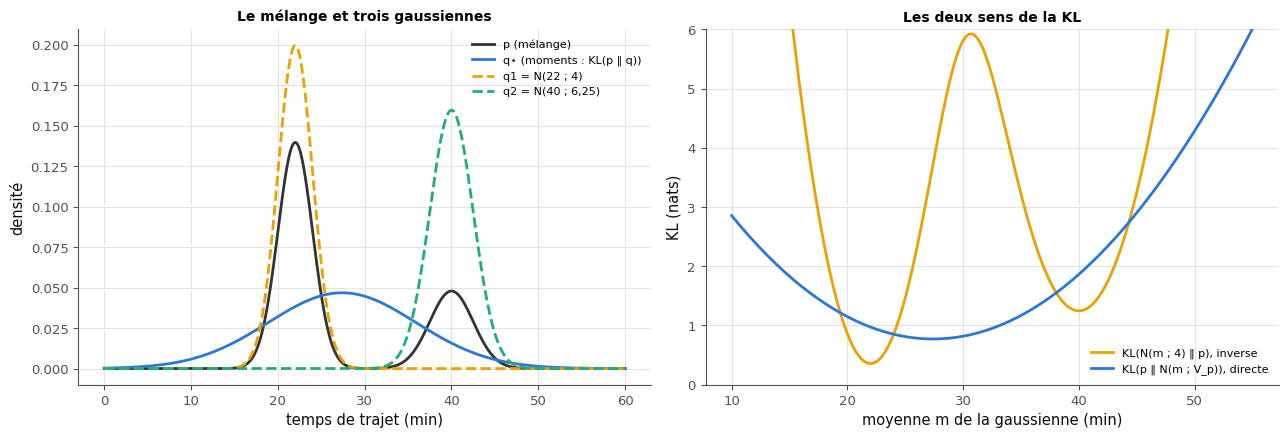

a) [22.0, 40.0]  b) [0.35662, 1.24711]  c) 0.772402  d) 2.40923  e) True


depuis 22 : m = 22,0004, s² = 4,0036, KL = 0,35662


depuis 40 : m = 39,9984, s² = 6,2661, KL = 1,20382
ln(10/7) ≈ 0.35667 ; ln(10/3) ≈ 1.20397


✅ draw_kl_fits_27 dessine dans les axes reçus


✅ les quatre densités et les deux courbes de KL sont là


✅ un mélange que tu ne vois pas (d'autres poids, d'autres moyennes) est dessiné juste aussi


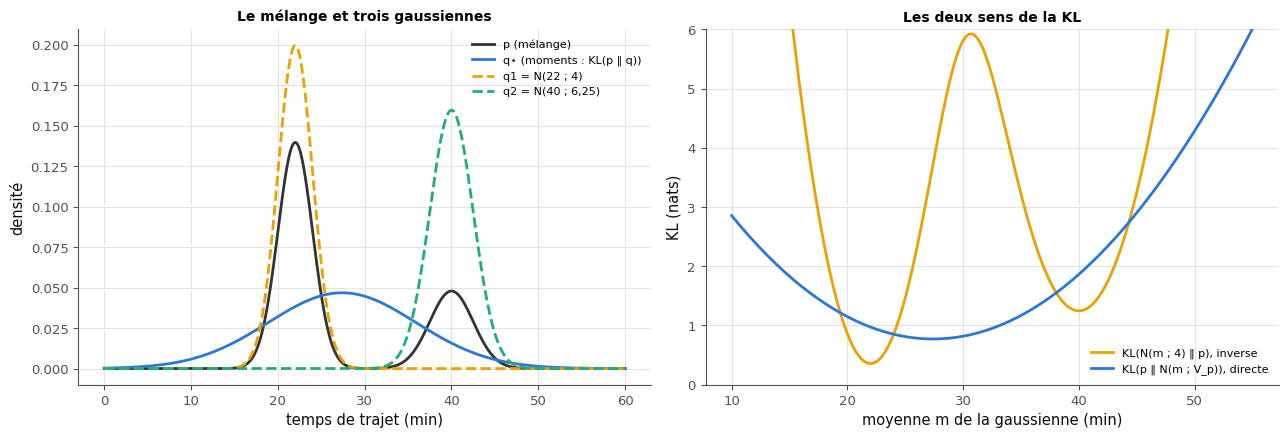

✅ Ex M25b.27 : les densités et les deux sens de la KL sont dessinés.


In [40]:
def log_mixture_27(x, weights, means, variances):
    """ln p(x) of a mixture of normal laws in dimension 1, by a log-sum-exp (x a 1-D array)."""
    log_terms = np.log(weights) - 0.5 * np.log(2 * np.pi * variances) - (x[:, None] - means) ** 2 / (2 * variances)
    return special.logsumexp(log_terms, axis=1)


def log_normal_27(x, m, s2):
    return -0.5 * np.log(2 * np.pi * s2) - (x - m) ** 2 / (2 * s2)


def moments_27(weights, means, variances):
    mean = float(weights @ means)
    return mean, float(weights @ variances + weights @ (means - mean) ** 2)


def kl_q_p_27(m, s2, log_p):
    """KL(N(m, s2) ‖ p) on the grid XS_KL_27."""
    log_q = log_normal_27(XS_KL_27, m, s2)
    return float(np.trapezoid(np.exp(log_q) * (log_q - log_p), XS_KL_27))


def kl_p_q_27(m, s2, log_p):
    """KL(p ‖ N(m, s2)) on the grid XS_KL_27."""
    return float(np.trapezoid(np.exp(log_p) * (log_p - log_normal_27(XS_KL_27, m, s2)), XS_KL_27))


def kl_curves_27(weights, means, variances):
    log_p = log_mixture_27(XS_KL_27, weights, means, variances)
    var_p = moments_27(weights, means, variances)[1]
    return (np.array([kl_q_p_27(m, variances[0], log_p) for m in MS_27]),
            np.array([kl_p_q_27(m, var_p, log_p) for m in MS_27]))


def draw_kl_fits_27(ax_density, ax_kl, weights, means, variances):
    """In ax_density, on [0, 60] (at least 50 points): the density p of the mixture, the Gaussian q* of its moments, and
    the Gaussians q1 and q2 of its components, with a legend; in ax_kl, against MS_27: the reverse KL
    m ↦ KL(N(m, variances[0]) ‖ p) and the forward KL m ↦ KL(p ‖ N(m, V_p)), by np.trapezoid on XS_KL_27, ln p by a
    log-sum-exp; labels and a legend. No other axes."""
    weights, means, variances = (np.asarray(v, dtype=float) for v in (weights, means, variances))
    xs = np.linspace(0.0, 60.0, 601)
    mean_p, var_p = moments_27(weights, means, variances)
    ax_density.plot(xs, np.exp(log_mixture_27(xs, weights, means, variances)), color="0.2", linewidth=2, label="p (mélange)")
    ax_density.plot(xs, np.exp(log_normal_27(xs, mean_p, var_p)), color="C0", label="q⋆ (moments : KL(p ‖ q))")
    for k, color in ((0, "C3"), (1, "C2")):
        ax_density.plot(xs, np.exp(log_normal_27(xs, means[k], variances[k])), color=color, linestyle="--",
                        label=f"q{k + 1} = N({means[k]:g} ; {variances[k]:g})".replace(".", ","))
    ax_density.set_xlabel("temps de trajet (min)")
    ax_density.set_ylabel("densité")
    ax_density.set_title("Le mélange et trois gaussiennes", fontsize=10)
    ax_density.legend(fontsize=8)
    reverse, forward = kl_curves_27(weights, means, variances)
    ax_kl.plot(MS_27, reverse, color="C3", label=f"KL(N(m ; {variances[0]:g}) ‖ p), inverse".replace(".", ","))
    ax_kl.plot(MS_27, forward, color="C0", label="KL(p ‖ N(m ; V_p)), directe")
    ax_kl.set_xlabel("moyenne m de la gaussienne (min)")
    ax_kl.set_ylabel("KL (nats)")
    ax_kl.set_ylim(0, 6)
    ax_kl.set_title("Les deux sens de la KL", fontsize=10)
    ax_kl.legend(fontsize=8)


fig_27s, axes_27s = plt.subplots(1, 2, figsize=(13, 4.5))
draw_kl_fits_27(axes_27s[0], axes_27s[1], WEIGHTS_27, MEANS_27, VARIANCES_27)
fig_27s.tight_layout()
plt.show()
reverse_27, forward_27 = kl_curves_27(WEIGHTS_27, MEANS_27, VARIANCES_27)
minima_27 = [i for i in range(1, len(MS_27) - 1) if reverse_27[i] < reverse_27[i - 1] and reverse_27[i] < reverse_27[i + 1]]
answer_M25b_27a = [float(MS_27[i]) for i in minima_27]
answer_M25b_27b = [float(reverse_27[i]) for i in minima_27]
log_p_27 = log_mixture_27(XS_KL_27, WEIGHTS_27, MEANS_27, VARIANCES_27)
mean_star_27, var_star_27 = moments_27(WEIGHTS_27, MEANS_27, VARIANCES_27)
answer_M25b_27c = kl_p_q_27(mean_star_27, var_star_27, log_p_27)
answer_M25b_27d = kl_q_p_27(mean_star_27, var_star_27, log_p_27)
answer_M25b_27e = bool(answer_M25b_27d > max(answer_M25b_27b))
print("a)", answer_M25b_27a, " b)", np.round(answer_M25b_27b, 5).tolist(), " c)", round(answer_M25b_27c, 6),
      " d)", round(answer_M25b_27d, 5), " e)", answer_M25b_27e)
for start_27 in ((22.0, math.log(4.0)), (40.0, math.log(6.25))):
    fit_27 = optimize.minimize(lambda t: kl_q_p_27(t[0], math.exp(t[1]), log_p_27), start_27, method="Nelder-Mead",
                               options={"xatol": 1e-8, "fatol": 1e-11})
    print(f"depuis {start_27[0]:g} : m = {fit_27.x[0]:.4f}, s² = {math.exp(fit_27.x[1]):.4f}, KL = {fit_27.fun:.5f}".replace(".", ","))
print("ln(10/7) ≈", round(math.log(10 / 7), 5), "; ln(10/3) ≈", round(math.log(10 / 3), 5))

def curves_c27(weights, means, variances):
    """The expected curves on MS_27, by SciPy on the grid XS_KL_27: KL(N(m, variances[0]) ‖ p) and KL(p ‖ N(m, V_p))."""
    weights, means, variances = (np.asarray(v, dtype=float) for v in (weights, means, variances))
    log_p = special.logsumexp(np.log(weights) + stats.norm(means, np.sqrt(variances)).logpdf(XS_KL_27[:, None]), axis=1)
    mean_p = weights @ means
    var_p = weights @ variances + weights @ (means - mean_p) ** 2
    reverse, forward = [], []
    for m in MS_27:
        log_q = stats.norm(m, math.sqrt(variances[0])).logpdf(XS_KL_27)
        reverse.append(np.trapezoid(np.exp(log_q) * (log_q - log_p), XS_KL_27))
        forward.append(np.trapezoid(np.exp(log_p) * (log_p - stats.norm(m, math.sqrt(var_p)).logpdf(XS_KL_27)), XS_KL_27))
    return np.array(reverse), np.array(forward)


def look_27(ax_density, ax_kl, weights, means, variances):
    """What is wrong in a drawing of draw_kl_fits_27: a list of French phrases, empty when all is there."""
    weights, means, variances = (np.asarray(v, dtype=float) for v in (weights, means, variances))
    mean_p = weights @ means
    var_p = weights @ variances + weights @ (means - mean_p) ** 2
    densities = {"la densité p du mélange": lambda x: np.exp(special.logsumexp(
                     np.log(weights) + stats.norm(means, np.sqrt(variances)).logpdf(x[:, None]), axis=1)),
                 "la gaussienne q⋆ des moments": lambda x: stats.norm(mean_p, math.sqrt(var_p)).pdf(x),
                 "la gaussienne q₁": lambda x: stats.norm(means[0], math.sqrt(variances[0])).pdf(x),
                 "la gaussienne q₂": lambda x: stats.norm(means[1], math.sqrt(variances[1])).pdf(x)}
    missing = []
    for name, density in densities.items():
        if not any(line_points(line)[0].size >= 50 and line_points(line)[0].min() <= 1e-9
                   and line_points(line)[0].max() >= 60 - 1e-9
                   and np.allclose(line_points(line)[1], density(line_points(line)[0]), rtol=1e-6, atol=1e-12)
                   for line in ax_density.lines):
            missing.append(f"il manque {name} sur [0, 60] (au moins 50 points)")
    if ax_density.get_legend() is None:
        missing.append("il manque la légende du panneau des densités")
    reverse, forward = curves_c27(weights, means, variances)
    for name, curve in (("la KL inverse m ↦ KL(N(m, variances[0]) ‖ p)", reverse),
                        ("la KL directe m ↦ KL(p ‖ N(m, V_p))", forward)):
        if not through(ax_kl, MS_27, curve, rtol=1e-6, atol=1e-7):
            missing.append(f"il manque {name} contre MS_27 (np.trapezoid sur XS_KL_27, ln p par un log-sum-exp)")
    return missing


with checked("M25b.27"):
    results_27 = []
    report_27 = reporter(results_27)
    fig_27, (density_27, kl_27) = plt.subplots(1, 2, figsize=(13, 4.5))
    try:
        opened_27 = drawn(draw_kl_fits_27, density_27, kl_27, WEIGHTS_27.copy(), MEANS_27.copy(), VARIANCES_27.copy())
        report_27(not opened_27, "draw_kl_fits_27 dessine dans les axes reçus",
                  "draw_kl_fits_27 doit dessiner dans les deux axes reçus, sans ouvrir de figure")
        missing_27 = look_27(density_27, kl_27, WEIGHTS_27, MEANS_27, VARIANCES_27)
        report_27(not missing_27, "les quatre densités et les deux courbes de KL sont là", " ; ".join(missing_27))
        hidden_27 = (np.array([0.6, 0.4]), np.array([18.0, 37.0]), np.array([4.0, 6.25]))   # a mixture you do not see
        fig_c27, (density_c27, kl_c27) = plt.subplots(1, 2)
        try:
            opened_c27 = drawn(draw_kl_fits_27, density_c27, kl_c27, *(v.copy() for v in hidden_27))
            missing_c27 = look_27(density_c27, kl_c27, *hidden_27)
        finally:
            plt.close(fig_c27)
        report_27(not opened_c27 and not missing_c27, "un mélange que tu ne vois pas (d'autres poids, d'autres moyennes) "
                  "est dessiné juste aussi", "un mélange que tu ne vois pas (d'autres poids, d'autres moyennes) : "
                  + " ; ".join(missing_c27 or ["draw_kl_fits_27 doit dessiner dans les axes reçus, sans ouvrir de figure"]))
    except StopCheck:
        fig_27.tight_layout()
        plt.show()
        raise
    except BaseException:
        plt.close(fig_27)
        raise
    fig_27.tight_layout()
    plt.show()
    verdict("M25b.27", all(results_27), "les densités et les deux sens de la KL sont dessinés.", "")

In [41]:
x_27r = np.linspace(-30.0, 100.0, 260001)
w_27r, m_27r, v_27r = np.array([0.7, 0.3]), np.array([22.0, 40.0]), np.array([4.0, 6.25])
log_p_27r = special.logsumexp(np.log(w_27r) + stats.norm(m_27r, np.sqrt(v_27r)).logpdf(x_27r[:, None]), axis=1)
mean_27r = float(w_27r @ m_27r)
var_27r = float(w_27r @ v_27r + w_27r @ (m_27r - mean_27r) ** 2)


def kl_27r(m, s2, reverse=True):
    log_q = stats.norm(m, math.sqrt(s2)).logpdf(x_27r)
    if reverse:
        return float(np.trapezoid(np.exp(log_q) * (log_q - log_p_27r), x_27r))
    return float(np.trapezoid(np.exp(log_p_27r) * (log_p_27r - log_q), x_27r))


ms_27r = np.arange(10.0, 55.0 + 1e-9, 0.25)
reverse_27r = np.array([kl_27r(m, 4.0) for m in ms_27r])
forward_27r = np.array([kl_27r(m, var_27r, reverse=False) for m in ms_27r])
local_27r = [i for i in range(1, len(ms_27r) - 1) if reverse_27r[i] < reverse_27r[i - 1] and reverse_27r[i] < reverse_27r[i + 1]]
wbm.record("M25b.27a", [float(ms_27r[i]) for i in local_27r], decimals=1,
           mistakes={"les minima demandés sont ceux de la KL inverse, KL(N(m, 4) ‖ p) : un par bosse":
                         [float(ms_27r[int(np.argmin(forward_27r))])]})
wbm.record("M25b.27b", [float(reverse_27r[i]) for i in local_27r], decimals=3,
           mistakes={"les KL se comptent en nats, avec le logarithme népérien":
                         [float(reverse_27r[i]) / math.log(2) for i in local_27r]})
kl_pq_27r, kl_qp_27r = kl_27r(mean_27r, var_27r, reverse=False), kl_27r(mean_27r, var_27r)
wbm.record("M25b.27c", kl_pq_27r, decimals=4,
           mistakes={"KL(p ‖ q⋆) prend l'espérance sous p, la première loi": kl_qp_27r,
                     "q⋆ a la variance du mélange (M25b.13 a)), pas la moyenne des variances des composantes":
                         kl_27r(mean_27r, float(w_27r @ v_27r), reverse=False)})
wbm.record("M25b.27d", kl_qp_27r, decimals=2,
           mistakes={"KL(q⋆ ‖ p) prend l'espérance sous q⋆, la première loi": kl_pq_27r})
wbm.record("M25b.27e", bool(kl_qp_27r > reverse_27r[local_27r].max()),
           mistakes={"compare KL(q⋆ ‖ p) aux deux minima de a), en nats": False})

WBM_ANSWER {"decimals": 1, "element_hashes": ["2c3ca5c411694a21aa2513746f317e8aaa5fbc23bde8968b7b7ff977e9dbd4ad", "16ff519dde5d3db61a56dfee72f39f90b286a2e462a2feb277fdd213a7806004"], "hash": "94693ff1eadd8dc54d9265721ee89f1f2ba8fdf00b36f94b34cea97de26ca581", "id": "M25b.27a", "kind": "array", "mistakes": {"eb0f3cb58714ac2bea13f10bace09093df4800a3db8c9843062bc1a2e905555c": "les minima demandés sont ceux de la KL inverse, KL(N(m, 4) ‖ p) : un par bosse"}, "shape": [2]}
📝 Ex M25b.27a : réponse enregistrée (array, 1 décimale).
WBM_ANSWER {"decimals": 3, "element_coarse": [["5ee19ba8f3d85094740d81a92825022a2d1f02f1d3639de897755f13f6ee6480"], ["d28e22d0d6817e153497acfd0f2f3ea60ce68a9a38af5e5c2215e51a350838fc"]], "element_coarse_any": [["52ef7d486b4ee7eb1bd3077c67d80218015d49a718f99ce7c851fa7ee61b3b09"], ["17f88619f2fad8f523ce8cdca157c0a7ed6ef4e7b80fd24e919a092ea73dab1d", "4b3032d6d038f9b61224b51dc680d1b0f99254fa10290be0482fcaf93fab96a3"]], "element_hashes": ["5efb44bd29aac7730d5bc142b7135273

**Après la figure**, dans ta copie : pourquoi la KL inverse a-t-elle deux minima et la KL directe un seul ? Où se trouve $q_\star$ par rapport aux bosses, et que vaut $p$ à cet endroit ? Laquelle des deux approximations choisirais-tu pour prévoir un temps de trajet typique, et laquelle pour ne jamais sous-estimer un retard ?

💡 a) 22,0 et 40,0. b) 0,357 et 1,247 (avec la variance 4, la gaussienne posée sur le centre-ville est trop étroite pour sa bosse). c) $0{,}7724$. d) $2{,}41$. e) Vrai. Les minima en $(m, s^2)$ : $(22{,}00 ;\ 4{,}00)$, de valeur $0{,}3566$, et $(40{,}00 ;\ 6{,}27)$, de valeur $1{,}2038$, à moins de $10^{-4}$ de $\ln\frac{10}{7}$ et à $2 \times 10^{-4}$ de $\ln\frac{10}{3}$ (M25b.13 c) et d)).

## Partie C · Déboguer, tester

Fiche §3, §4 et §5. Trois erreurs classiques des mélanges, qui passent une vérification mal choisie ; un test de propriété de l'EM. Les données et les vérifications s'appuient sur la référence (`ref_gauss`, `ref_latent`), pour ne pas dépendre de ton code.

### Ex M25b.28 — Chasse à l'erreur : des responsabilités sans log qui donnent 0/0, un pas M qui divise par n au lieu de N_k, et une ELBO sans l'entropie de q 🐛 ★ ⏱️ 20 min
**Objectif :** reconnaître trois erreurs classiques des mélanges qui passent une vérification mal choisie, puis les corriger.  
**Prérequis :** fiche §3, §4 et §5 ; Ex M25b.3, M25b.20 à M25b.22 · **Parcours :** C, E

Un collègue a écrit trois fonctions pour des mesures en dimension 1 (`x` est un tableau 1-D, `sds` les **écarts-types**), chacune accompagnée d'une vérification qui passe (cellule fournie) :
1. `machine_shares(x, weights, means, sds)` doit rendre les responsabilités, de forme $(n, K)$ ; elle calcule chaque $\pi_k\,\mathcal{N}(x_i \mid \mu_k, \sigma_k^2)$ par `np.exp`, puis divise chaque ligne par sa somme. Il l'a vérifiée sur les quatre résistances de M25b.3 (paramètres de départ, `sds` = les racines de 1 et 2,5) : chaque ligne a pour somme 1 et toutes les valeurs sont dans $[0, 1]$. Il l'applique au bac qui contient aussi la résistance de 120 Ω (`X_BIN_28`).
2. `refit_machines(x, resp)` doit rendre le pas M, `(weights, means, variances)` ; elle calcule les poids $N_k/n$, les moyennes $\frac{1}{N_k}\sum_ir_{ik}x_i$, puis les variances $\frac1n\sum_ir_{ik}(x_i - \mu_k)^2$. Il l'a vérifiée avec une seule composante (une colonne de 1) : elle rend bien `np.mean(x)` et `np.var(x)`.
3. `bound_of_evidence(x, resp, weights, means, sds)` doit rendre l'ELBO ; elle rend $\sum_i\sum_kr_{ik}\big(\ln\pi_k + \ln\mathcal{N}(x_i \mid \mu_k, \sigma_k^2)\big)$. Il l'a vérifiée sur 200 tableaux de responsabilités tirés au hasard (`np.random.default_rng(6066).dirichlet`) : elle reste toujours sous la log-vraisemblance des quatre résistances.

À faire : trouve et corrige chaque erreur ; les fonctions corrigées s'appellent `machine_shares_fixed`, `refit_machines_fixed` et `bound_of_evidence_fixed`, avec les mêmes arguments (sans SciPy, et sans jamais calculer $0/0$ ni $\ln 0$). Puis réponds :
- a) vrai ou faux : la dernière ligne que rend `machine_shares` pour les cinq résistances contient des `nan` ;
- b) cette ligne, par `machine_shares_fixed` (une liste de 2 nombres ; 4 décimales dans ta copie) ;
- c) les variances que rend `refit_machines` pour les quatre résistances, avec les responsabilités de `machine_shares_fixed` (une liste de 2 nombres ; 3 décimales dans ta copie) ;
- d) `bound_of_evidence` au posterior (les responsabilités de `machine_shares_fixed`) moins la log-vraisemblance, pour les quatre résistances (4 décimales dans ta copie).

Pour chacune des trois erreurs, dis aussi, dans ta copie, pourquoi la vérification du collègue ne la voyait pas. La vérification essaie tes corrections sur des cas que tu ne vois pas : des mélanges de 2 à 4 composantes, des mesures très loin de toutes les composantes, des responsabilités quelconques, et des lignes qui contiennent des zéros.

In [42]:
X_RES_28 = np.array([46.0, 48.0, 49.4, 52.1])             # the four resistors of M25b.3 (Ω): a 1-D array here
X_BIN_28 = np.append(X_RES_28, 120.0)                      # the bin, with the stray resistor of 120 Ω
WEIGHTS_28, MEANS_28 = np.array([0.45, 0.55]), np.array([47.0, 51.0])
SDS_28 = np.sqrt(np.array([1.0, 2.5]))                     # the STANDARD DEVIATIONS of the two series


# The colleague's code
def machine_shares(x, weights, means, sds):
    """The responsibilities (n, K) of a mixture of normal laws in dimension 1 (x 1-D, sds the standard deviations)."""
    x = np.asarray(x, dtype=float)[:, None]
    dens = weights * np.exp(-(x - means) ** 2 / (2 * sds ** 2)) / (sds * np.sqrt(2 * np.pi))
    return dens / dens.sum(axis=1, keepdims=True)


def refit_machines(x, resp):
    """The M step in dimension 1: (weights, means, variances), each of shape (K,)."""
    x, resp = np.asarray(x, dtype=float)[:, None], np.asarray(resp, dtype=float)
    n, N = len(x), resp.sum(axis=0)
    means = (resp * x).sum(axis=0) / N
    return N / n, means, (resp * (x - means) ** 2).sum(axis=0) / n


def bound_of_evidence(x, resp, weights, means, sds):
    """The ELBO of the mixture for the laws q_i given by the rows of resp."""
    x, resp = np.asarray(x, dtype=float)[:, None], np.asarray(resp, dtype=float)
    log_dens = -np.log(sds * np.sqrt(2 * np.pi)) - (x - means) ** 2 / (2 * sds ** 2)
    return float(np.sum(resp * (np.log(weights) + log_dens)))


# The colleague's checks: all pass
R_check_28 = machine_shares(X_RES_28, WEIGHTS_28, MEANS_28, SDS_28)
print("(1) quatre résistances : lignes de somme 1 :", bool(np.allclose(R_check_28.sum(axis=1), 1)),
      "; valeurs dans [0, 1] :", bool(np.all((R_check_28 >= 0) & (R_check_28 <= 1))), "(attendu True, True)")
one_28 = refit_machines(X_RES_28, np.ones((4, 1)))
print("(2) une seule composante : np.mean :", bool(np.isclose(one_28[1][0], np.mean(X_RES_28))), "; np.var :",
      bool(np.isclose(one_28[2][0], np.var(X_RES_28))), "(attendu True, True)")
dens_check_28 = WEIGHTS_28 * np.exp(-(X_RES_28[:, None] - MEANS_28) ** 2 / (2 * SDS_28 ** 2)) / (SDS_28 * np.sqrt(2 * np.pi))
loglik_check_28 = float(np.sum(np.log(dens_check_28.sum(axis=1))))     # the log-likelihood of the four resistors
rng_check_28 = np.random.default_rng(6066)
below_28 = all(bound_of_evidence(X_RES_28, rng_check_28.dirichlet(np.ones(2), size=4), WEIGHTS_28, MEANS_28, SDS_28)
               <= loglik_check_28 for _ in range(200))
print("(3) 200 tableaux tirés au hasard : ELBO sous la log-vraisemblance :", below_28, "(attendu True)")

(1) quatre résistances : lignes de somme 1 : True ; valeurs dans [0, 1] : True (attendu True, True)
(2) une seule composante : np.mean : True ; np.var : True (attendu True, True)
(3) 200 tableaux tirés au hasard : ELBO sous la log-vraisemblance : True (attendu True)


In [43]:
def machine_shares_fixed(x, weights, means, sds):
    """The responsibilities (n, K) of a mixture of normal laws in dimension 1 (x 1-D, sds the standard deviations)."""
    x = np.asarray(x, dtype=float)[:, None]
    a = np.log(weights) - np.log(sds * np.sqrt(2 * np.pi)) - (x - means) ** 2 / (2 * sds ** 2)   # in logarithms
    m = a.max(axis=1, keepdims=True)
    return np.exp(a - m - np.log(np.exp(a - m).sum(axis=1, keepdims=True)))                   # a − logsumexp


def refit_machines_fixed(x, resp):
    """The M step in dimension 1: (weights, means, variances), each of shape (K,)."""
    x, resp = np.asarray(x, dtype=float)[:, None], np.asarray(resp, dtype=float)
    n, N = len(x), resp.sum(axis=0)
    means = (resp * x).sum(axis=0) / N
    return N / n, means, (resp * (x - means) ** 2).sum(axis=0) / N                            # divided by N_k


def bound_of_evidence_fixed(x, resp, weights, means, sds):
    """The ELBO of the mixture for the laws q_i given by the rows of resp (0 ln 0 counts for 0): a float."""
    x, resp = np.asarray(x, dtype=float)[:, None], np.asarray(resp, dtype=float)
    a = np.log(weights) - np.log(sds * np.sqrt(2 * np.pi)) - (x - means) ** 2 / (2 * sds ** 2)
    log_q = np.log(np.where(resp > 0, resp, 1.0))                                              # never ln 0
    return float(np.sum(np.where(resp > 0, resp * (a - log_q), 0.0)))                          # + the entropy of q


with np.errstate(divide="ignore", invalid="ignore"):          # the WRONG version gives 0/0 for 120 Ω
    wrong_row_28 = machine_shares(X_BIN_28, WEIGHTS_28, MEANS_28, SDS_28)[-1]
answer_M25b_28a = bool(np.isnan(wrong_row_28).any())
answer_M25b_28b = machine_shares_fixed(X_BIN_28, WEIGHTS_28, MEANS_28, SDS_28)[-1].tolist()
R_28 = machine_shares_fixed(X_RES_28, WEIGHTS_28, MEANS_28, SDS_28)
answer_M25b_28c = refit_machines(X_RES_28, R_28)[2].tolist()
a_28 = np.log(WEIGHTS_28) - np.log(SDS_28 * np.sqrt(2 * np.pi)) - (X_RES_28[:, None] - MEANS_28) ** 2 / (2 * SDS_28 ** 2)
loglik_28 = float(np.sum(a_28.max(axis=1) + np.log(np.exp(a_28 - a_28.max(axis=1, keepdims=True)).sum(axis=1))))
answer_M25b_28d = bound_of_evidence(X_RES_28, R_28, WEIGHTS_28, MEANS_28, SDS_28) - loglik_28
print("a)", answer_M25b_28a, "(la version fausse rend", wrong_row_28.tolist(), ")  b)", answer_M25b_28b)
print("c)", np.round(answer_M25b_28c, 6).tolist(), "au lieu de", np.round(refit_machines_fixed(X_RES_28, R_28)[2], 6).tolist())
print("d)", round(answer_M25b_28d, 6), "; bound_of_evidence_fixed − ℓ =",
      f"{bound_of_evidence_fixed(X_RES_28, R_28, WEIGHTS_28, MEANS_28, SDS_28) - loglik_28:.1e}")

results_28, parts_28 = [], []


def report_28(ok, success, failure):
    results_28.append(bool(ok))
    print(("✅ " + success) if ok else ("❌ " + failure))


def call_28(part, name, function, *args):
    """function(*args); an error of the learner's code (a RuntimeWarning included: 0/0, ln 0) becomes one ❌ line
    that names the function (the check of this part stops there, the final verdict stays)."""
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error", RuntimeWarning)
            return function(*args)
    except (NotImplementedError, MymathMissingError):
        raise
    except Exception as exc:  # noqa: BLE001 - the learner's error, reported with the name of the function
        hint = " (un 0/0 ou un ln 0 : calcule en log, et compte 0 ln 0 pour 0)" if isinstance(exc, RuntimeWarning) else ""
        report_28(False, "", f"({part}) {name} : ton code lève {type(exc).__name__} : {str(exc)[:200]}{hint}")
        parts_28.append(part)
        raise StopCheck from None


rng_c28 = np.random.default_rng(6068)


def law_c28(K):
    """Random weights, means and standard deviations of a mixture in dimension 1."""
    return rng_c28.dirichlet(2 * np.ones(K)), rng_c28.normal(0, 5, K), rng_c28.uniform(0.5, 2.0, K)


with checked("M25b.28"):                                      # (1) machine_shares_fixed
    wrong_28 = []
    for K_c28, n_c28 in ((2, 6), (3, 7), (4, 5)):
        w_c28, m_c28, s_c28 = law_c28(K_c28)
        x_c28 = np.concatenate([rng_c28.normal(0, 4, n_c28 - 2), [m_c28.max() + 300, m_c28.min() - 250]])
        want_c28 = special.softmax(np.log(w_c28) + stats.norm(m_c28, s_c28).logpdf(x_c28[:, None]), axis=1)
        got_c28 = call_28(1, "machine_shares_fixed", machine_shares_fixed, x_c28.copy(), w_c28.copy(), m_c28.copy(),
                          s_c28.copy())
        if not matches(got_c28, want_c28):
            wrong_28.append(f"{K_c28} composantes, des mesures lointaines : attendu un tableau {want_c28.shape} de "
                            f"dernière ligne {np.round(want_c28[-1], 4).tolist()}, reçu {shown(got_c28)[:120]}")
    report_28(not wrong_28, "(1) machine_shares_fixed : des mélanges de 2 à 4 composantes, des mesures très loin de "
              "toutes les composantes", "(1) machine_shares_fixed, " + " ; ".join(wrong_28[:2]))
    parts_28.append(1)

with checked("M25b.28"):                                      # (2) refit_machines_fixed
    wrong_28 = []
    for K_c28, n_c28 in ((2, 8), (3, 9)):
        x_c28 = rng_c28.normal(10, 3, n_c28)
        resp_c28 = rng_c28.dirichlet(np.ones(K_c28), size=n_c28)
        N_c28 = resp_c28.sum(axis=0)
        want_c28 = (N_c28 / n_c28, np.array([np.average(x_c28, weights=resp_c28[:, k]) for k in range(K_c28)]),
                    np.array([np.cov(x_c28, aweights=resp_c28[:, k], bias=True) for k in range(K_c28)]))
        got_c28 = call_28(2, "refit_machines_fixed", refit_machines_fixed, x_c28.copy(), resp_c28.copy())
        if not isinstance(got_c28, (tuple, list)) or len(got_c28) != 3:
            wrong_28.append(f"attendu le triplet (weights, means, variances), reçu {shown(got_c28)[:90]}")
            break
        if all(matches(g, w) for g, w in zip(got_c28, want_c28)):
            continue
        if matches(got_c28[2], want_c28[2] * N_c28 / (N_c28 - 1)):
            wrong_28.append("tes variances divisent par N_k − 1 : le pas M divise par N_k (maximum de vraisemblance)")
        elif matches(got_c28[2], want_c28[2] * N_c28 / n_c28):
            wrong_28.append("tes variances divisent encore par n")
        else:
            wrong_28.append(f"{K_c28} composantes, des responsabilités quelconques : attendu "
                            f"{shown(tuple(want_c28))[:160]}, reçu {shown(tuple(got_c28))[:160]}")
    report_28(not wrong_28, "(2) refit_machines_fixed : 2 et 3 composantes, des responsabilités quelconques",
              "(2) refit_machines_fixed : " + " ; ".join(wrong_28[:2]))
    parts_28.append(2)

with checked("M25b.28"):                                      # (3) bound_of_evidence_fixed
    wrong_28 = []
    for K_c28, n_c28 in ((2, 5), (3, 6)):
        w_c28, m_c28, s_c28 = law_c28(K_c28)
        x_c28 = rng_c28.normal(0, 4, n_c28)
        resp_c28 = rng_c28.dirichlet(np.ones(K_c28), size=n_c28)
        resp_c28[0] = np.eye(K_c28)[0]                        # rows with zeros: 0 ln 0 counts for 0
        resp_c28[1] = np.eye(K_c28)[-1]
        a_c28 = np.log(w_c28) + stats.norm(m_c28, s_c28).logpdf(x_c28[:, None])
        want_c28 = float(np.sum(resp_c28 * a_c28) + np.sum(special.entr(resp_c28)))
        got_c28 = call_28(3, "bound_of_evidence_fixed", bound_of_evidence_fixed, x_c28.copy(), resp_c28.copy(),
                          w_c28.copy(), m_c28.copy(), s_c28.copy())
        try:
            got_value_c28 = float(got_c28)
        except (TypeError, ValueError):
            wrong_28.append(f"attendu un nombre, reçu {shown(got_c28)[:90]}")
            break
        if math.isclose(got_value_c28, want_c28, rel_tol=1e-9, abs_tol=1e-12):
            continue
        if math.isclose(got_value_c28, float(np.sum(resp_c28 * a_c28)), rel_tol=1e-9, abs_tol=1e-12):
            wrong_28.append("il manque encore l'entropie de q")
        elif math.isclose(got_value_c28, float(np.sum(resp_c28 * a_c28) - np.sum(special.entr(resp_c28))), rel_tol=1e-9):
            wrong_28.append("l'entropie de q est comptée avec le mauvais signe : l'ELBO retranche E_q[ln q]")
        else:
            wrong_28.append(f"{K_c28} composantes, des lignes avec des zéros : attendu {want_c28:.6f}, reçu "
                            f"{got_value_c28:.6f}")
    report_28(not wrong_28, "(3) bound_of_evidence_fixed : 2 et 3 composantes, des lignes avec des zéros",
              "(3) bound_of_evidence_fixed : " + " ; ".join(wrong_28[:2]))
    parts_28.append(3)

if len(set(parts_28)) == 3:
    verdict("M25b.28", all(results_28), "les trois fonctions corrigées passent tous les cas.",
            "relis les lignes ❌ ci-dessus.")

a) True (la version fausse rend [nan, nan] )  b) [0.0, 1.0]
c) [0.608881, 1.222244] au lieu de [1.26484, 2.356766]
d) -0.853771 ; bound_of_evidence_fixed − ℓ = 0.0e+00
✅ (1) machine_shares_fixed : des mélanges de 2 à 4 composantes, des mesures très loin de toutes les composantes
✅ (2) refit_machines_fixed : 2 et 3 composantes, des responsabilités quelconques
✅ (3) bound_of_evidence_fixed : 2 et 3 composantes, des lignes avec des zéros
✅ Ex M25b.28 : les trois fonctions corrigées passent tous les cas.


In [44]:
x_28r, w_28r, mu_28r = np.array([46.0, 48.0, 49.4, 52.1]), np.array([0.45, 0.55]), np.array([47.0, 51.0])
sd_28r = np.sqrt([1.0, 2.5])
with np.errstate(divide="ignore", invalid="ignore", under="ignore"):
    dens_28r = w_28r * stats.norm(mu_28r, sd_28r).pdf(120.0)               # two zeros in floats
    wrong_row_28r = dens_28r / dens_28r.sum()
wbm.record("M25b.28a", bool(np.isnan(wrong_row_28r).any()),
           mistakes={"en flottants, une densité trop petite vaut exactement 0, et 0/0 donne nan": False})
a120_28r = np.log(w_28r) + stats.norm(mu_28r, sd_28r).logpdf(120.0)
row_28r = special.softmax(a120_28r)
wbm.record("M25b.28b", row_28r.tolist(), decimals=4,
           mistakes={"la ligne donne r_i1 puis r_i2, dans l'ordre des séries": row_28r[::-1].tolist()})
a_28r = np.log(w_28r) + stats.norm(mu_28r, sd_28r).logpdf(x_28r[:, None])
R_28r = special.softmax(a_28r, axis=1)
N_28r = R_28r.sum(axis=0)
var_28r = np.array([np.cov(x_28r, aweights=R_28r[:, k], bias=True) for k in range(2)])
wbm.record("M25b.28c", (var_28r * N_28r / 4).tolist(), decimals=3,
           mistakes={"c) demande ce que rend la version FAUSSE de refit_machines": var_28r.tolist()})
gap_28r = float(np.sum(R_28r * a_28r) - np.sum(special.logsumexp(a_28r, axis=1)))
wbm.record("M25b.28d", gap_28r, decimals=4,
           mistakes={"d) demande ce que rend la version FAUSSE de bound_of_evidence": 0.0,
                     "on demande bound_of_evidence moins la log-vraisemblance": -gap_28r})

WBM_ANSWER {"hash": "2b7e13dfef0a9e50c3e1f305453898d4dd3f50c771e1675e5f94d05ff43c7355", "id": "M25b.28a", "kind": "bool", "mistakes": {"4f99db22a81bd037f84852e2104a702aaf57b5ec7b9db38b81d34ed822a93ca5": "en flottants, une densité trop petite vaut exactement 0, et 0/0 donne nan"}}
📝 Ex M25b.28a : réponse enregistrée (bool).
WBM_ANSWER {"decimals": 4, "element_coarse": [["2064a1c8925f180e642e65627d5904fd29a977ebfa40ffcc14618d920cfb7952"], ["c71d75acd3147430e9a500cbb0f657b46779ceac44f6349e0796a7552ddd2b3b"]], "element_coarse_any": [[], ["cfee13bb422947496b10fa58ac7007e8e2ee3693cef2640862cecf96b2da8d49", "97a79cbc0d7a4fdacac9c1df7bf8af2f29a5c68f9f25f57de8d63bf08b3ab2df", "5df0cb61ba2ee7a1e8aebb6648ae90d805e34c2319268c92c9e9f0068b25202f"]], "element_hashes": ["370b57ceb906e338446e57ced59096211993a80a8983500d96793b177c80bc17", "96118a57f65fafac84d688b9f27e46f39b6b2dc5cd607b0c93220c1eb07edd3a"], "hash": "cad5873078bca4925ebc58e50dd3045959dd00a3898f5771b3ce644eeed6f380", "id": "M25b.28b", "kin

**Après la vérification**, dans ta copie : pour chaque erreur, pourquoi la vérification du collègue ne la voyait-elle pas (des mesures proches des séries, une seule composante, une inégalité au lieu de l'égalité au posterior), et quelle vérification l'aurait vue ? Pour (3), pourquoi l'erreur garde-t-elle l'inégalité ELBO ≤ ℓ ?

💡 (1) Les densités sortent des flottants pour 120 Ω ($e^{-2664}$ et $e^{-952}$ à des facteurs près) : $0/0$. Il faut calculer en log, avec un log-sum-exp par ligne ; la vérification n'utilisait que des mesures proches des deux séries. a) Vrai ; b) $(0, 1)$. (2) La variance divise par $n$ au lieu de $N_k$ ; avec une seule composante, $N_1 = n$ : la vérification ne pouvait pas voir la différence. c) $(0{,}609 ;\ 1{,}222)$ au lieu de $(1{,}265 ;\ 2{,}357)$. (3) L'entropie de $q$ manque ; pour un latent discret, elle est positive ou nulle, donc $\sum r_{ik}a_{ik} \le \operatorname{ELBO} \le \ell$ : l'inégalité testée reste vraie, et c'est l'égalité au posterior qui révèle l'erreur. d) $\approx -0{,}8538$, l'opposé de la somme des entropies des quatre lignes du posterior.

### Ex M25b.29 — Un test de propriété : sur des mélanges tirés au hasard, ELBO ≤ log-vraisemblance, égalité après le pas E, et un EM sans régularisation (reg = 0) qui ne descend jamais (à une tolérance près) 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire un test de propriété qui compte ses échecs sur beaucoup de cas tirés au hasard, avec une tolérance justifiée, et qui échoue sur un pas faux.  
**Prérequis :** fiche §4 et §5 ; Ex M25b.20 à M25b.22 et M25b.26 · **Parcours :** C

Écris `em_property_test_29(X, weights, means, covs, m_step, n_iter, tol, rng)`, qui fait `n_iter` itérations de l'EM depuis les paramètres donnés (le pas E de ton `gmm_e_step`, puis le pas M `m_step(X, resp)` reçu) et rend un dictionnaire de trois compteurs (des nombres entiers) :
- `"bound"`, le nombre d'itérations où l'ELBO d'un tableau de responsabilités tiré au hasard (`rng.dirichlet(np.ones(K), size=n)`, un par itération) dépasse la log-vraisemblance de plus de `tol * (1 + |ℓ|)` ;
- `"gap"`, le nombre d'itérations où l'ELBO au posterior (après le pas E) s'écarte de la log-vraisemblance de plus de `tol * (1 + |ℓ|)` ;
- `"descent"`, le nombre de demi-pas où l'ELBO baisse de plus de `tol * (1 + |ELBO|)`.

La cellule fournie donne `random_mixture_29(rng)`, qui tire un mélange (dimension de 1 à 5, de 2 à 4 composantes), 200 données de ce mélange et des paramètres de départ (le quadruplet `(X, weights, means, covs)`), et `m_step_means_over_n(X, resp)`, un pas M faux qui divise les moyennes par $n$.
- a) Dans ta copie : justifie `tol = 1e-9` : de quel ordre sont les erreurs d'arrondi sur une somme de quelques centaines de termes ?
- b) Sur 40 mélanges (`rng = np.random.default_rng(6061)`, puis `random_mixture_29(rng)` pour chacun, et ce même `rng` pour ton test), avec `gmm_m_step` sans régularisation et `n_iter = 30` : vrai ou faux, les trois compteurs restent nuls (un mélange où `gmm_e_step` lève une `ValueError`, une composante effondrée, se compte à part et se saute).
- c) Vrai ou faux : sur les mêmes 40 mélanges (un nouveau `default_rng(6061)`), avec `m_step_means_over_n`, ton test compte au moins une descente.
- d) Vrai ou faux : de même, avec `lambda X, r: gmm_m_step(X, r, reg=0.1)`, ton test compte au moins une descente.

La vérification lance ton test sur deux mélanges que tu ne vois pas : avec le pas M de la référence (`ref_latent`), où ses compteurs doivent rester nuls, puis avec des pas M faux (celui de l'énoncé, un autre que tu ne vois pas, et `reg = 0.1`), où il doit compter des descentes ; un entier NumPy convient pour un compteur. Ce qu'il faut retenir : un test de propriété compte ses échecs sur beaucoup de cas tirés au hasard, avec une tolérance justifiée, et doit échouer sur un pas faux ; avec `reg > 0`, la monotonie n'est plus garantie.

In [45]:
def random_mixture_29(rng):
    """A random mixture (dimension 1 to 5, 2 to 4 components), 200 data drawn from it (ancestral sampling, the reference
    sample_mvn), and starting parameters: (X, weights, means, covs) with equal weights, the means on K distinct data
    and every covariance equal to the empirical covariance of X (bias=True)."""
    d, K, n = int(rng.integers(1, 6)), int(rng.integers(2, 5)), 200
    true_weights, true_means = rng.dirichlet(3 * np.ones(K)), rng.normal(0, 3, (K, d))
    A = rng.normal(size=(K, d, d))
    true_covs = A @ A.transpose(0, 2, 1) / d + 0.5 * np.eye(d)
    z = rng.choice(K, size=n, p=true_weights)
    X = np.empty((n, d))
    for k in range(K):
        rows = np.flatnonzero(z == k)
        if len(rows):
            X[rows] = ref_gauss.sample_mvn(true_means[k], true_covs[k], len(rows), seed=int(rng.integers(2**31)))
    start_cov = np.cov(X.T, bias=True).reshape(d, d)
    return X, np.ones(K) / K, X[rng.choice(n, K, replace=False)], np.tile(start_cov, (K, 1, 1))


def m_step_means_over_n(X, resp):
    """A WRONG M step: the means divided by n instead of N_k (the weights N_k / n, the covariances around these means,
    divided by N_k)."""
    X, resp = np.asarray(X, dtype=float), np.asarray(resp, dtype=float)
    n, N = len(X), resp.sum(axis=0)
    means = resp.T @ X / n
    covs = np.array([(resp[:, k, None] * (X - means[k])).T @ (X - means[k]) / N[k] for k in range(len(N))])
    return N / n, means, covs

In [46]:
gmm_e_step, gmm_m_step = mymath.latent.gmm_e_step, mymath.latent.gmm_m_step
gmm_log_likelihood, gmm_elbo = mymath.latent.gmm_log_likelihood, mymath.latent.gmm_elbo


def em_property_test_29(X, weights, means, covs, m_step, n_iter, tol, rng):
    """n_iter iterations of EM from the given parameters: the E step of your gmm_e_step, then the M step m_step(X, resp).
    Returns {"bound": ..., "gap": ..., "descent": ...}: the number of iterations where the ELBO of a random table
    rng.dirichlet(np.ones(K), size=n) exceeds the log-likelihood by more than tol * (1 + |ℓ|); the number of iterations
    where the ELBO at the posterior differs from the log-likelihood by more than tol * (1 + |ℓ|); the number of half steps
    where the ELBO goes down by more than tol * (1 + |ELBO|)."""
    counts = {"bound": 0, "gap": 0, "descent": 0}
    n, K = len(X), len(weights)
    resp = gmm_e_step(X, weights, means, covs)
    ll = gmm_log_likelihood(X, weights, means, covs)
    elbo = gmm_elbo(X, resp, weights, means, covs)
    for _ in range(n_iter):
        if gmm_elbo(X, rng.dirichlet(np.ones(K), size=n), weights, means, covs) > ll + tol * (1 + abs(ll)):
            counts["bound"] += 1                                      # a law q that would beat the bound
        if abs(elbo - ll) > tol * (1 + abs(ll)):
            counts["gap"] += 1                                        # the posterior should touch ℓ
        weights, means, covs = m_step(X, resp)                        # the M step
        elbo_m = gmm_elbo(X, resp, weights, means, covs)
        counts["descent"] += int(elbo_m < elbo - tol * (1 + abs(elbo)))
        resp = gmm_e_step(X, weights, means, covs)                    # the E step
        ll = gmm_log_likelihood(X, weights, means, covs)
        elbo_e = gmm_elbo(X, resp, weights, means, covs)
        counts["descent"] += int(elbo_e < elbo_m - tol * (1 + abs(elbo_m)))
        elbo = elbo_e
    return counts


def run_40_29(m_step):
    """The counters summed over the 40 mixtures of default_rng(6061), and the number of collapsed mixtures skipped."""
    rng = np.random.default_rng(6061)
    totals, skipped, with_descent = {"bound": 0, "gap": 0, "descent": 0}, 0, 0
    for _ in range(40):
        case = random_mixture_29(rng)
        try:
            counts = em_property_test_29(*case, m_step, 30, 1e-9, rng)
        except ValueError:                                            # a component has collapsed
            skipped += 1
            continue
        with_descent += counts["descent"] > 0
        for key in totals:
            totals[key] += counts[key]
    return totals, skipped, with_descent


with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)                   # a collapsing mixture divides 0 by 0
    totals_29, skipped_29, _ = run_40_29(gmm_m_step)
    over_n_29, skipped_n_29, cases_n_29 = run_40_29(m_step_means_over_n)
    reg_29, skipped_reg_29, cases_reg_29 = run_40_29(lambda X, r: gmm_m_step(X, r, reg=0.1))
answer_M25b_29b = all(v == 0 for v in totals_29.values())
answer_M25b_29c = over_n_29["descent"] >= 1
answer_M25b_29d = reg_29["descent"] >= 1
print("b)", totals_29, f"({skipped_29} mélange sauté) →", answer_M25b_29b)
print("c)", over_n_29, f"(descentes dans {cases_n_29} mélanges, {skipped_n_29} sauté) →", answer_M25b_29c)
print("d)", reg_29, f"(descentes dans {cases_reg_29} mélanges, {skipped_reg_29} sauté) →", answer_M25b_29d)

with checked("M25b.29"):
    results_29 = []
    report_29 = reporter(results_29, stop=False)

    def case_c29(rng, weights, means, covs, start_at_truth=False, n=200):
        """A mixture you do not see: 200 data by ancestral sampling, and starting parameters."""
        weights, means, covs = (np.asarray(v, dtype=float) for v in (weights, means, covs))
        z = rng.choice(len(weights), size=n, p=weights)
        X = np.empty((n, means.shape[1]))
        for k in range(len(weights)):
            rows = np.flatnonzero(z == k)
            X[rows] = ref_gauss.sample_mvn(means[k], covs[k], len(rows), seed=int(rng.integers(2**31)))
        starts = rng.choice(n, len(weights), replace=False)
        if start_at_truth:
            return X, weights, means, covs
        return X, np.ones(len(weights)) / len(weights), X[starts], np.tile(np.cov(X.T, bias=True), (len(weights), 1, 1))

    rng_c29 = np.random.default_rng(6069)
    cases_c29 = [case_c29(rng_c29, [0.3, 0.3, 0.4], [[4.0, 1.0], [7.5, 5.0], [2.0, 6.5]],
                          [[[0.06, 0.02], [0.02, 0.05]], [[0.08, -0.02], [-0.02, 0.06]], [[0.05, 0.0], [0.0, 0.09]]],
                          start_at_truth=True),
                 case_c29(rng_c29, [0.55, 0.45], [[5.0, 0.5, 3.0], [1.0, 4.0, 6.0]],
                          [np.diag([0.3, 0.2, 0.25]) + 0.05, np.diag([0.2, 0.35, 0.15]) + 0.03])]

    def totals_29(m_step, label):
        """The counters of em_property_test_29 summed over the two hidden mixtures (30 iterations, tol = 1e-9)."""
        totals = {"bound": 0, "gap": 0, "descent": 0}
        for case in cases_c29:
            try:
                counts = em_property_test_29(*(np.copy(v) for v in case), m_step, 30, 1e-9, np.random.default_rng(6081))
            except (NotImplementedError, MymathMissingError):
                raise
            except AssertionError as exc:
                print(f"❌ Ex M25b.29 : em_property_test_29 ({label}) lève AssertionError ({str(exc)[:120]}) : il doit "
                      "compter les échecs et rendre le dictionnaire, sans assert.")
                raise StopCheck from None
            except Exception as exc:  # noqa: BLE001 - the learner's error
                print(f"❌ Ex M25b.29 : em_property_test_29 ({label}) lève {type(exc).__name__} : {str(exc)[:200]}")
                raise StopCheck from None
            if not isinstance(counts, dict) or set(counts) != set(totals):
                print(f"❌ Ex M25b.29 : em_property_test_29 doit rendre un dictionnaire de clés \"bound\", \"gap\" et "
                      f"\"descent\", reçu {shown(counts)[:120]}")
                raise StopCheck
            for key, value in counts.items():
                if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)):
                    print(f"❌ Ex M25b.29 : le compteur \"{key}\" doit être un nombre entier de cas, reçu "
                          f"{type(value).__name__} {value!r}")
                    raise StopCheck
                totals[key] += int(value)
        return totals

    totals_c29 = totals_29(ref_latent.gmm_m_step, "pas M de la référence")
    report_29(all(v == 0 for v in totals_c29.values()), "avec le pas M de la référence, sur deux mélanges que tu ne vois "
              "pas, tes trois compteurs restent nuls", f"avec le pas M de la référence, tes compteurs valent "
              f"{totals_c29} au lieu de 0 : vérifie ton test (les tolérances relatives, l'ordre des demi-pas), puis tes "
              "fonctions de M25b.20 à M25b.22 (leurs tests)")
    wrong_c29 = (("le pas M faux de l'énoncé (m_step_means_over_n)", m_step_means_over_n),
                 ("un pas M faux que tu ne vois pas (des covariances deux fois trop grandes)",
                  lambda X, r: tuple(v * f for v, f in zip(ref_latent.gmm_m_step(X, r), (1.0, 1.0, 2.0)))),
                 ("le pas M de la référence avec reg = 0.1", lambda X, r: ref_latent.gmm_m_step(X, r, reg=0.1)))
    for label_c29, step_c29 in wrong_c29:
        found_c29 = totals_29(step_c29, label_c29)
        report_29(found_c29["descent"] >= 1, f"ton test compte des descentes avec {label_c29} ({found_c29['descent']})",
                  f"ton test ne compte aucune descente avec {label_c29} : compare l'ELBO après chaque demi-pas à "
                  "celle d'avant")
    try:
        mine_c29 = totals_29(mymath.latent.gmm_m_step, "ta librairie")
        print("✅ ta librairie (gmm_m_step) passe ton test" if all(v == 0 for v in mine_c29.values()) else
              f"❌ ta librairie : avec ton gmm_m_step, tes compteurs valent {mine_c29} (lance aussi ses tests, M25b.21)")
    except StopCheck:
        pass
    verdict("M25b.29", all(results_29), "ton test reste muet sur la référence et attrape les pas M faux.",
            "relis les lignes ❌ ci-dessus.")

b) {'bound': 0, 'gap': 0, 'descent': 0} (1 mélange sauté) → True
c) {'bound': 0, 'gap': 0, 'descent': 140} (descentes dans 23 mélanges, 0 sauté) → True
d) {'bound': 0, 'gap': 0, 'descent': 265} (descentes dans 22 mélanges, 0 sauté) → True
✅ avec le pas M de la référence, sur deux mélanges que tu ne vois pas, tes trois compteurs restent nuls
✅ ton test compte des descentes avec le pas M faux de l'énoncé (m_step_means_over_n) (11)


✅ ton test compte des descentes avec un pas M faux que tu ne vois pas (des covariances deux fois trop grandes) (18)
✅ ton test compte des descentes avec le pas M de la référence avec reg = 0.1 (3)
✅ ta librairie (gmm_m_step) passe ton test
✅ Ex M25b.29 : ton test reste muet sur la référence et attrape les pas M faux.


In [47]:
# b), c), d): the counts of the solution cell above (run on the reference), recorded as booleans
wbm.record("M25b.29b", True,
           mistakes={"sans régularisation, l'EM ne descend jamais et l'ELBO touche ℓ après chaque pas E : un compteur "
                     "non nul vient de ton test (ses tolérances) ou de tes fonctions": False})
wbm.record("M25b.29c", True,
           mistakes={"un pas M faux ne maximise plus Q : compare l'ELBO après le pas M à celle d'avant, pour chaque "
                     "itération": False})
wbm.record("M25b.29d", True,
           mistakes={"avec reg > 0, le pas M ne maximise plus Q : la monotonie n'est plus garantie (fiche §4)": False})

WBM_ANSWER {"hash": "0cbf9a57062569b525e725ebbce374f014cac0dea86bc59d9c29eac6e3cd92aa", "id": "M25b.29b", "kind": "bool", "mistakes": {"5ca617982199d8d4858af97ddf2b93d535df34e3898898e12e97248269f0ae9d": "sans régularisation, l'EM ne descend jamais et l'ELBO touche ℓ après chaque pas E : un compteur non nul vient de ton test (ses tolérances) ou de tes fonctions"}}
📝 Ex M25b.29b : réponse enregistrée (bool).
WBM_ANSWER {"hash": "dab41f9338a9d4707036bdf6ce59db46bcc65de9af835943872549a930c8b638", "id": "M25b.29c", "kind": "bool", "mistakes": {"107e52e12ad1b454b6771f9d4466c864aad2ee1b0661e1cf61e8a91b2eda94e6": "un pas M faux ne maximise plus Q : compare l'ELBO après le pas M à celle d'avant, pour chaque itération"}}
📝 Ex M25b.29c : réponse enregistrée (bool).
WBM_ANSWER {"hash": "06ec9ca61d75ec9ddc235f8aa379882278b15416d67165effe29ac28e2e5bfaa", "id": "M25b.29d", "kind": "bool", "mistakes": {"48482a9c929e121a4674212b1db0dd2c2bd64c99ed67fda04c3880c92490e434": "avec reg > 0, le pas M ne maxim

**Après la vérification**, dans ta copie : pourquoi `m_step_means_over_n` et `reg = 0.1` font-ils descendre l'ELBO, alors que le pas E ne la fait jamais baisser ? Que testerait en plus un test qui partirait d'un tableau `q` quelconque, avec un pas M d'abord ?

💡 a) Une somme de quelques centaines de termes d'ordre 1 à 10 accumule des erreurs relatives de l'ordre de $10^{-14}$ à $10^{-13}$ ; `1e-9` laisse une large marge sans masquer une vraie baisse (celles des pas faux sont de l'ordre de $10^{-3}$ à 1). b) Vrai (un mélange sur 40 s'est effondré et a été sauté). c) Vrai (des descentes dans 23 mélanges). d) Vrai (des descentes dans 22 mélanges). Ce que ce test ajoute à ceux de `tests/test_m25b_latent.py` : des dimensions jusqu'à 5, beaucoup de mélanges, des échecs comptés, la détection d'un pas faux et le contraste avec la régularisation.

## Partie D · Défi

Fiche §3, §4 et §5. Trois régimes d'une rivière, retrouvés par l'EM et jugés sur des mesures de test.

### Ex M25b.30 — Défi : retrouver trois populations de mesures en dimension 2 par l'EM, sous un seuil de log-vraisemblance moyenne sur des mesures de test 🏆 ★★★ ⏱️ 25 min
**Objectif :** écrire un EM complet (initialisations, régularisation, arrêt, meilleur essai) avec ta librairie, et le juger sur des données de test.  
**Prérequis :** fiche §3, §4 et §5 ; M25a §3 ; Ex M25b.20 à M25b.22 et M25b.26 · **Parcours :** C

Une sonde mesure dans une rivière la turbidité (en NTU) et la conductivité (en centaines de µS/cm) ; l'eau est dans l'un de trois régimes, étiage, normal ou crue, que la sonde ne voit pas. La cellule de données tire 600 mesures d'entraînement (`X_TRAIN_30`) et 400 mesures de test (`X_TEST_30`) par un tirage ancestral (`draw_regimes_30(n, seed)`, graines 6062 et 6070, avec le `sample_mvn` de la référence), d'un mélange de trois gaussiennes dont elle garde les paramètres pour elle.

Écris `fit_gmm_30(X, K, n_init, n_iter, reg, seed)`, qui rend `(weights, means, covs)` à partir de tes fonctions `mymath.latent` : `n_init` initialisations (`rng = np.random.default_rng(seed)`, puis, pour chacune, les moyennes sur $K$ mesures distinctes `X[rng.choice(n, K, replace=False)]`, chaque covariance égale à la covariance globale `np.cov(X, rowvar=False, bias=True)` plus `reg` fois l'identité, des poids égaux), au plus `n_iter` itérations de l'EM avec la régularisation `reg`, un arrêt quand la log-vraisemblance bouge de moins de $10^{-8}\lvert\ell\rvert$, et l'essai de meilleure log-vraisemblance d'entraînement. Écris aussi `draw_fit_30(ax, X, weights, means, covs)`, qui trace dans l'axe reçu les mesures, colorées par la composante de plus grande responsabilité, et l'ellipse à 90 % de chaque composante (l'image du cercle de rayon $c$, $c^2 = 2\ln 10$, par $\boldsymbol{\varepsilon} \mapsto \boldsymbol{\mu}_k + \mathbf{L}_k\boldsymbol{\varepsilon}$, au moins 50 points ; M25a §3).

**Critère de réussite :** la vérification appelle `fit_gmm_30(X_TRAIN_30, 3, **SETTINGS_30)` (`n_init=5`, `n_iter=300`, `reg=1e-6`, `seed=6080`) et réussit si la log-vraisemblance moyenne des mesures de test, `gmm_log_likelihood(X_TEST_30, …) / 400`, est au moins $-3{,}38$ (`THRESHOLD_30`). Elle compare ensuite ton ajustement au modèle exact : après la meilleure renumérotation des composantes, des poids à 0,05 près, des moyennes à 0,3 près et des covariances à 0,4 près, coordonnée par coordonnée, et une log-vraisemblance de test à 0,02 près de celle du modèle exact ; puis elle ajuste un mélange que tu ne vois pas, et regarde ta figure. Relève, dans ta copie : a) ta log-vraisemblance moyenne de test (affichée par la vérification) ; b) celle du modèle exact (affichée aussi) ; c) celles de tes ajustements à $K = 2$ et $K = 6$ (affichées aussi).

Pour aller plus loin : trace la log-vraisemblance moyenne d'entraînement et de test en fonction de $K$, de 1 à 6 ; où l'écart entre les deux grandit-il ?

In [48]:
def draw_regimes_30(n, seed):
    """n measures (turbidity in NTU, conductivity in hundreds of µS/cm) of the river, by ancestral sampling from a mixture
    of three Gaussians (low water, normal, flood) whose parameters stay inside this function: a regime z by
    np.random.default_rng(seed), then a measure of its normal law (the reference sample_mvn, seed + 1 + k)."""
    weights = np.array([0.5, 0.3, 0.2])
    means = np.array([[1.5, 6.5], [4.0, 4.5], [9.0, 2.5]])
    covs = np.array([[[0.3, 0.1], [0.1, 0.5]], [[1.0, -0.3], [-0.3, 0.6]], [[3.0, -0.8], [-0.8, 0.8]]])
    z = np.random.default_rng(seed).choice(3, size=n, p=weights)
    X = np.empty((n, 2))
    for k in range(3):
        rows = np.flatnonzero(z == k)
        X[rows] = ref_gauss.sample_mvn(means[k], covs[k], len(rows), seed=seed + 1 + k)
    return X


X_TRAIN_30 = draw_regimes_30(600, 6062)                    # the training measures
X_TEST_30 = draw_regimes_30(400, 6070)                     # the test measures
SETTINGS_30 = {"n_init": 5, "n_iter": 300, "reg": 1e-6, "seed": 6080}   # the arguments of the check
THRESHOLD_30 = -3.38                                       # the criterion: mean log-likelihood of the test measures

poids [0.498, 0.224, 0.278] ; moyennes [[1.44, 6.51], [9.14, 2.47], [3.91, 4.53]]
log-vraisemblance moyenne : entraînement -3.2584 ; test -3.3661
a) ta log-vraisemblance moyenne de test : -3,3661 ; b) celle du modèle exact : -3,3604
✅ Ex M25b.30 : critère atteint : -3,3661 ≥ -3,38.
✅ Ex M25b.30 : ton ajustement est celui du modèle exact, aux fluctuations de l'échantillon près (poids à 0,024, moyennes à 0,14, covariances à 0,15, log-vraisemblance de test à 0,0056).


c) à K = 2 : log-vraisemblance moyenne de test -3,4741


c) à K = 6 : log-vraisemblance moyenne de test -3,3977
✅ Ex M25b.30 : un mélange que tu ne vois pas (trois autres régimes) est retrouvé aussi.


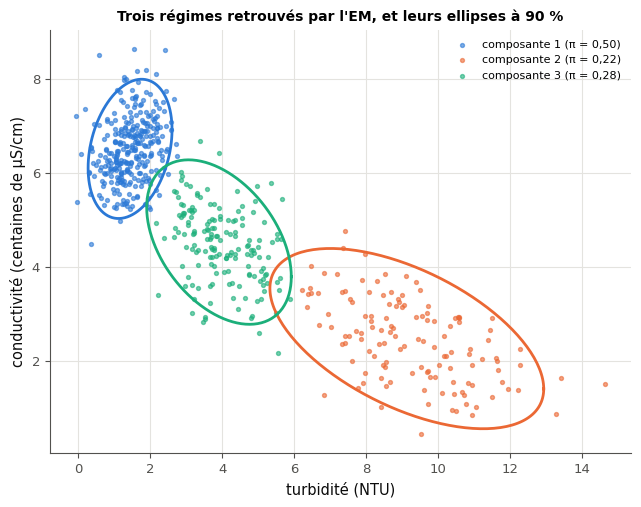

✅ Ex M25b.30 : les mesures et les trois ellipses à 90 % sont dessinées.


In [49]:
gmm_e_step, gmm_m_step = mymath.latent.gmm_e_step, mymath.latent.gmm_m_step
gmm_log_likelihood = mymath.latent.gmm_log_likelihood


def fit_gmm_30(X, K, n_init, n_iter, reg, seed):
    """(weights, means, covs) of a mixture of K Gaussians fitted to X by EM with your mymath.latent: n_init
    initializations (rng = np.random.default_rng(seed); for each, the means on K distinct measures
    X[rng.choice(n, K, replace=False)], each covariance the global covariance of X (bias=True) plus reg times the
    identity, equal weights), at most n_iter iterations of EM with the regularization reg, stopped when the
    log-likelihood moves by less than 1e-8 |ℓ|; returns the initialization of best training log-likelihood."""
    X = np.asarray(X, dtype=float)
    rng, (n, d) = np.random.default_rng(seed), X.shape
    best, best_ll = None, -np.inf
    for _ in range(n_init):
        params = (np.full(K, 1 / K), X[rng.choice(n, K, replace=False)],
                  np.tile(np.cov(X, rowvar=False, bias=True) + reg * np.eye(d), (K, 1, 1)))
        ll = -np.inf
        for _ in range(n_iter):
            params = gmm_m_step(X, gmm_e_step(X, *params), reg=reg)
            new_ll = gmm_log_likelihood(X, *params)
            if abs(new_ll - ll) < 1e-8 * abs(new_ll):
                ll = new_ll
                break
            ll = new_ll
        if ll > best_ll:
            best, best_ll = params, ll
    return best


def draw_fit_30(ax, X, weights, means, covs):
    """In ax: the measures X (a scatter), coloured by the component of largest responsibility, and the 90 % ellipse of
    each component (the image of the circle of radius c, c² = 2 ln 10, by ε ↦ μ_k + L_k ε, at least 50 points);
    labels and a legend. No other axes."""
    labels = np.argmax(gmm_e_step(X, weights, means, covs), axis=1)
    circle = math.sqrt(2 * math.log(10)) * np.vstack([np.cos(np.linspace(0, 2 * np.pi, 201)),
                                                      np.sin(np.linspace(0, 2 * np.pi, 201))])
    for k in range(len(weights)):
        ax.scatter(X[labels == k, 0], X[labels == k, 1], s=8, color=f"C{k}", alpha=0.6,
                   label=f"composante {k + 1} (π = {weights[k]:.2f})".replace(".", ","))
        ellipse = means[k][:, None] + np.linalg.cholesky(covs[k]) @ circle
        ax.plot(ellipse[0], ellipse[1], color=f"C{k}", linewidth=2)
    ax.set_xlabel("turbidité (NTU)")
    ax.set_ylabel("conductivité (centaines de µS/cm)")
    ax.set_title("Trois régimes retrouvés par l'EM, et leurs ellipses à 90 %", fontsize=10)
    ax.legend(fontsize=8)


weights_30, means_30, covs_30 = fit_gmm_30(X_TRAIN_30, 3, **SETTINGS_30)
print("poids", np.round(weights_30, 3).tolist(), "; moyennes", np.round(means_30, 2).tolist())
print("log-vraisemblance moyenne : entraînement", round(gmm_log_likelihood(X_TRAIN_30, weights_30, means_30, covs_30) / 600, 4),
      "; test", round(gmm_log_likelihood(X_TEST_30, weights_30, means_30, covs_30) / 400, 4))

fitted_30 = None
with checked("M25b.30"):
    TRUE_C30 = (np.array([0.5, 0.3, 0.2]), np.array([[1.5, 6.5], [4.0, 4.5], [9.0, 2.5]]),
                np.array([[[0.3, 0.1], [0.1, 0.5]], [[1.0, -0.3], [-0.3, 0.6]], [[3.0, -0.8], [-0.8, 0.8]]]))

    def valid_c30(result, K, name="fit_gmm_30"):
        """The fit as three float arrays of the right shapes, finite, of weights summing to 1 and SPD covariances; else
        one ❌ line and StopCheck."""
        w, m, C = pair("M25b.30", name, result, names=("weights", "means", "covs"))
        try:
            w, m, C = (np.asarray(v, dtype=float) for v in (w, m, C))
        except (TypeError, ValueError):
            verdict("M25b.30", False, "", f"{name} doit rendre trois tableaux de nombres (weights, means, covs).")
            raise StopCheck from None
        if w.shape != (K,) or m.shape != (K, 2) or C.shape != (K, 2, 2) or not all(np.all(np.isfinite(v)) for v in (w, m, C)):
            verdict("M25b.30", False, "", f"{name} doit rendre des tableaux finis de formes ({K},), ({K}, 2) et ({K}, 2, 2) ; "
                    f"reçu {w.shape}, {m.shape} et {C.shape}.")
            raise StopCheck
        if np.any(w <= 0) or abs(w.sum() - 1) > 1e-9 or not all(np.all(np.linalg.eigvalsh((c + c.T) / 2) > 0) for c in C):
            verdict("M25b.30", False, "", f"{name} : des poids positifs de somme 1 et des covariances définies positives, "
                    "s'il te plaît.")
            raise StopCheck
        return w, m, C

    def matched_c30(fit, truth):
        """The fit with its components renumbered like the truth (the permutation of the closest means), and the gaps."""
        import itertools
        best = min(itertools.permutations(range(3)), key=lambda p: np.abs(fit[1][list(p)] - truth[1]).max())
        w, m, C = (v[list(best)] for v in fit)
        return (w, m, C), (np.abs(w - truth[0]).max(), np.abs(m - truth[1]).max(), np.abs(C - truth[2]).max())

    with own_code("M25b.30", "fit_gmm_30", REF_LATENT):
        result_c30 = fit_gmm_30(X_TRAIN_30.copy(), 3, **SETTINGS_30)
    fit_c30 = valid_c30(result_c30, 3)
    test_c30 = scipy_log_likelihood(X_TEST_30, *fit_c30) / len(X_TEST_30)
    exact_c30 = scipy_log_likelihood(X_TEST_30, *TRUE_C30) / len(X_TEST_30)
    print(f"a) ta log-vraisemblance moyenne de test : {fr(test_c30, 4)} ; b) celle du modèle exact : {fr(exact_c30, 4)}")
    passed_c30 = test_c30 >= THRESHOLD_30
    verdict("M25b.30", passed_c30, f"critère atteint : {fr(test_c30, 4)} ≥ {fr(THRESHOLD_30, 2)}.",
            f"critère pas encore atteint : {fr(test_c30, 4)} < {fr(THRESHOLD_30, 2)}.")
    (w_c30, m_c30, C_c30), (dw_c30, dm_c30, dC_c30) = matched_c30(fit_c30, TRUE_C30)
    dll_c30 = abs(test_c30 - exact_c30)
    lead_c30 = "le critère est atteint, mais " if passed_c30 else "de plus, "
    if dw_c30 <= 0.05 and dm_c30 <= 0.3 and dC_c30 <= 0.4 and dll_c30 <= 0.02:
        print(f"✅ Ex M25b.30 : ton ajustement est celui du modèle exact, aux fluctuations de l'échantillon près (poids à "
              f"{fr(dw_c30, 3)}, moyennes à {fr(dm_c30, 2)}, covariances à {fr(dC_c30, 2)}, log-vraisemblance de test à "
              f"{fr(dll_c30, 4)}).")
    else:
        reasons_c30 = []
        if np.allclose(w_c30, 1 / 3, rtol=0, atol=1e-9):
            reasons_c30.append("tes poids sont restés égaux : le pas M met π_k = N_k / n")
        if np.allclose(C_c30[:, 0, 1], 0, rtol=0, atol=1e-12):
            reasons_c30.append("tes covariances sont diagonales : le pas M garde toute la covariance pondérée, termes hors "
                               "diagonale compris")
        ratio_c30 = np.trace(C_c30, axis1=1, axis2=2) / np.trace(TRUE_C30[2], axis1=1, axis2=2)
        if np.all(ratio_c30 < 0.75) and dC_c30 > 0.4:
            reasons_c30.append("tes covariances sont trop petites : le pas M divise par N_k, pas par n")
        if dw_c30 > 0.05:
            reasons_c30.append(f"tes poids s'écartent de ceux du modèle de {fr(dw_c30, 3)} (plus de 0,05)")
        if dm_c30 > 0.3:
            reasons_c30.append(f"tes moyennes s'écartent de celles du modèle de {fr(dm_c30, 2)} (plus de 0,3) : un moins bon "
                               "maximum local ? garde l'essai de meilleure log-vraisemblance d'entraînement")
        if dC_c30 > 0.4:
            reasons_c30.append(f"tes covariances s'écartent de celles du modèle de {fr(dC_c30, 2)} (plus de 0,4)")
        if dll_c30 > 0.02:
            reasons_c30.append(f"ta log-vraisemblance de test s'écarte de {fr(dll_c30, 4)} de celle du modèle exact (plus "
                               "de 0,02)")
        print(f"❌ Ex M25b.30 : {lead_c30}ton ajustement n'est pas celui du modèle exact, après la meilleure "
              "renumérotation des composantes : " + " ; ".join(dict.fromkeys(reasons_c30)) + ".")
    for K_c30 in (2, 6):
        with own_code("M25b.30", "fit_gmm_30", REF_LATENT):
            other_c30 = valid_c30(fit_gmm_30(X_TRAIN_30.copy(), K_c30, **SETTINGS_30), K_c30)
        print(f"c) à K = {K_c30} : log-vraisemblance moyenne de test {fr(scipy_log_likelihood(X_TEST_30, *other_c30) / 400, 4)}")
    fitted_30 = fit_c30

with checked("M25b.30"):
    hidden_c30 = (np.array([0.35, 0.4, 0.25]), np.array([[2.0, 3.0], [6.0, 7.5], [8.5, 3.5]]),
                  np.array([[[0.5, 0.2], [0.2, 0.4]], [[0.8, -0.2], [-0.2, 0.5]], [[0.6, 0.0], [0.0, 1.2]]]))
    z_c30 = np.random.default_rng(6075).choice(3, size=600, p=hidden_c30[0])
    X_hidden_c30 = np.empty((600, 2))
    for k_c30 in range(3):
        rows_c30 = np.flatnonzero(z_c30 == k_c30)
        X_hidden_c30[rows_c30] = ref_gauss.sample_mvn(hidden_c30[1][k_c30], hidden_c30[2][k_c30], len(rows_c30),
                                                      seed=6076 + k_c30)
    with own_code("M25b.30", "fit_gmm_30", REF_LATENT):
        hidden_fit_c30 = valid_c30(fit_gmm_30(X_hidden_c30, 3, **SETTINGS_30), 3)
    _, (dw_c30, dm_c30, dC_c30) = matched_c30(hidden_fit_c30, hidden_c30)
    verdict("M25b.30", dw_c30 <= 0.05 and dm_c30 <= 0.3 and dC_c30 <= 0.4,
            "un mélange que tu ne vois pas (trois autres régimes) est retrouvé aussi.",
            f"un mélange que tu ne vois pas (trois autres régimes) n'est pas retrouvé : poids à {fr(dw_c30, 3)}, moyennes à "
            f"{fr(dm_c30, 2)}, covariances à {fr(dC_c30, 2)} (tolérances 0,05, 0,3 et 0,4).")

with checked("M25b.30"):
    if fitted_30 is None:
        print("⏳ Ex M25b.30 : la figure attend un ajustement qui passe la vérification ci-dessus.")
        raise StopCheck
    fig_30, ax_30 = plt.subplots(figsize=(7.5, 5.5))
    try:
        opened_30 = drawn(draw_fit_30, ax_30, X_TRAIN_30.copy(), *(np.copy(v) for v in fitted_30))
    except BaseException:
        plt.close(fig_30)
        raise
    missing_30 = [] if has_points(ax_30, X_TRAIN_30) else ["il manque des mesures : un point par ligne de X_TRAIN_30"]
    missing_30 += [f"il manque l'ellipse à 90 % de la composante {k + 1} (au moins 50 points, Δ² = 2 ln 10)"
                   for k in range(3) if not ellipse_drawn(ax_30, fitted_30[1][k], fitted_30[2][k], 0.9)]
    if opened_30:
        missing_30.insert(0, "draw_fit_30 doit dessiner dans l'axe reçu, sans ouvrir de figure")
    plt.show()
    verdict("M25b.30", not missing_30, "les mesures et les trois ellipses à 90 % sont dessinées.", " ; ".join(missing_30))

**Pour aller plus loin** : la log-vraisemblance moyenne d'entraînement et de test selon $K$.

entraînement : [-3.8521, -3.3628, -3.2584, -3.2441, -3.2355, -3.2257]
test         : [-3.9185, -3.4741, -3.3661, -3.3731, -3.3794, -3.3977]


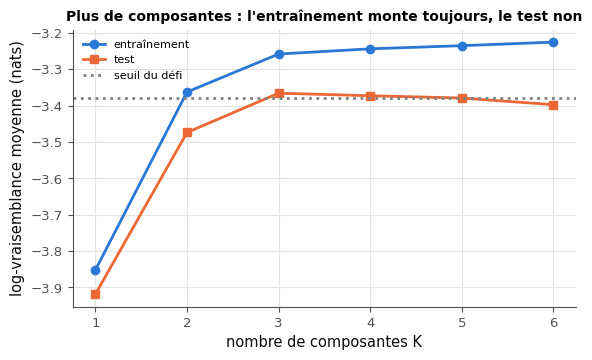

In [50]:
train_30, test_30 = [], []
for K_30 in range(1, 7):
    fit_K_30 = fit_gmm_30(X_TRAIN_30, K_30, **SETTINGS_30)
    train_30.append(gmm_log_likelihood(X_TRAIN_30, *fit_K_30) / 600)
    test_30.append(gmm_log_likelihood(X_TEST_30, *fit_K_30) / 400)
print("entraînement :", np.round(train_30, 4).tolist())
print("test         :", np.round(test_30, 4).tolist())
fig_k30, ax_k30 = plt.subplots(figsize=(6.5, 3.6))
ax_k30.plot(range(1, 7), train_30, "o-", label="entraînement")
ax_k30.plot(range(1, 7), test_30, "s-", label="test")
ax_k30.axhline(THRESHOLD_30, color="0.5", linestyle=":", label="seuil du défi")
ax_k30.set_xlabel("nombre de composantes K")
ax_k30.set_ylabel("log-vraisemblance moyenne (nats)")
ax_k30.set_title("Plus de composantes : l'entraînement monte toujours, le test non", fontsize=10)
ax_k30.legend(fontsize=8)
plt.show()

**Pour réfléchir** : pourquoi une petite régularisation (`reg = 1e-6`) suffit-elle ici, alors que la vraisemblance d'un mélange n'est pas bornée ? Que se passerait-il si une initialisation plaçait deux moyennes sur la même mesure ?

💡 Avec `n_init=5`, `n_iter=300`, `reg=1e-6`, `seed=6080` : a) $\approx -3{,}3661$ ; b) $-3{,}3604$ ; c) $\approx -3{,}4741$ à $K = 2$ (sous le seuil : deux régimes fusionnés) et $\approx -3{,}3977$ à $K = 6$ (des composantes qui se spécialisent sur des points d'entraînement). L'ajustement à $K = 3$ a des poids à 0,024 près, des moyennes à 0,14 près et des covariances à 0,15 près du modèle exact. Avec `reg=0.1`, la log-vraisemblance de test vaut encore $-3{,}3727$ et passe le critère.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu écrire la loi jointe d'un modèle à variable latente, en tirer un échantillon ancestral, et l'inverser par la règle de Bayes ?
2. Sais-tu calculer les responsabilités et la log-vraisemblance d'un mélange en log, sans jamais obtenir $0/0$, et dire pourquoi cette vraisemblance n'est pas bornée ?
3. Sais-tu écrire le pas M (diviser par $N_k$, la nouvelle moyenne) et expliquer pourquoi l'EM sans régularisation ne descend jamais ?
4. Sais-tu calculer une ELBO pour une loi $q$ quelconque, et lire son écart à la log-vraisemblance comme une somme de KL ?
5. Sais-tu ajuster une ACP probabiliste par ses valeurs propres, comparer deux sous-espaces par leurs angles principaux, et choisir le sens de la KL ?

**La suite** : M26, qui rappelle l'espérance conditionnelle et en fait un outil, puis le chapitre 25 de workbookIA, qui construit des modèles génératifs à variables latentes, écrit leur ELBO « reconstruction moins KL au prior », et dérive à travers des tirages.